In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 232,833
Discriminator parameters: 138,689
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.506588	G_loss: 1.246979
Epoch: 1 [6400/60000 (11%)]	D_loss: 0.770683	G_loss: 1.465310
Epoch: 1 [12800/60000 (21%)]	D_loss: 0.949137	G_loss: 1.575879
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.942385	G_loss: 1.151624
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.144828	G_loss: 1.421359
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.126544	G_loss: 0.838328
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.469253	G_loss: 0.511131
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.178593	G_loss: 1.037258
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.069083	G_loss: 1.248889
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.098869	G_loss: 0.837033
====> Epoch: 1 Train D_loss: 1.0082, Train G_loss: 1.1777
====> Epoch: 1 Val D_loss: 1.2225, Val G_loss: 0.8100
📈 Epoch 1 Summary:
   Train D Loss: 1.0082, Val D Loss: 1.2225
   Train G Loss: 1.1777, Val G Loss: 0.8100

📊 Epoch 2/100
------------------------

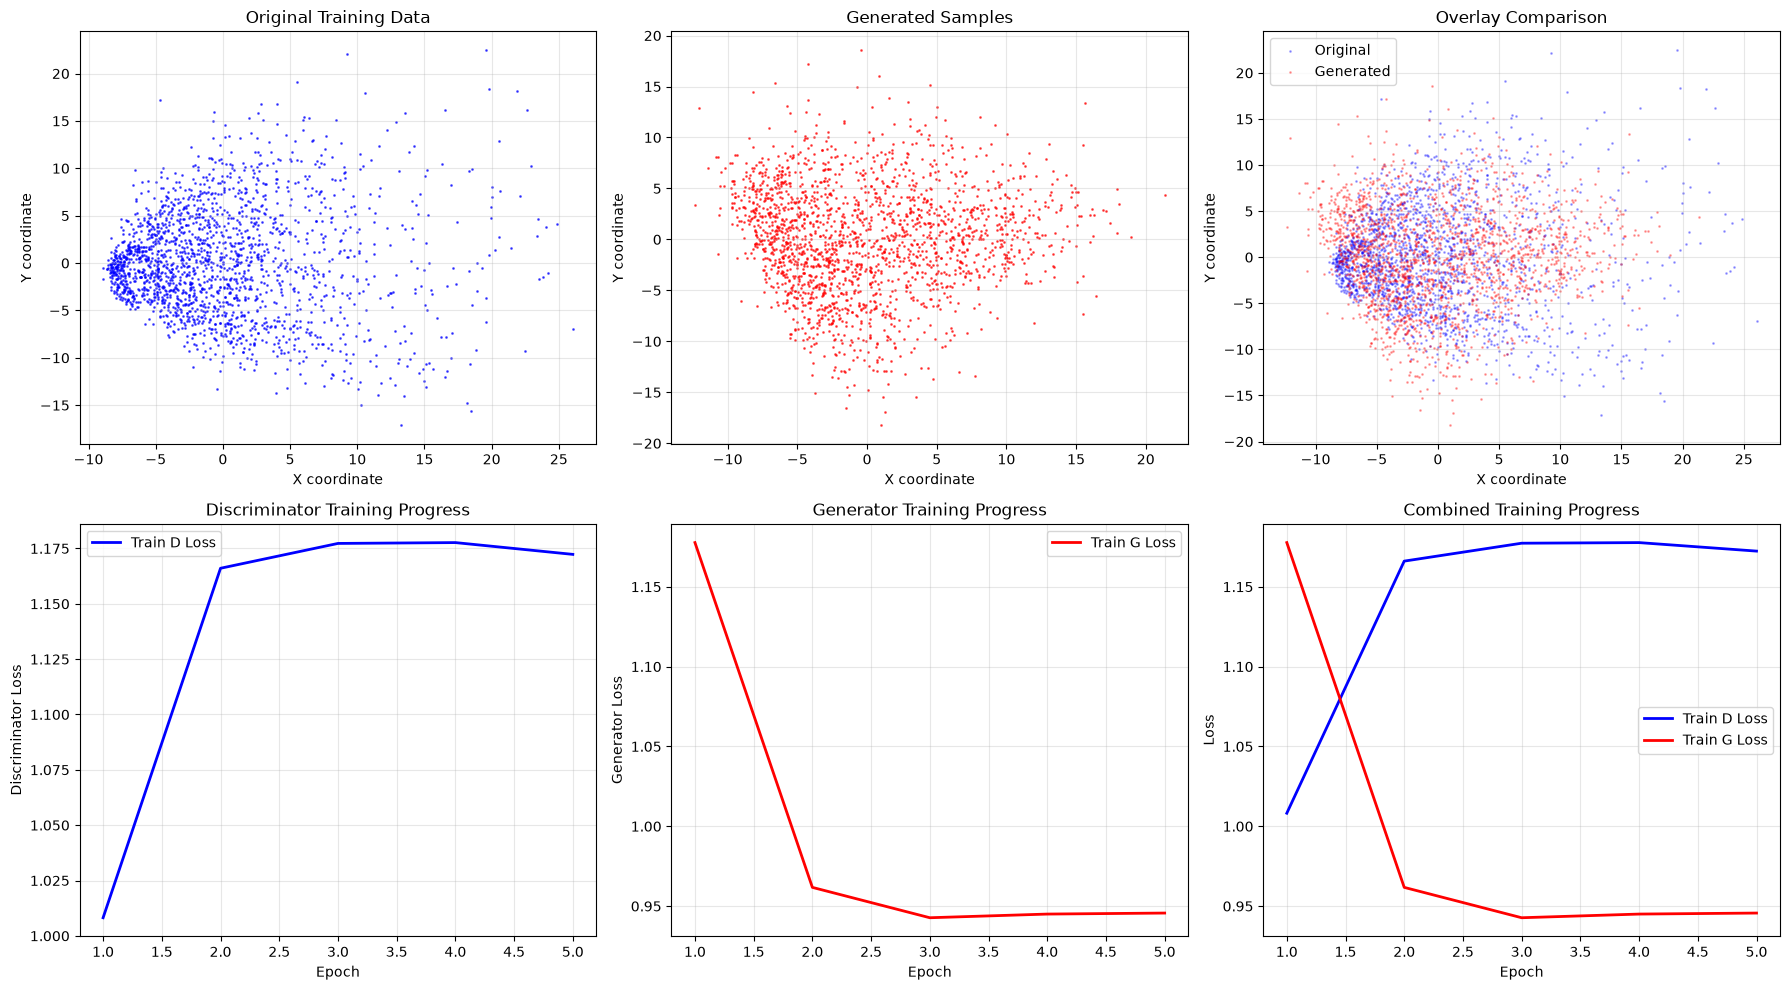

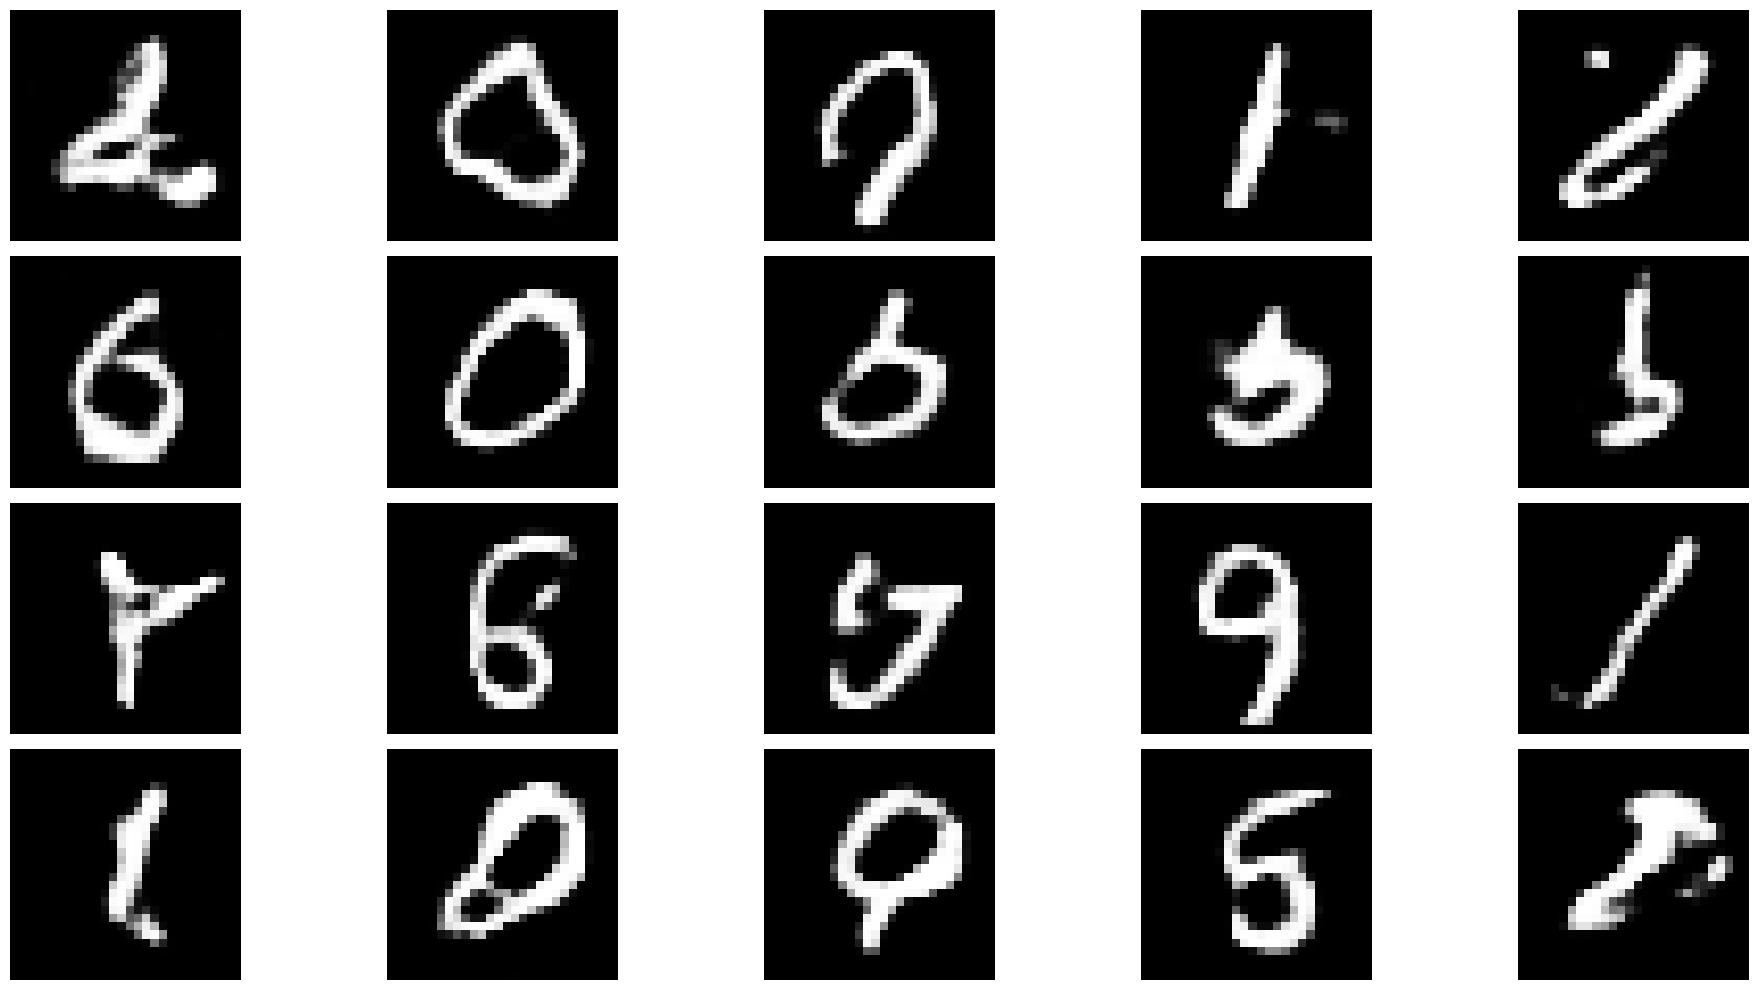

📈 Epoch 5 Summary:
   Train D Loss: 1.1723, Val D Loss: 1.2223
   Train G Loss: 0.9457, Val G Loss: 0.8371

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.207702	G_loss: 0.941960
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.178609	G_loss: 0.848800
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.221735	G_loss: 1.209148
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.158700	G_loss: 0.869890
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.131457	G_loss: 1.000742
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.182833	G_loss: 0.612305
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.295519	G_loss: 0.734985
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.083385	G_loss: 0.696423
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.136960	G_loss: 1.112396
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.784371	G_loss: 1.344856
====> Epoch: 6 Train D_loss: 1.1662, Train G_loss: 0.9607
====> Epoch: 6 Val D_loss: 1.3244, Val G_loss: 1.2109
📈 Epoch 6 Summary:
   Train D Loss: 1.1662, Val D Loss: 1.3244
   Train G Loss: 0.9607, Val G Loss: 1

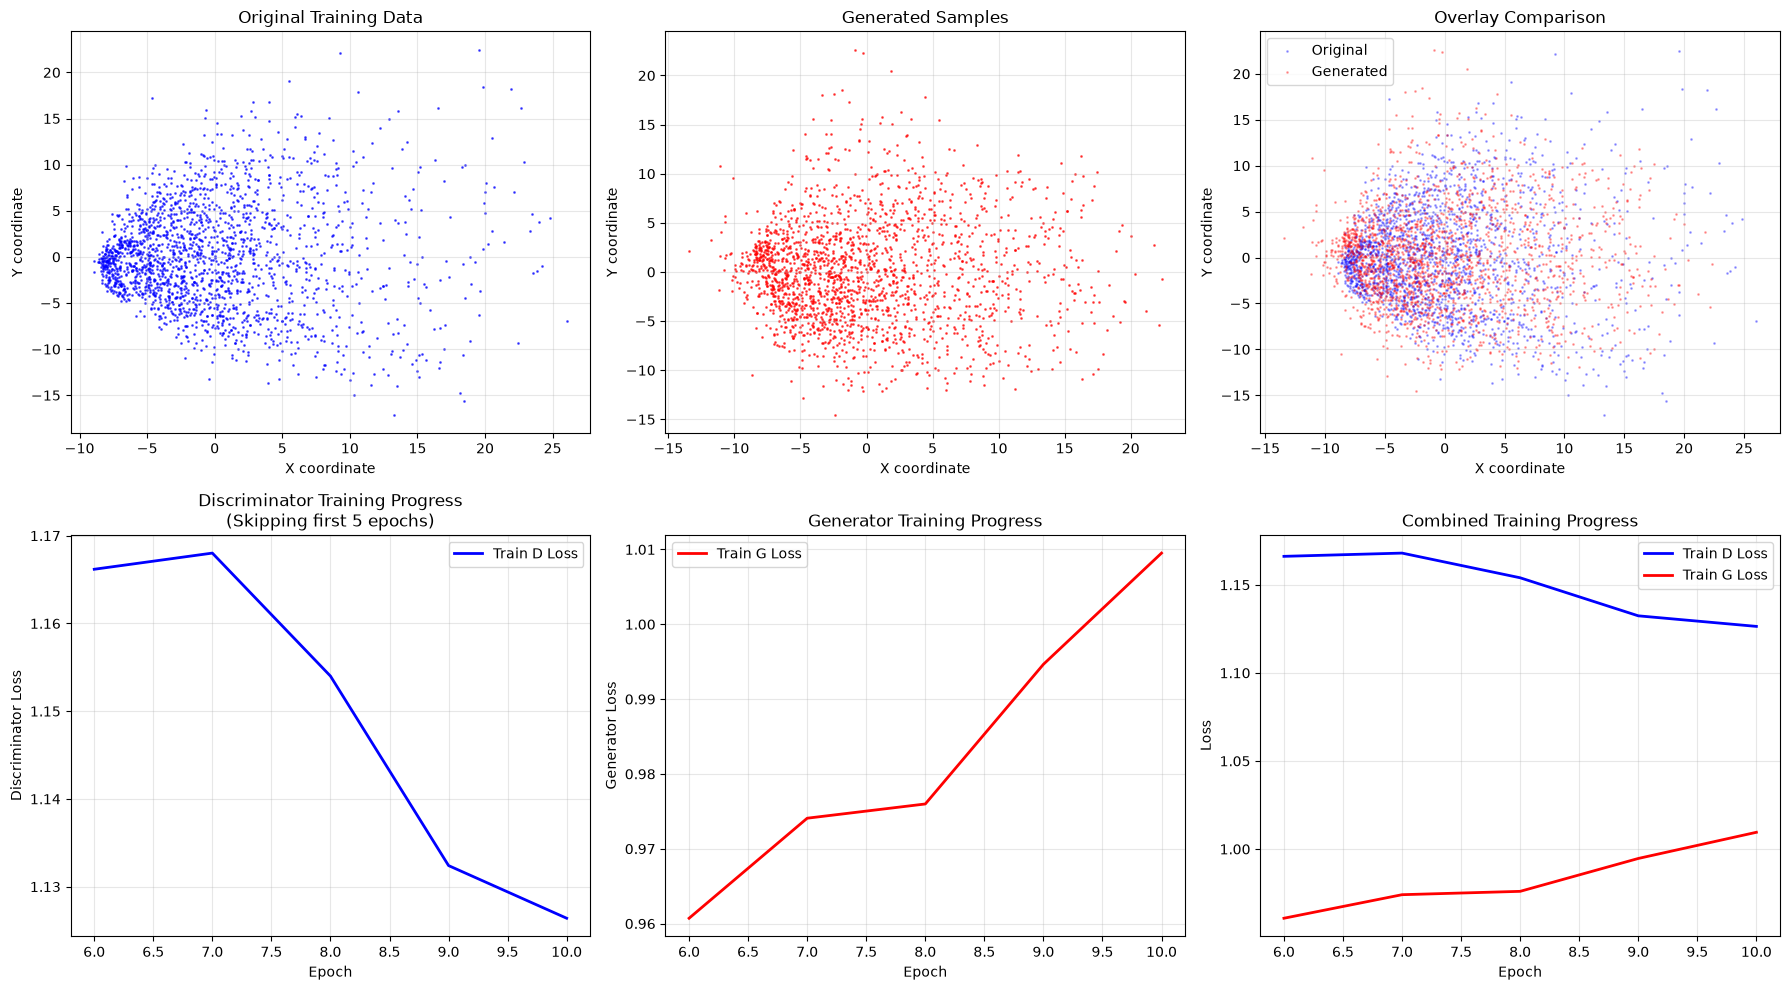

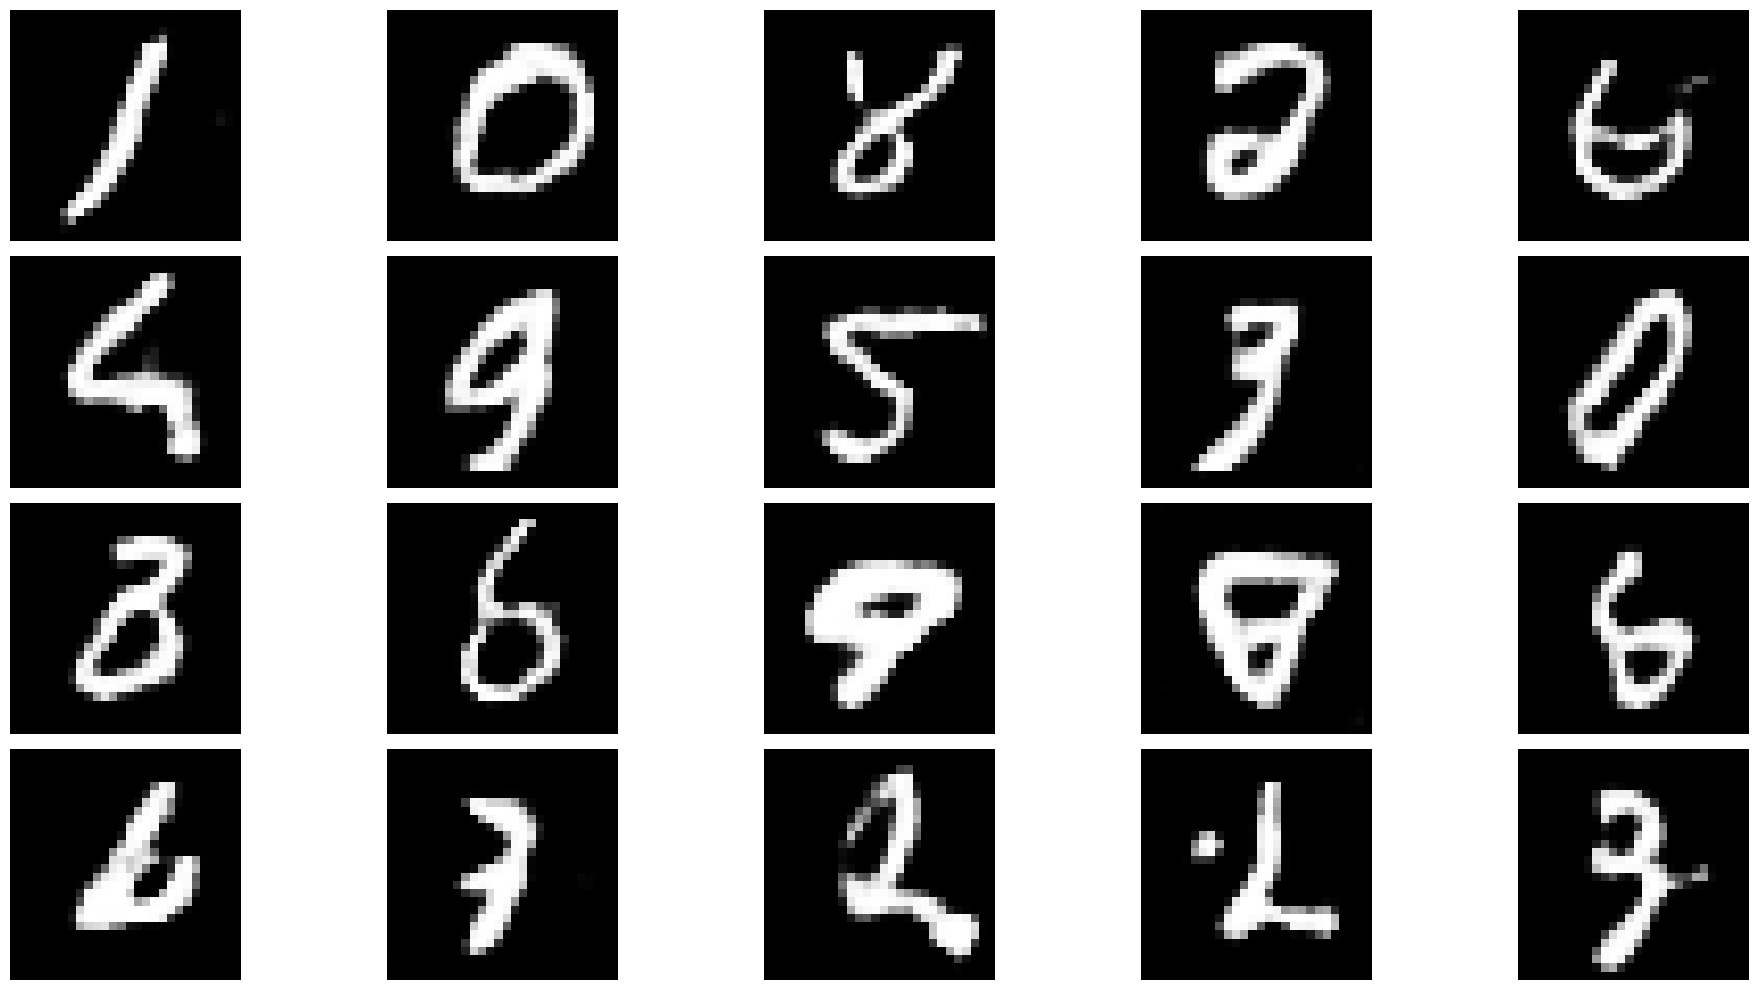

📈 Epoch 10 Summary:
   Train D Loss: 1.1264, Val D Loss: 1.2046
   Train G Loss: 1.0095, Val G Loss: 0.8136

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.086929	G_loss: 0.844701
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.035474	G_loss: 1.029549
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.066423	G_loss: 1.028840
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.116097	G_loss: 1.360647
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.080397	G_loss: 0.774939
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.019461	G_loss: 1.212321
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.063349	G_loss: 1.042757
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.016666	G_loss: 0.798030
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.128151	G_loss: 1.409446
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.349583	G_loss: 0.324465
====> Epoch: 11 Train D_loss: 1.1179, Train G_loss: 1.0293
====> Epoch: 11 Val D_loss: 1.2248, Val G_loss: 1.1328
📈 Epoch 11 Summary:
   Train D Loss: 1.1179, Val D Loss: 1.2248
   Train G Loss: 1.0293

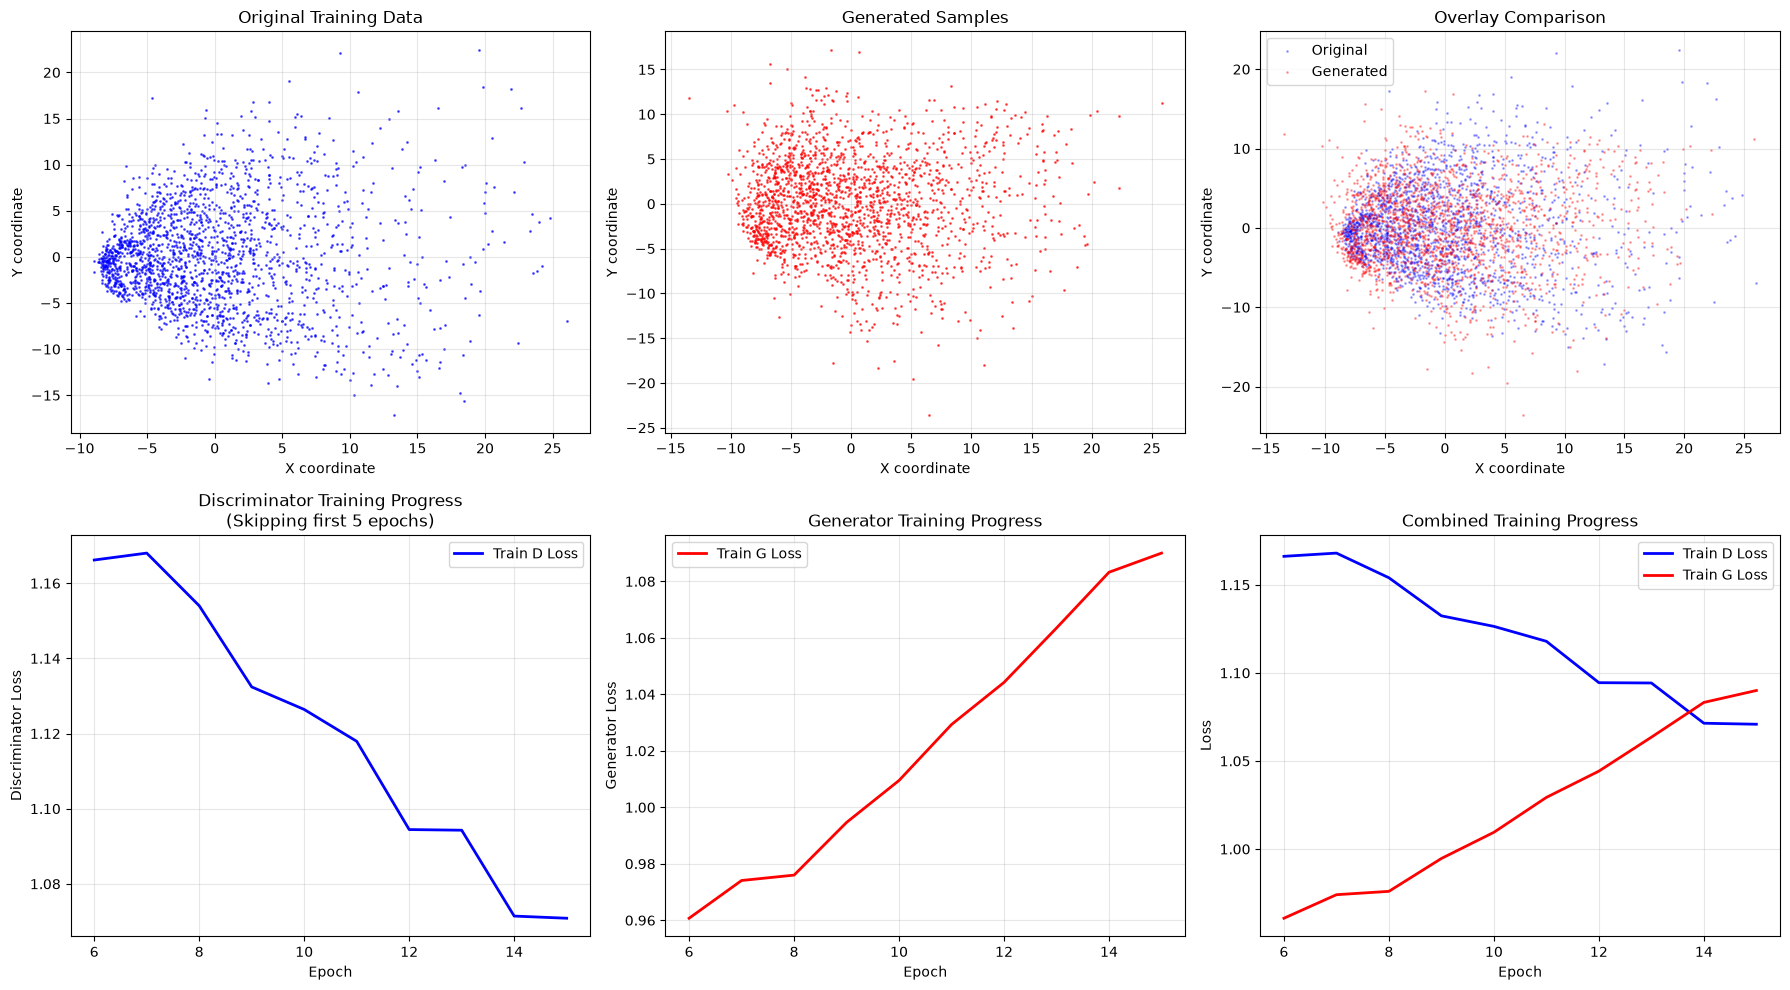

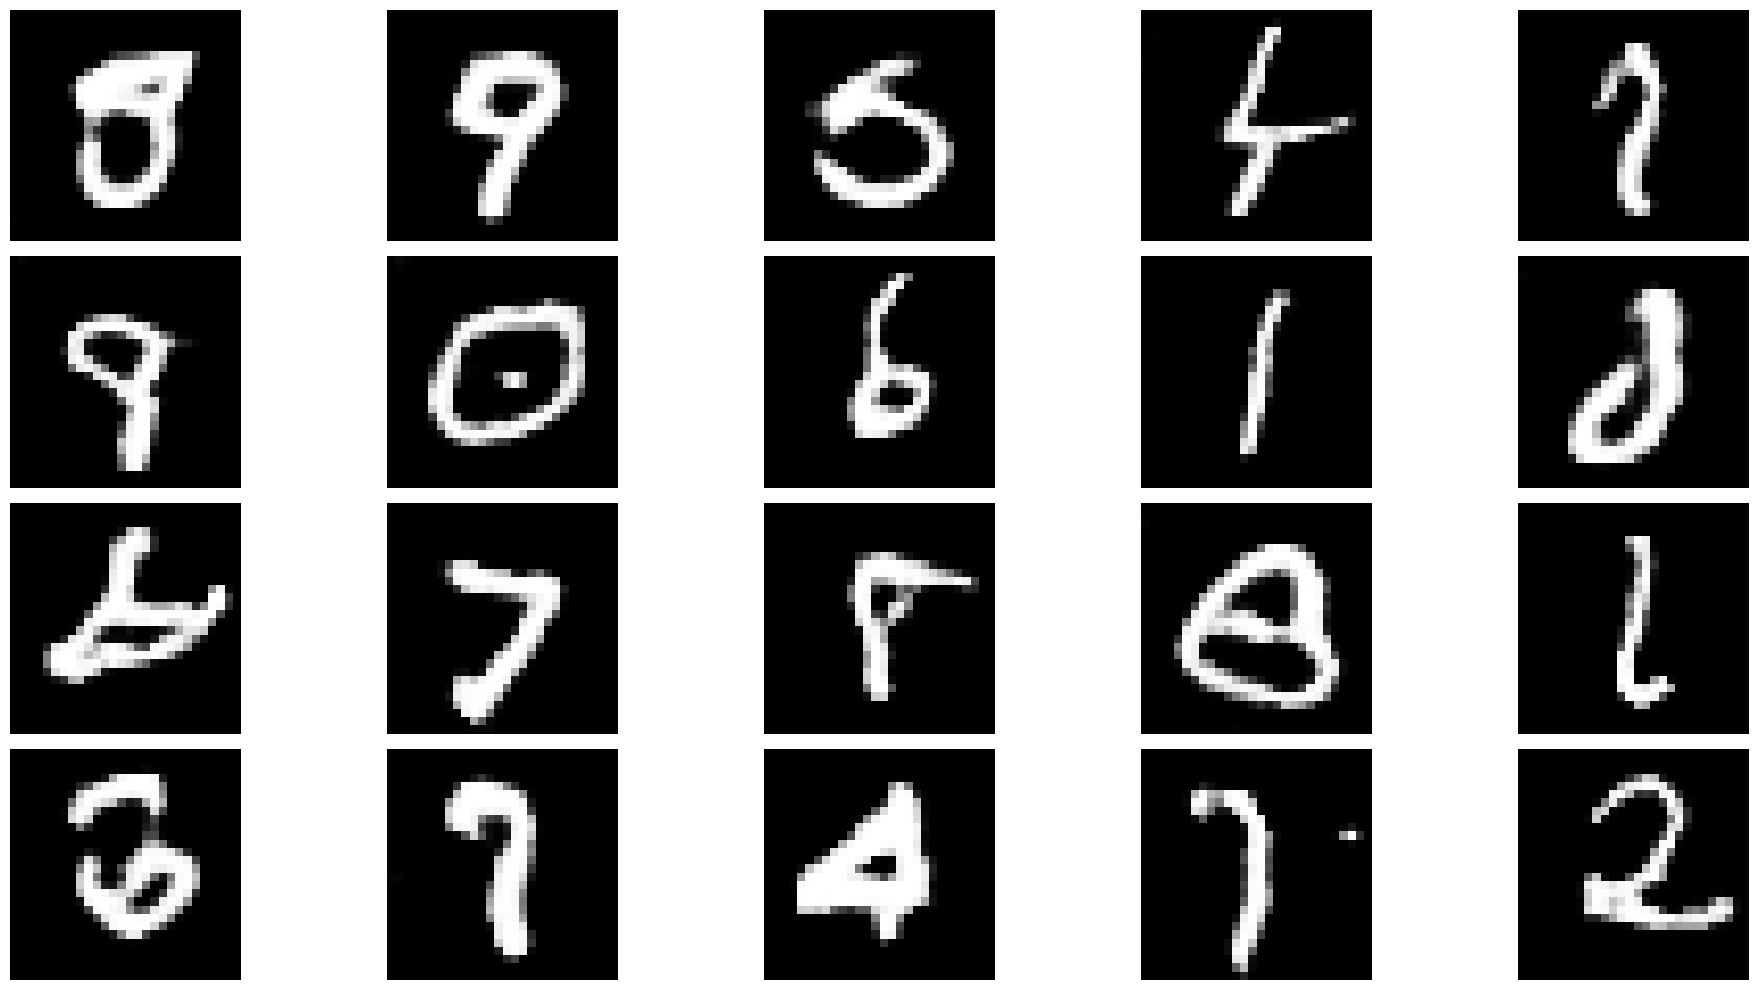

📈 Epoch 15 Summary:
   Train D Loss: 1.0709, Val D Loss: 1.2151
   Train G Loss: 1.0900, Val G Loss: 0.6824

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.144231	G_loss: 2.117171
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.022139	G_loss: 0.879835
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.003637	G_loss: 1.404236
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.085237	G_loss: 1.423394
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.097530	G_loss: 1.391091
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.015438	G_loss: 1.234553
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.935501	G_loss: 1.163462
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.930985	G_loss: 1.231170
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.032920	G_loss: 1.416770
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.041431	G_loss: 1.756366
====> Epoch: 16 Train D_loss: 1.0567, Train G_loss: 1.1122
====> Epoch: 16 Val D_loss: 1.3379, Val G_loss: 0.5100
📈 Epoch 16 Summary:
   Train D Loss: 1.0567, Val D Loss: 1.3379
   Train G Loss: 1.1122

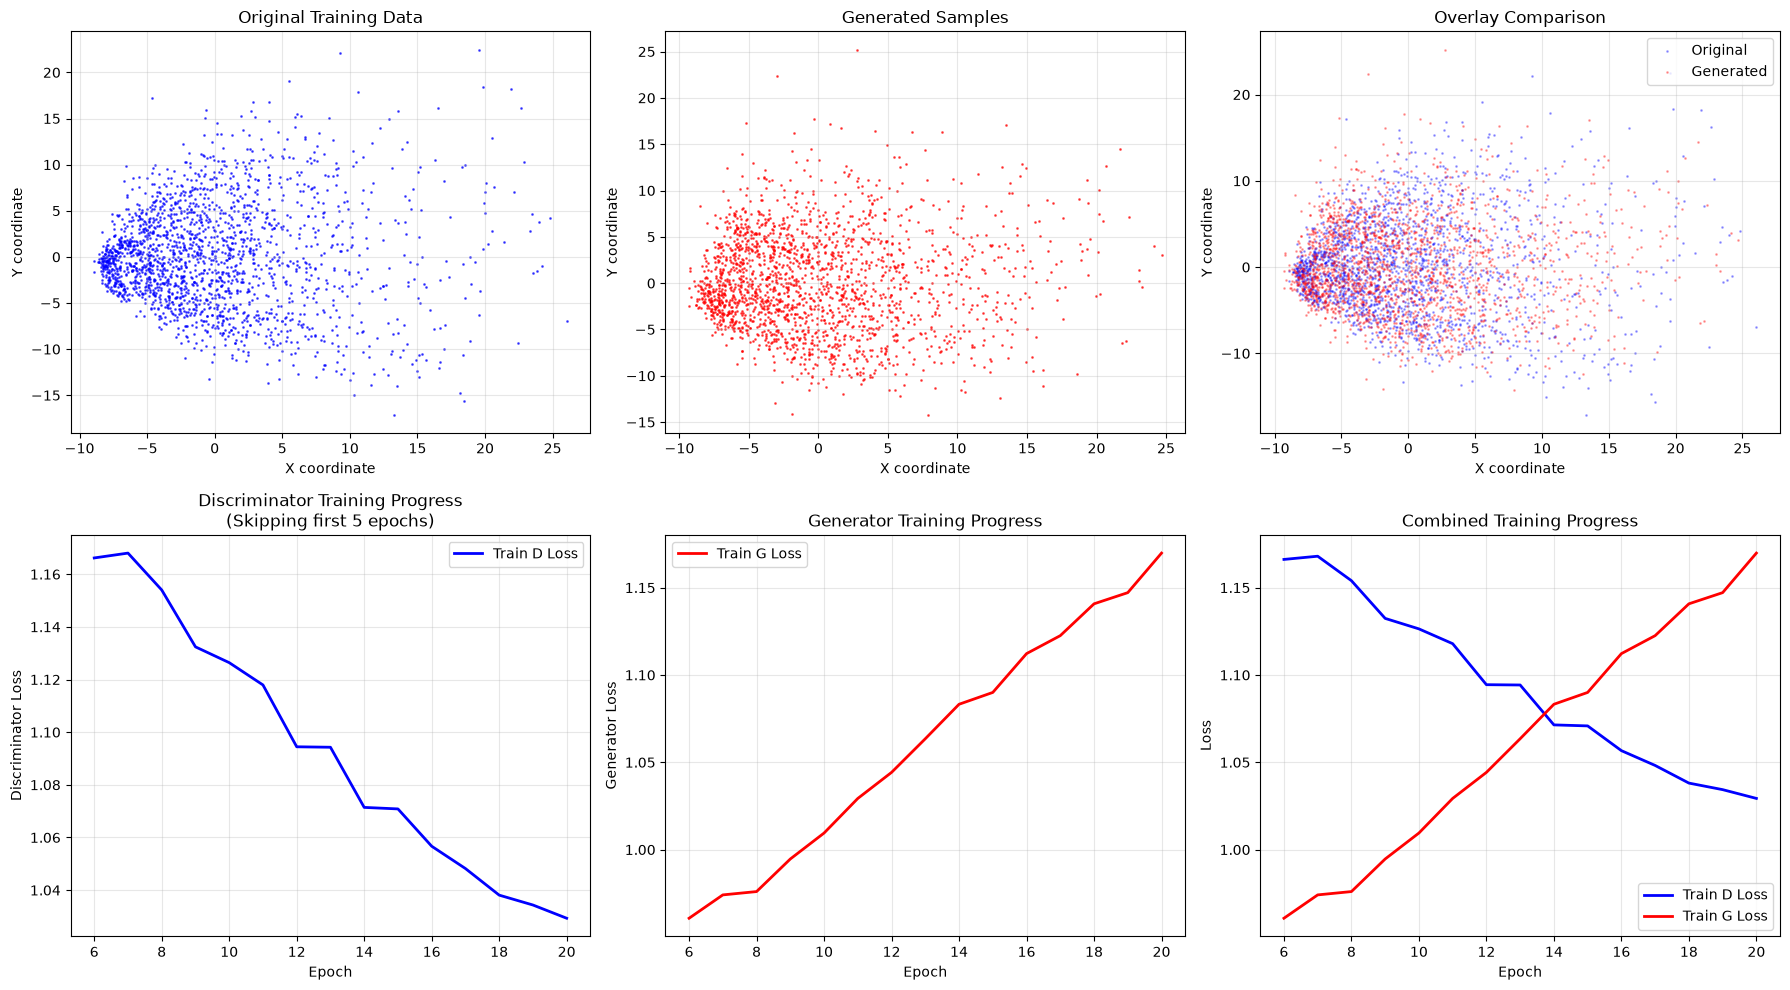

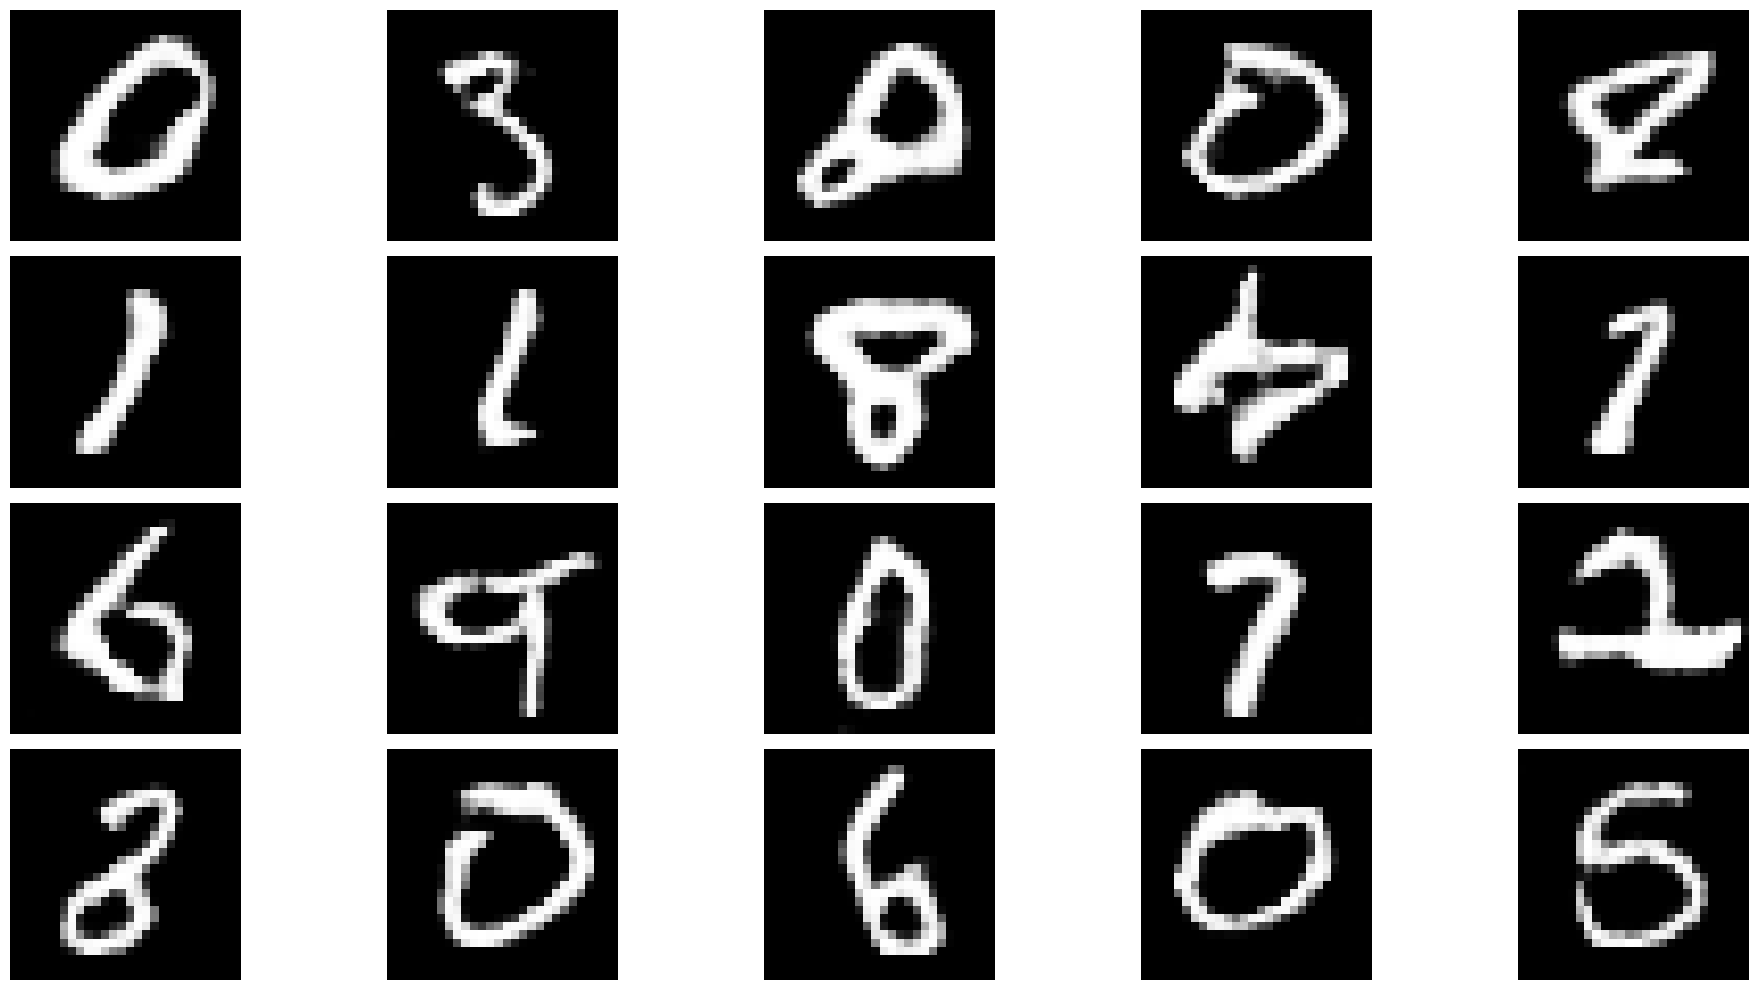

📈 Epoch 20 Summary:
   Train D Loss: 1.0293, Val D Loss: 1.1692
   Train G Loss: 1.1698, Val G Loss: 1.1650

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.859819	G_loss: 0.988264
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.008643	G_loss: 1.073691
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.958809	G_loss: 1.196426
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.110776	G_loss: 0.910719
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.864991	G_loss: 1.062378
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.046822	G_loss: 0.821444
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.987248	G_loss: 1.706823
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.067837	G_loss: 0.887299
Epoch: 21 [51200/60000 (85%)]	D_loss: 1.003302	G_loss: 1.722658
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.017112	G_loss: 1.429689
====> Epoch: 21 Train D_loss: 1.0278, Train G_loss: 1.1754
====> Epoch: 21 Val D_loss: 1.1904, Val G_loss: 1.1998
📈 Epoch 21 Summary:
   Train D Loss: 1.0278, Val D Loss: 1.1904
   Train G Loss: 1.1754

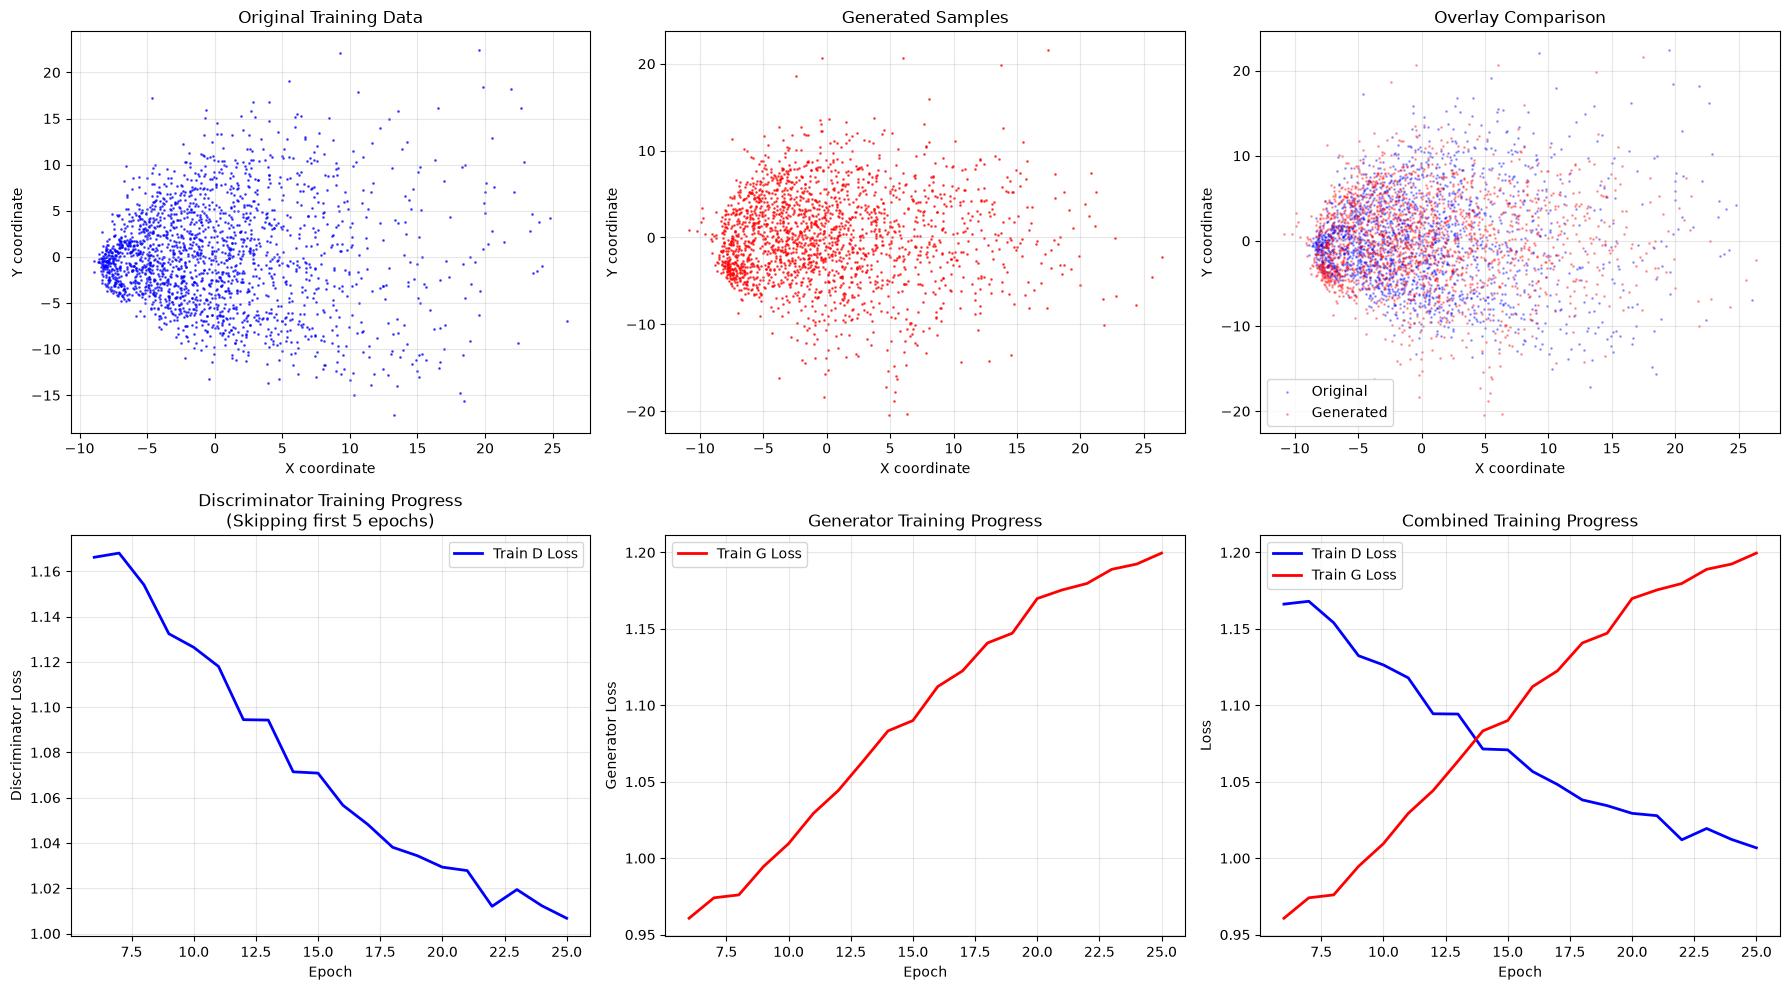

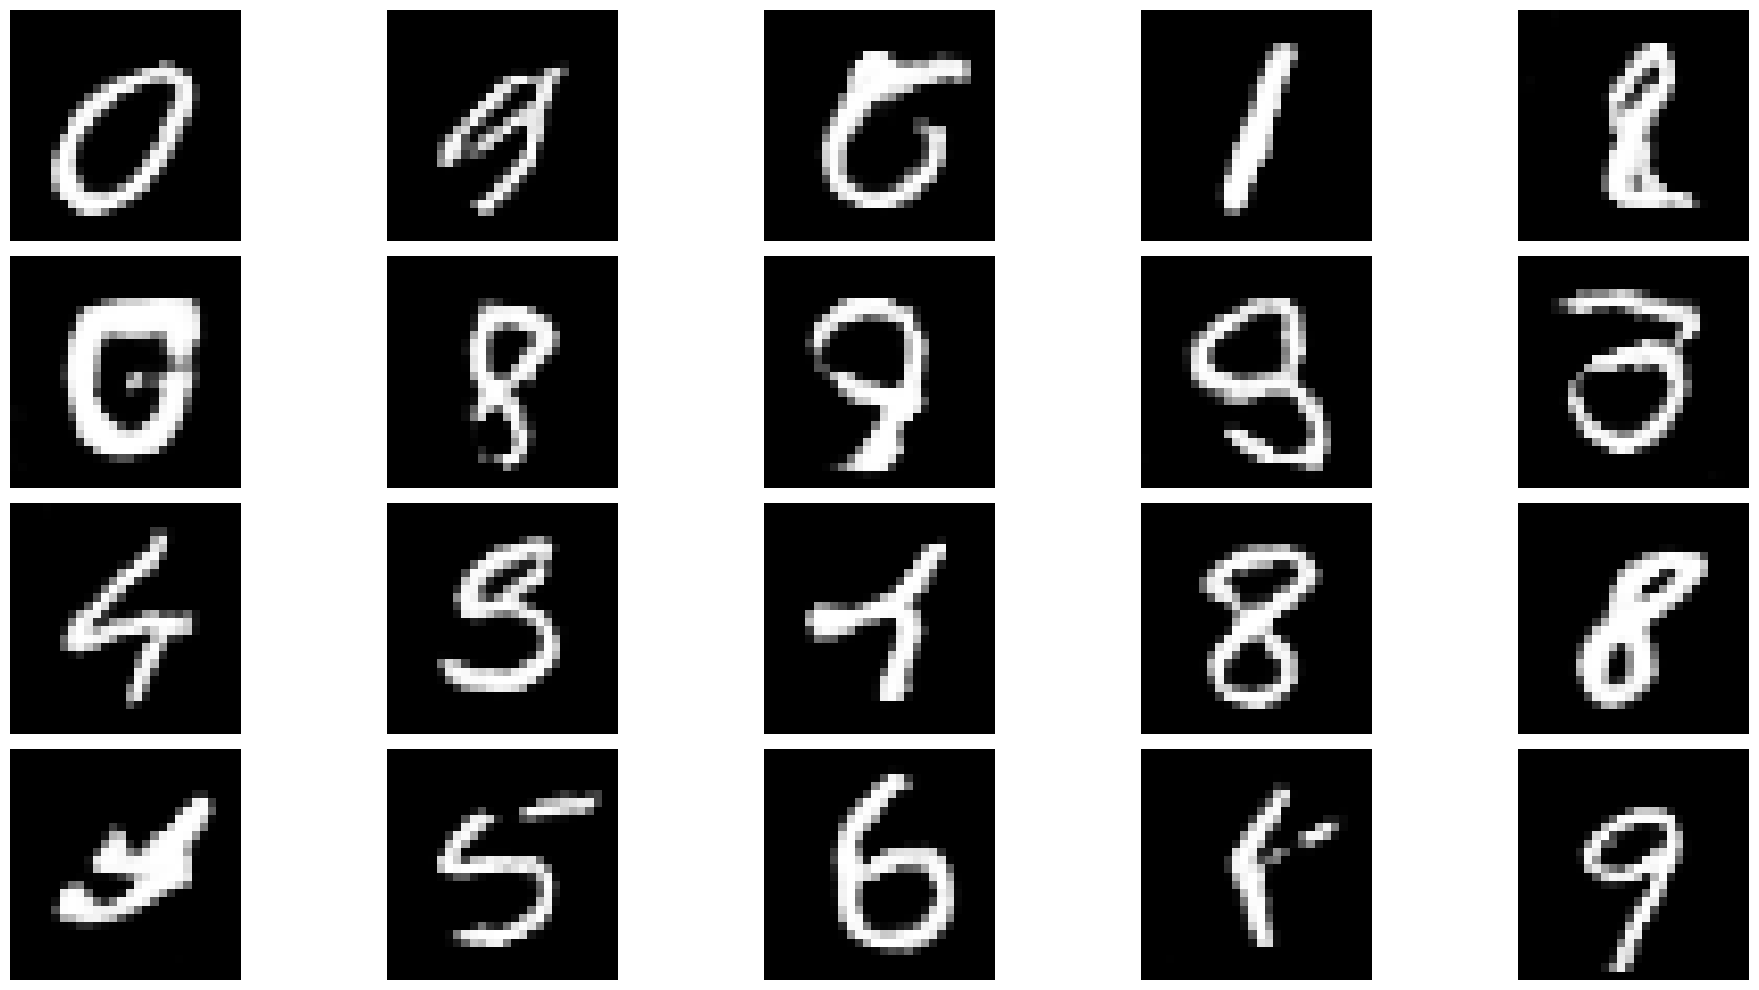

📈 Epoch 25 Summary:
   Train D Loss: 1.0068, Val D Loss: 1.2416
   Train G Loss: 1.1995, Val G Loss: 1.4452

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.992966	G_loss: 0.716406
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.924306	G_loss: 1.576324
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.849420	G_loss: 1.395184
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.948043	G_loss: 1.134393
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.000185	G_loss: 1.216954
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.072522	G_loss: 1.422456
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.004352	G_loss: 1.078901
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.112897	G_loss: 1.704571
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.070080	G_loss: 0.776998
Epoch: 26 [57600/60000 (96%)]	D_loss: 1.012304	G_loss: 1.662089
====> Epoch: 26 Train D_loss: 1.0042, Train G_loss: 1.2067
====> Epoch: 26 Val D_loss: 1.1592, Val G_loss: 1.1500
📈 Epoch 26 Summary:
   Train D Loss: 1.0042, Val D Loss: 1.1592
   Train G Loss: 1.2067

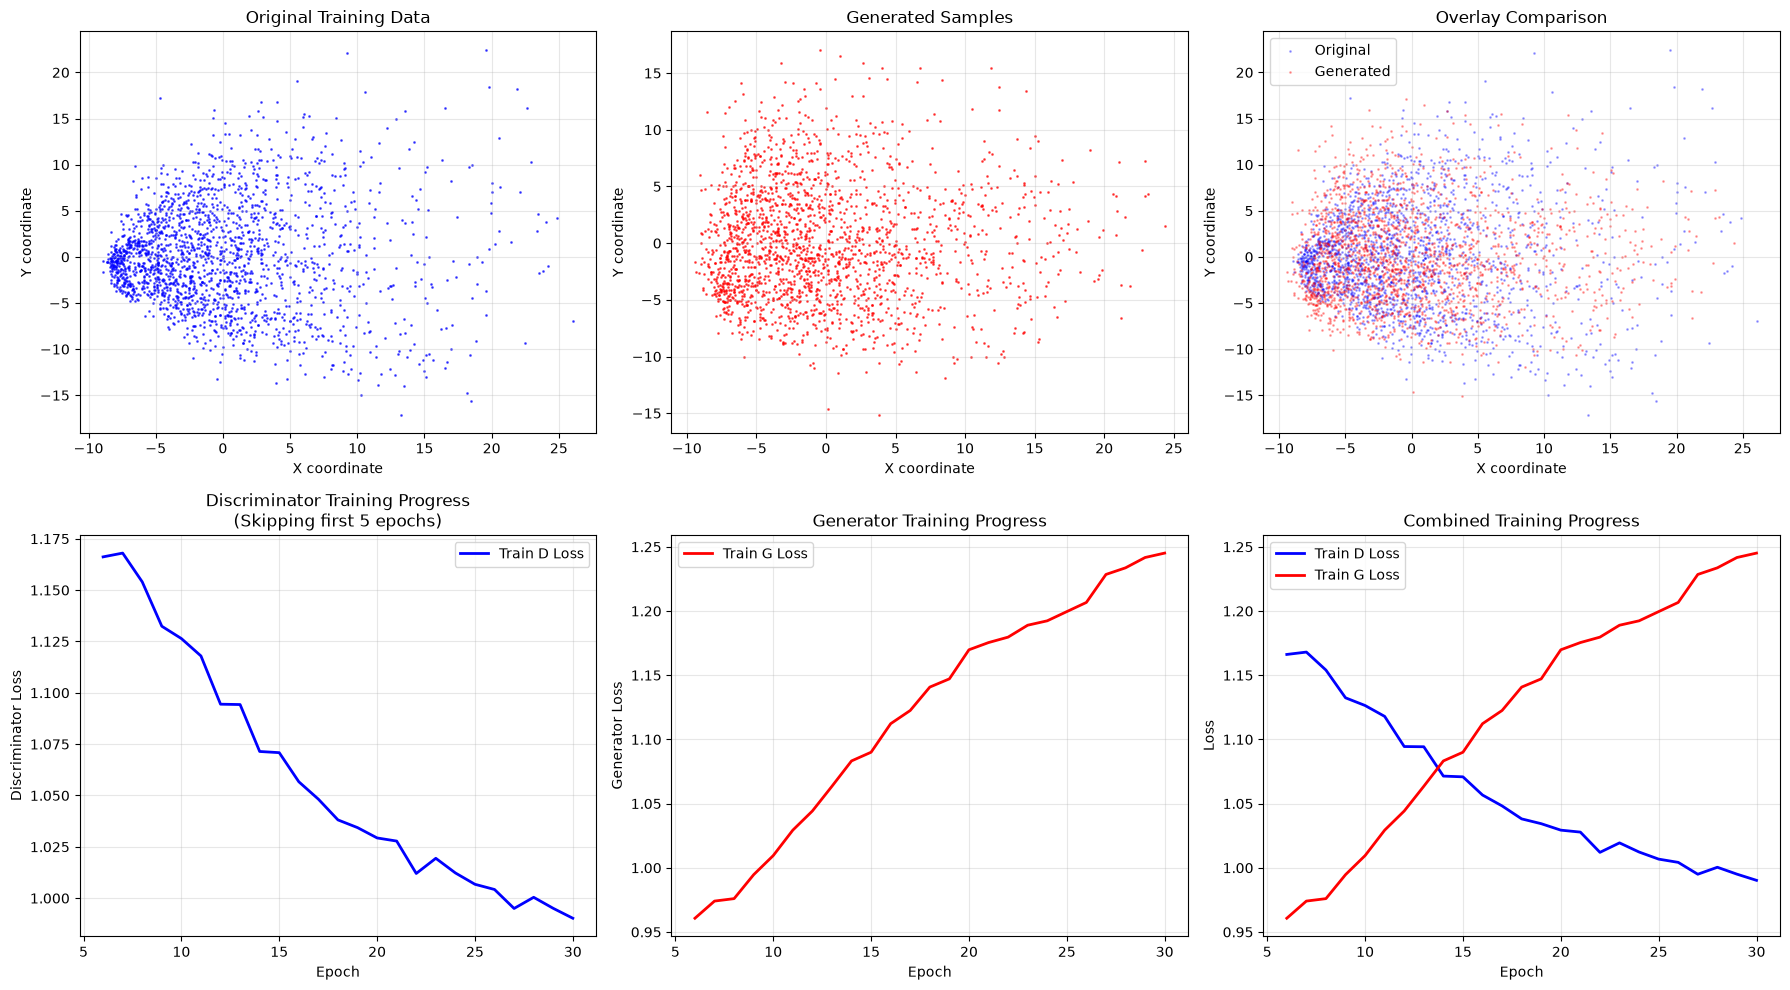

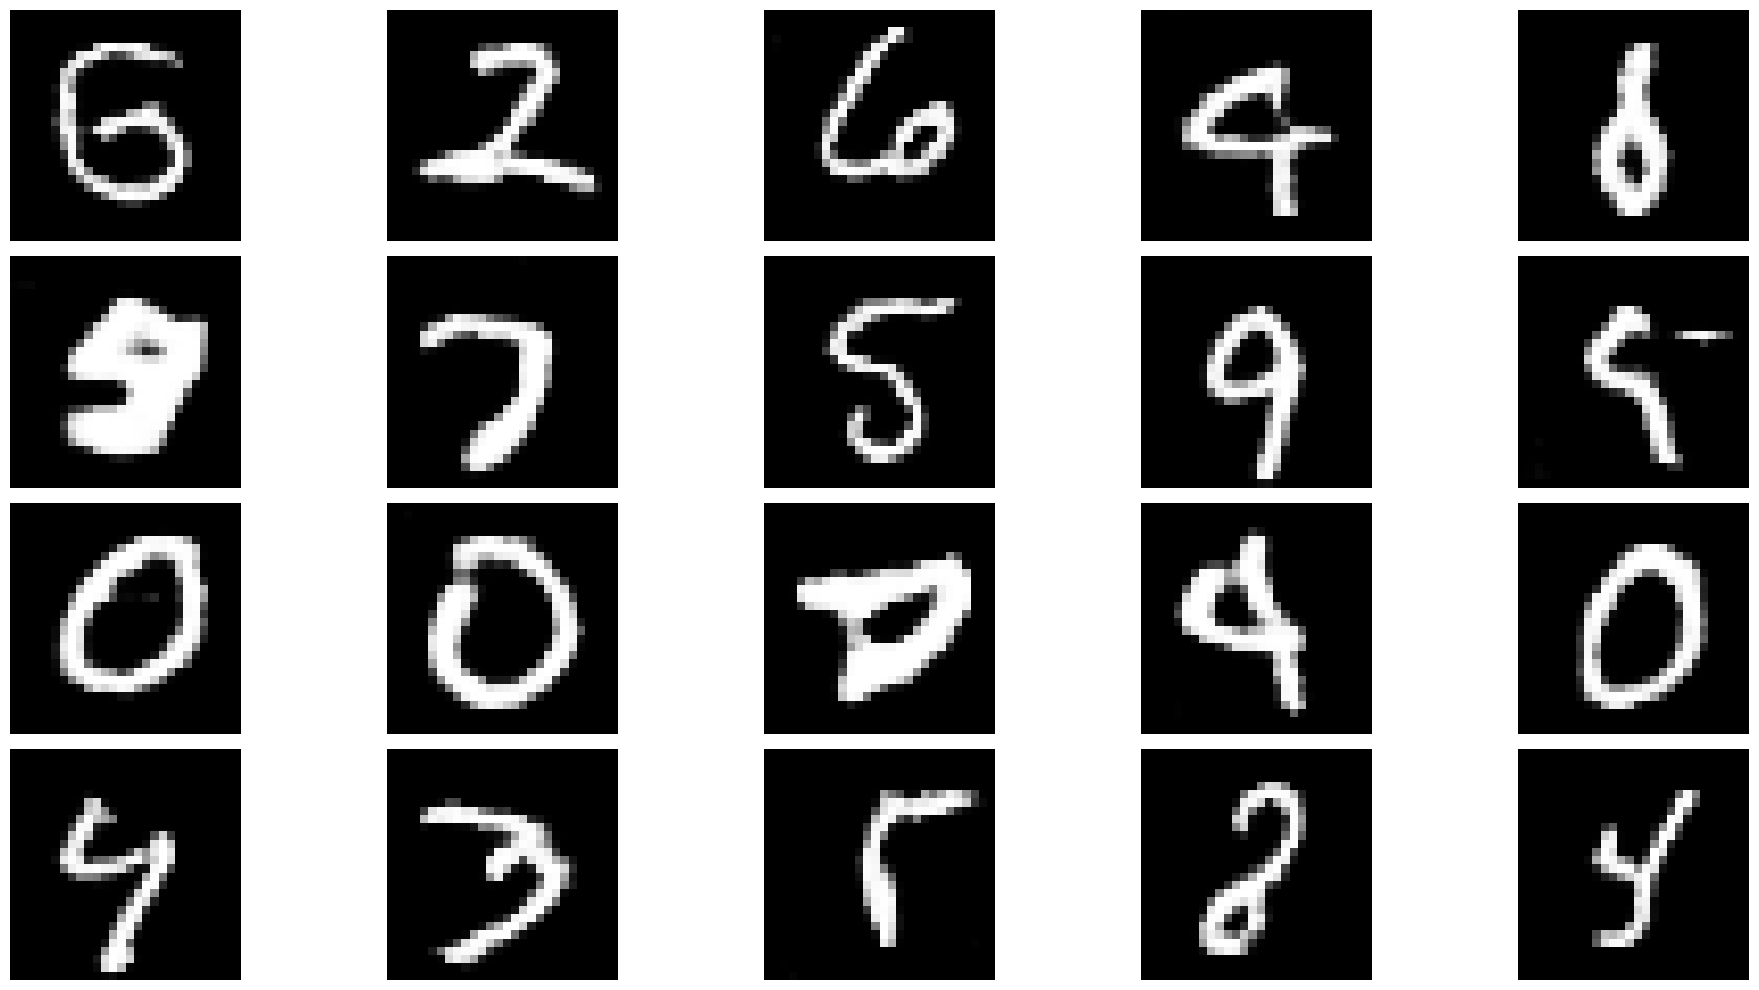

📈 Epoch 30 Summary:
   Train D Loss: 0.9902, Val D Loss: 2.2173
   Train G Loss: 1.2451, Val G Loss: 2.8885

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.569124	G_loss: 0.648183
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.939728	G_loss: 1.209228
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.981388	G_loss: 0.957915
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.951219	G_loss: 1.928674
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.914638	G_loss: 0.623657
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.961574	G_loss: 1.528249
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.090548	G_loss: 2.194015
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.870830	G_loss: 1.270894
Epoch: 31 [51200/60000 (85%)]	D_loss: 1.063481	G_loss: 1.080002
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.920875	G_loss: 0.842347
====> Epoch: 31 Train D_loss: 0.9861, Train G_loss: 1.2496
====> Epoch: 31 Val D_loss: 1.1710, Val G_loss: 1.3332
📈 Epoch 31 Summary:
   Train D Loss: 0.9861, Val D Loss: 1.1710
   Train G Loss: 1.2496

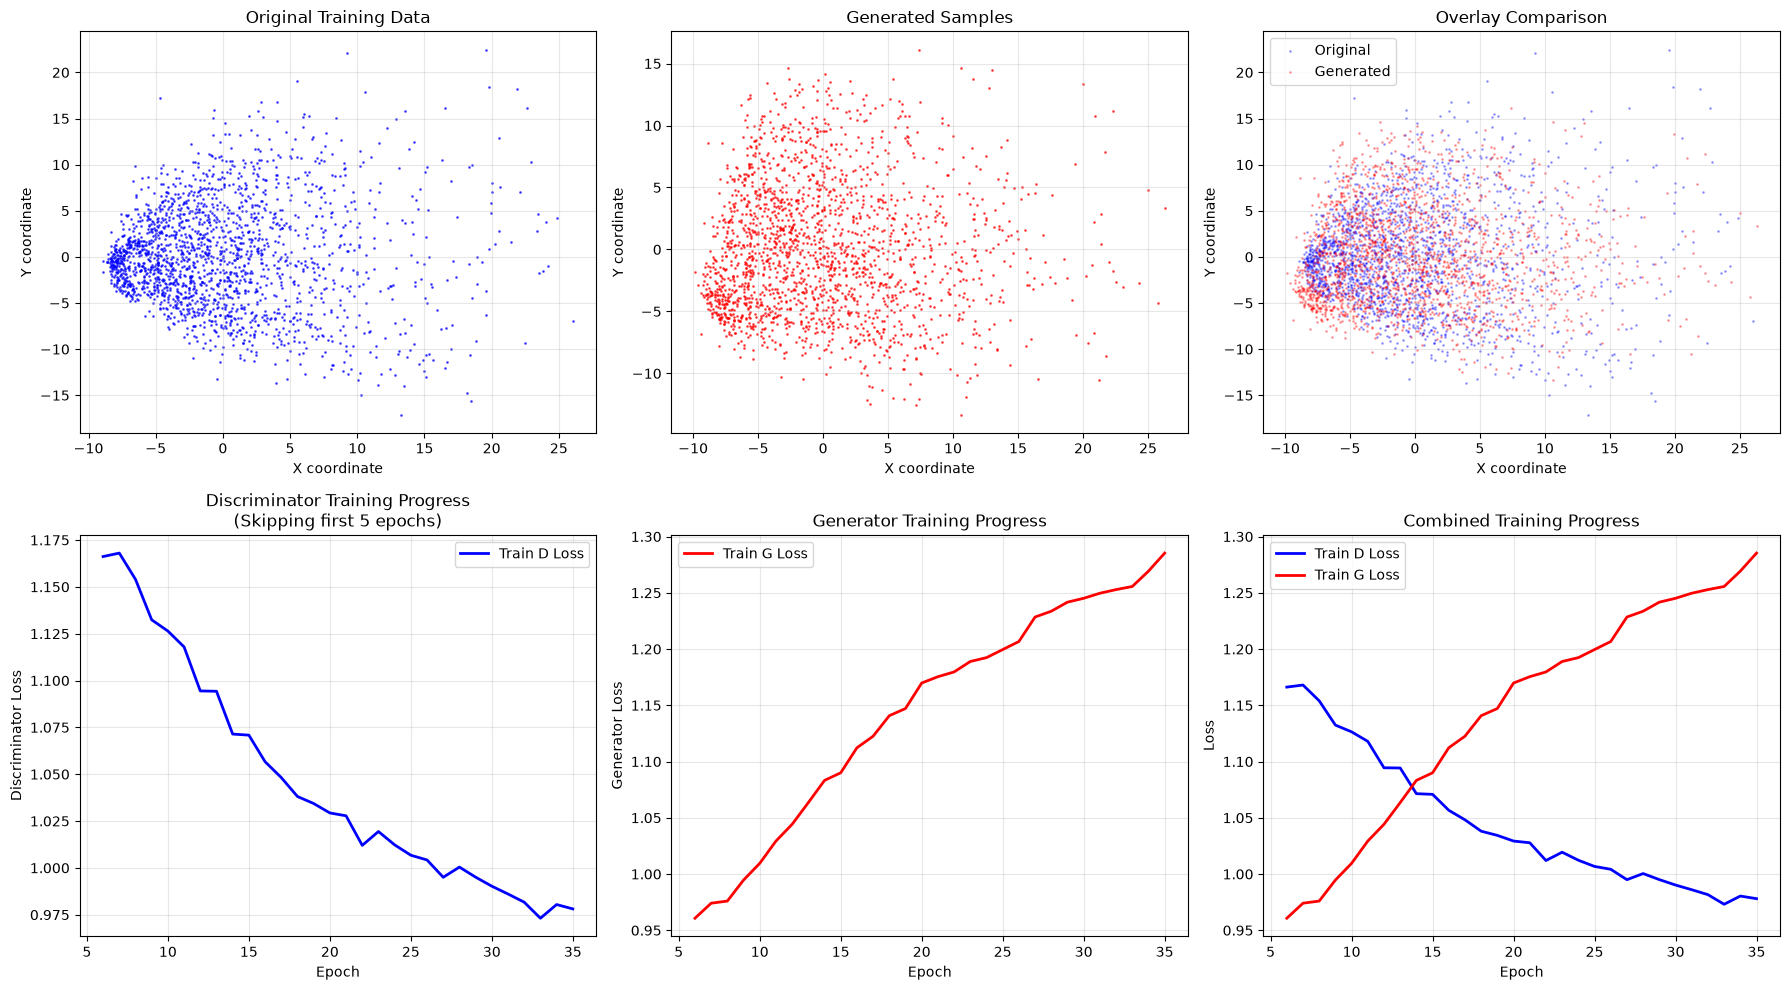

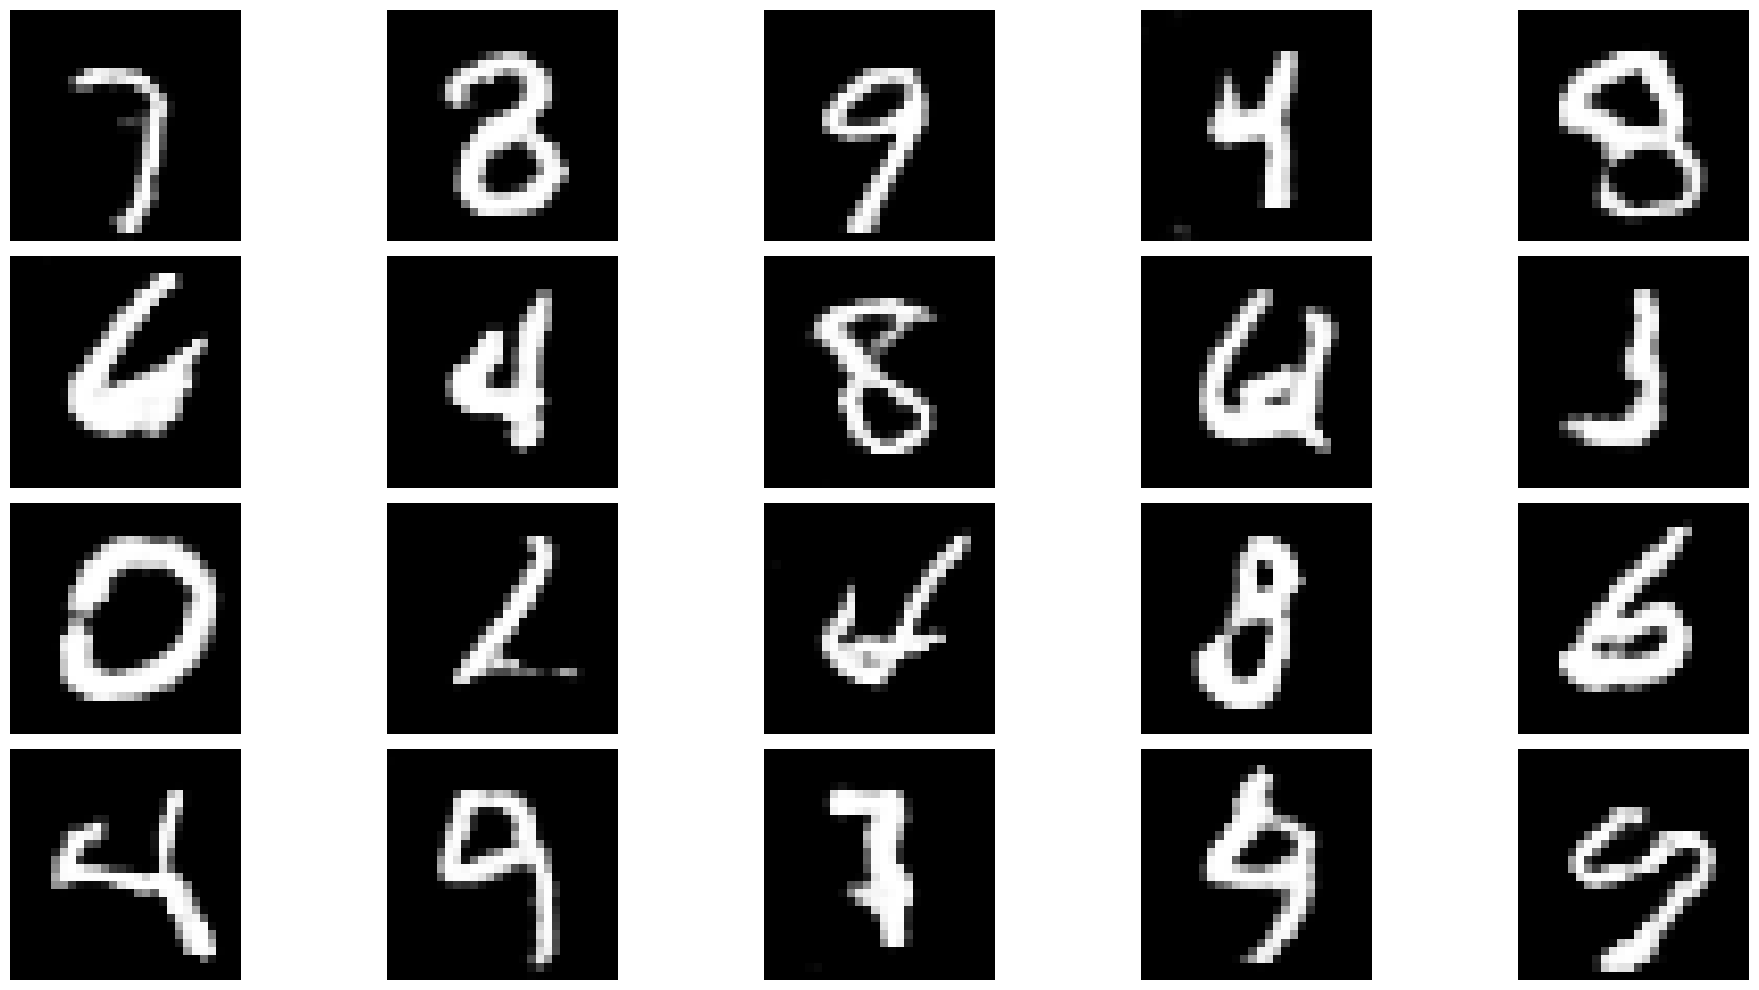

📈 Epoch 35 Summary:
   Train D Loss: 0.9781, Val D Loss: 1.1259
   Train G Loss: 1.2853, Val G Loss: 1.0662

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.927134	G_loss: 1.428652
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.959071	G_loss: 0.899822
Epoch: 36 [12800/60000 (21%)]	D_loss: 1.059410	G_loss: 0.900521
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.865776	G_loss: 1.249691
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.865017	G_loss: 1.220330
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.935091	G_loss: 1.167036
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.949979	G_loss: 1.453822
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.905578	G_loss: 1.652330
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.928329	G_loss: 1.078671
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.941090	G_loss: 1.051631
====> Epoch: 36 Train D_loss: 0.9700, Train G_loss: 1.2949
====> Epoch: 36 Val D_loss: 1.1295, Val G_loss: 1.0188
📈 Epoch 36 Summary:
   Train D Loss: 0.9700, Val D Loss: 1.1295
   Train G Loss: 1.2949

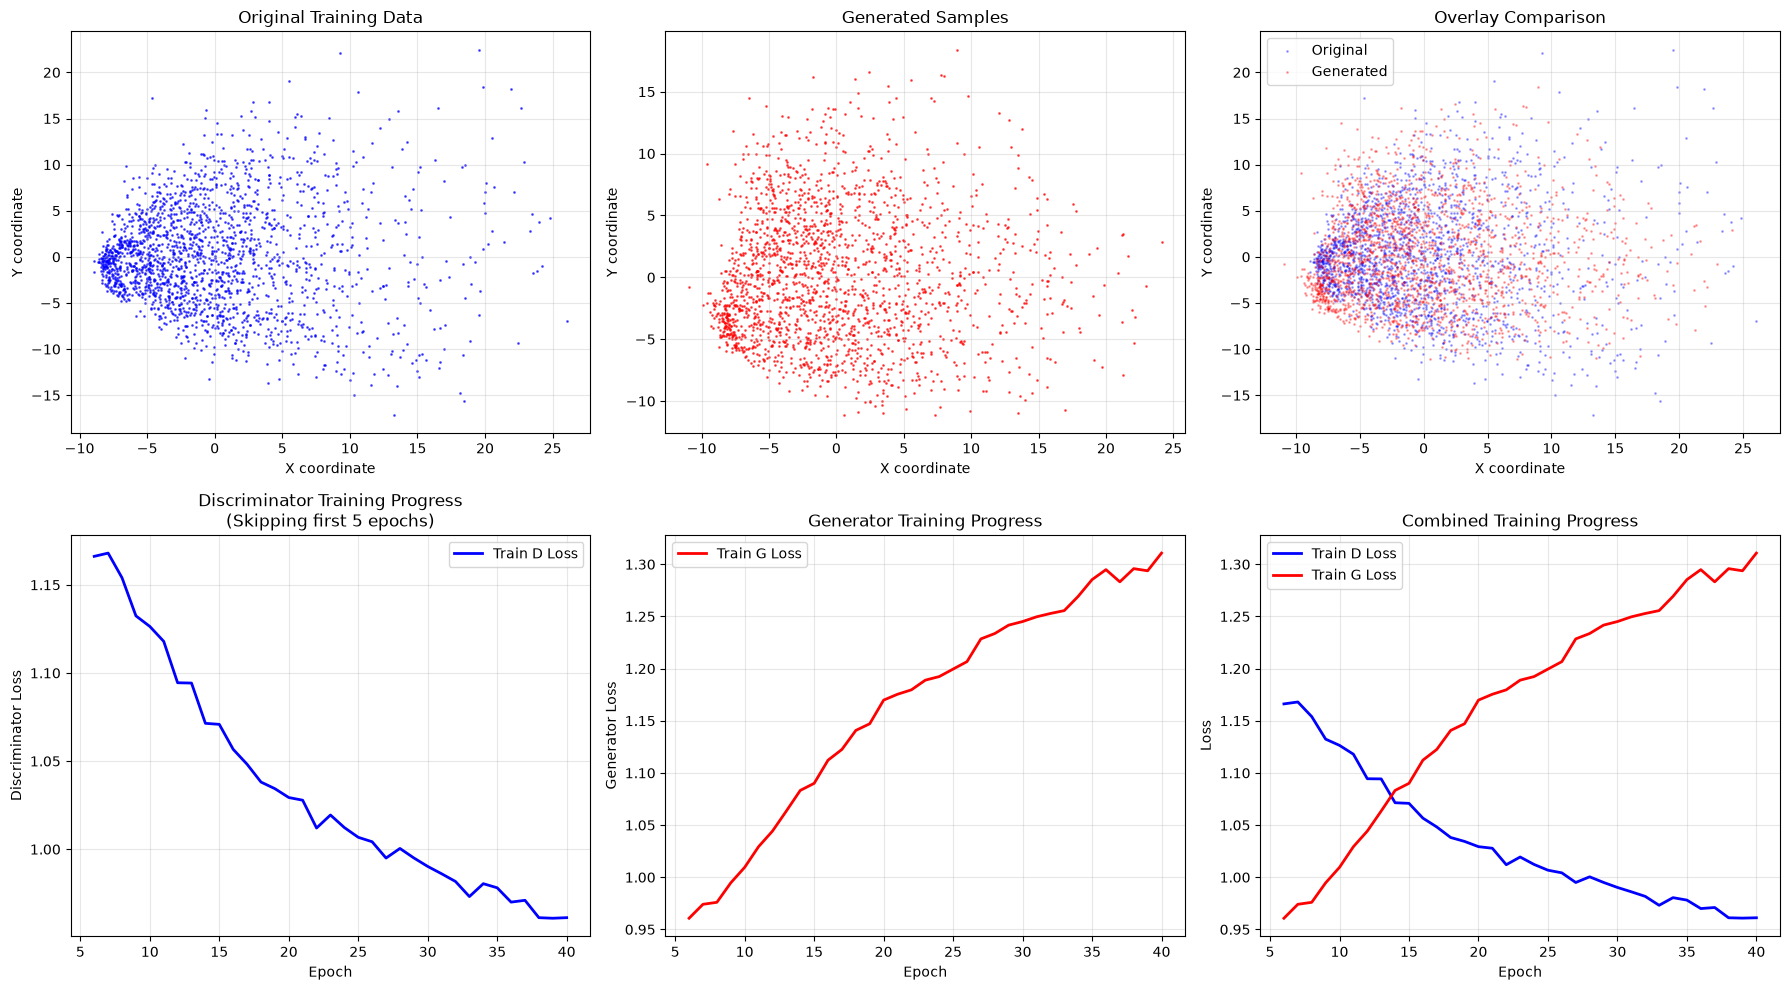

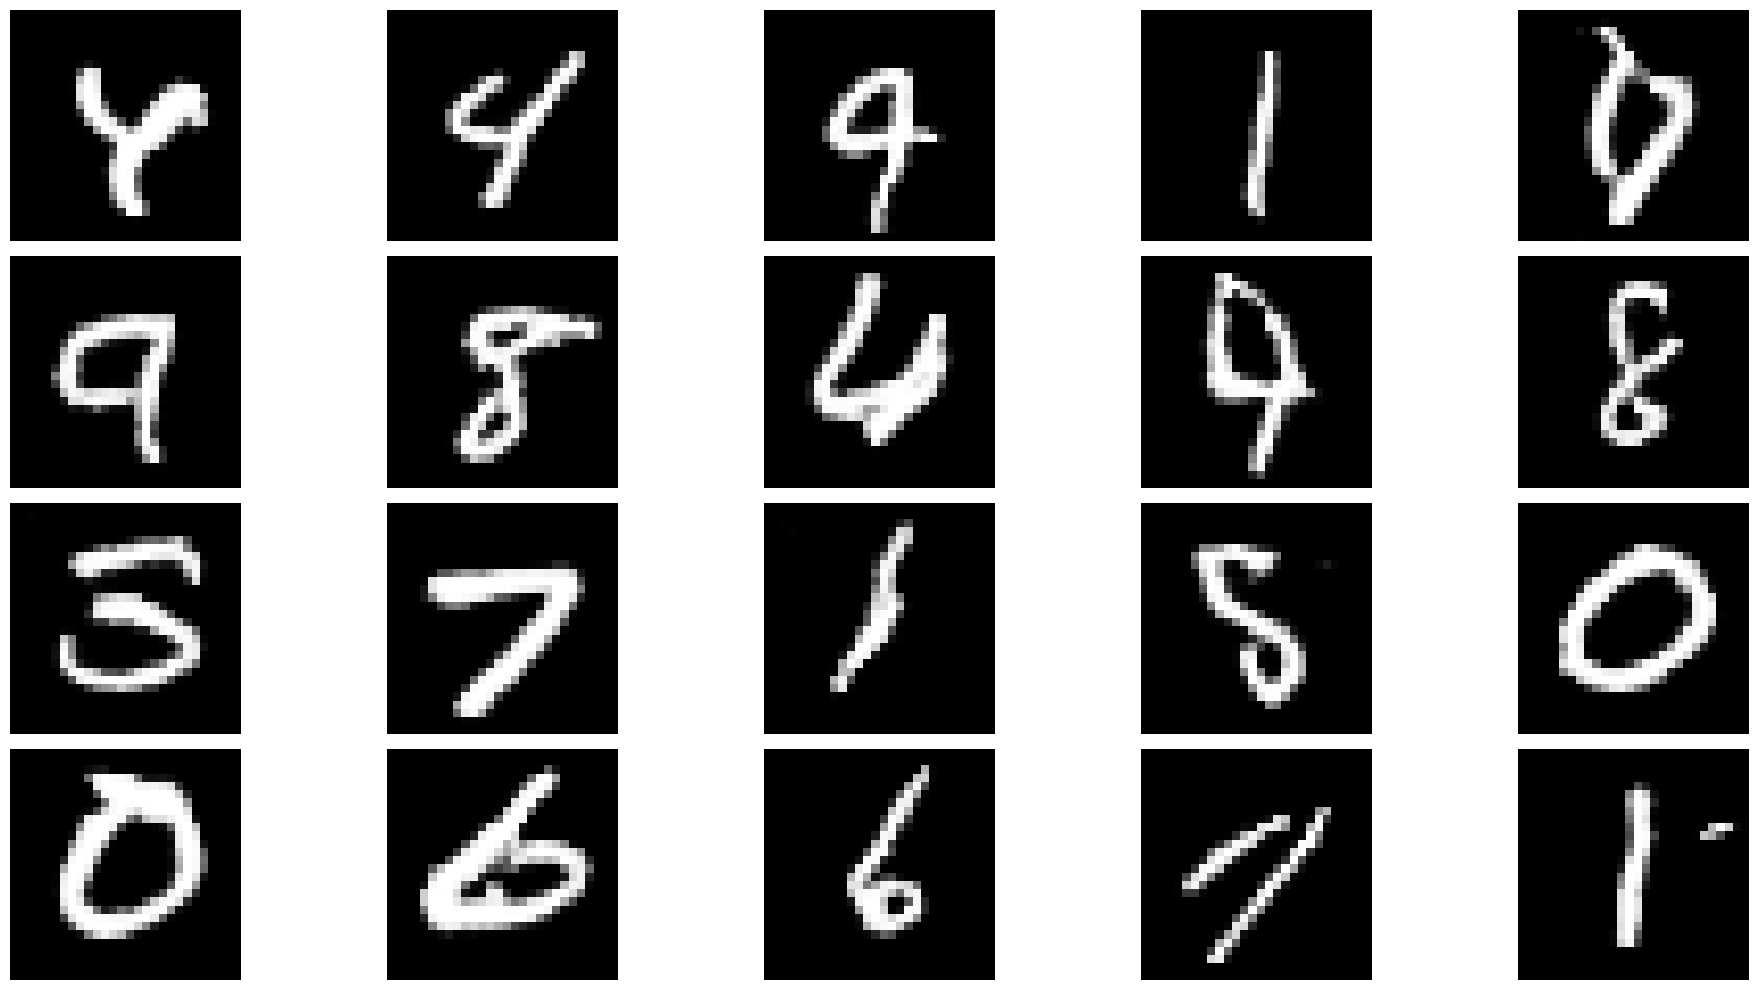

📈 Epoch 40 Summary:
   Train D Loss: 0.9612, Val D Loss: 1.1945
   Train G Loss: 1.3107, Val G Loss: 1.4353

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.859973	G_loss: 1.406936
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.870212	G_loss: 1.267335
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.224432	G_loss: 0.452256
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.849247	G_loss: 1.354520
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.862028	G_loss: 1.543555
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.949318	G_loss: 1.411616
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.920198	G_loss: 1.660447
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.036783	G_loss: 1.649877
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.961738	G_loss: 0.897142
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.873093	G_loss: 1.227102
====> Epoch: 41 Train D_loss: 0.9581, Train G_loss: 1.3125
====> Epoch: 41 Val D_loss: 1.2506, Val G_loss: 1.6183
📈 Epoch 41 Summary:
   Train D Loss: 0.9581, Val D Loss: 1.2506
   Train G Loss: 1.3125

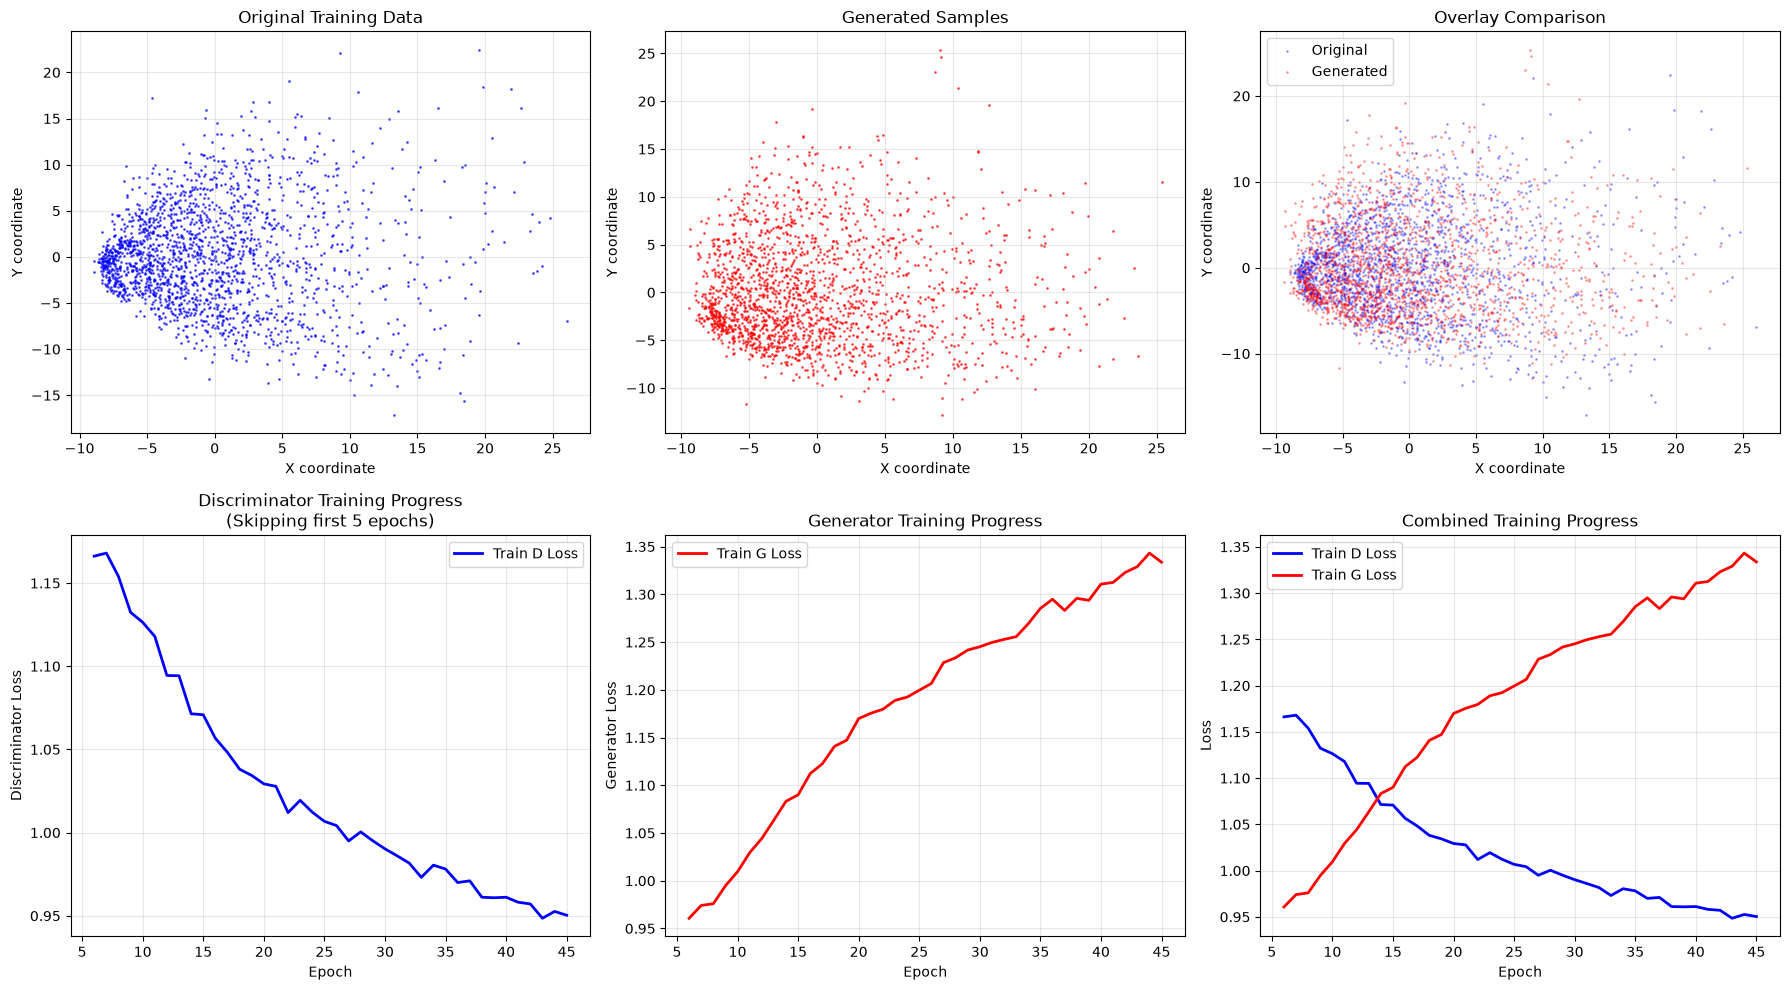

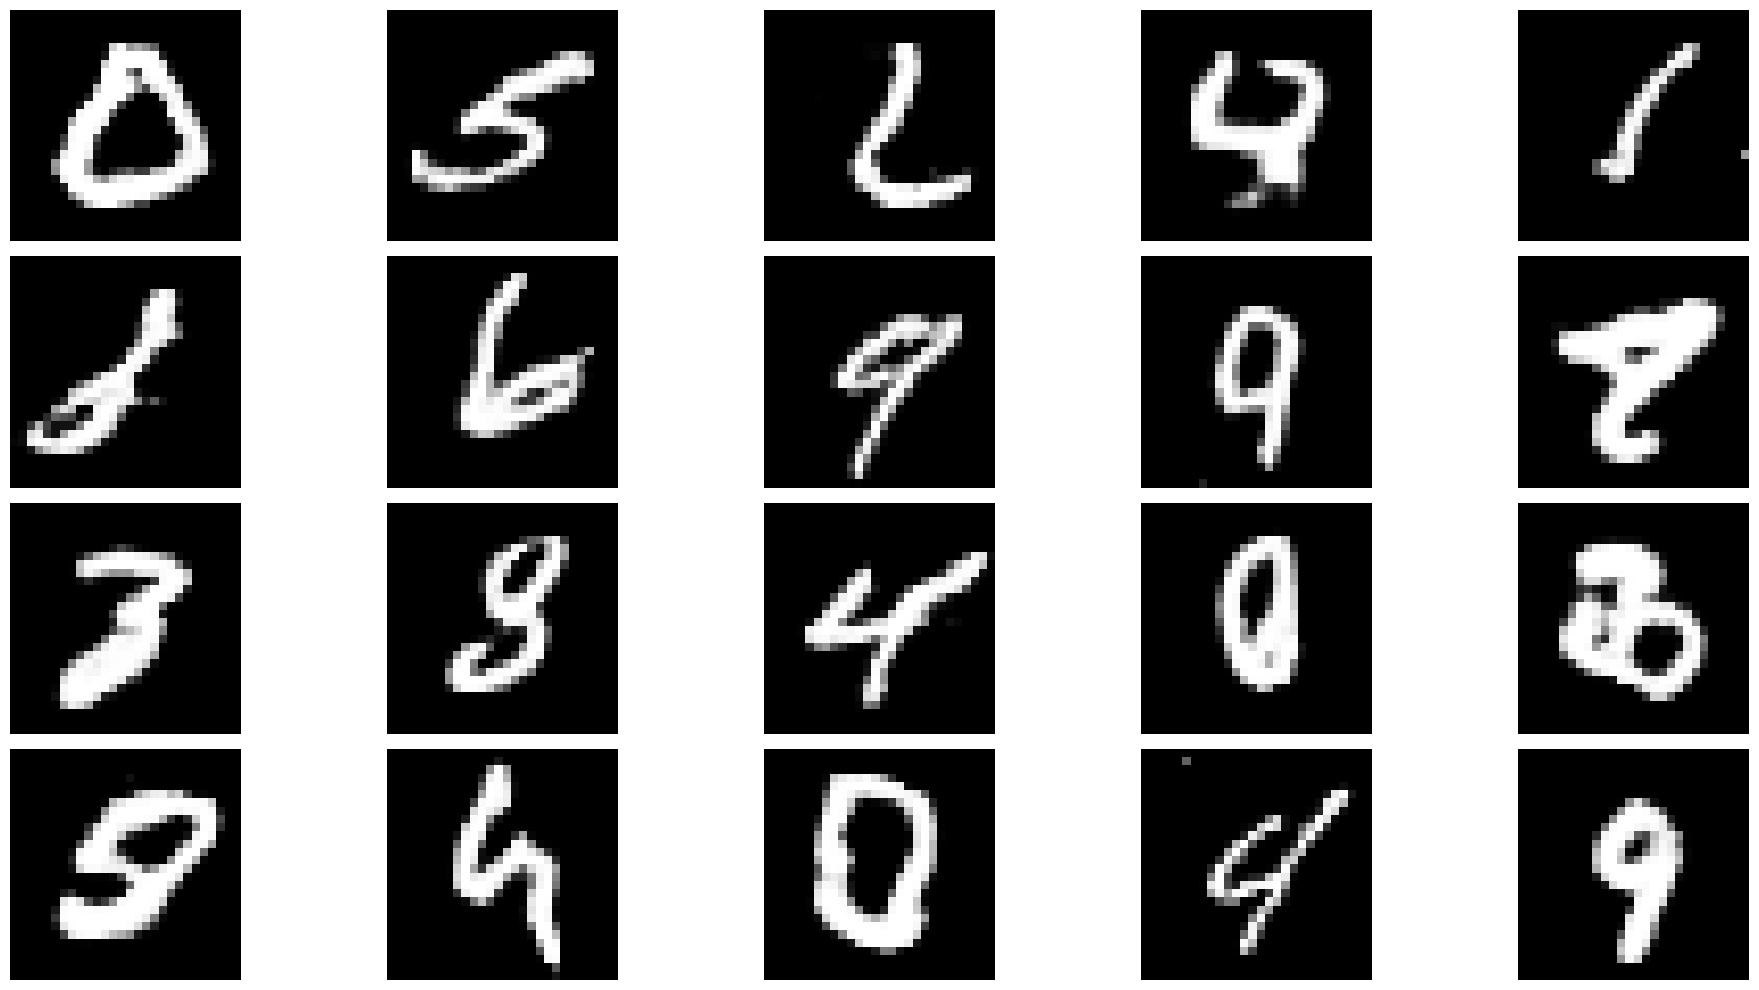

📈 Epoch 45 Summary:
   Train D Loss: 0.9503, Val D Loss: 1.1514
   Train G Loss: 1.3337, Val G Loss: 0.8258

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.983022	G_loss: 2.411936
Epoch: 46 [6400/60000 (11%)]	D_loss: 1.148989	G_loss: 0.522968
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.999864	G_loss: 1.531270
Epoch: 46 [19200/60000 (32%)]	D_loss: 1.063006	G_loss: 1.875196
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.785861	G_loss: 1.139851
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.789716	G_loss: 1.067155
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.943193	G_loss: 0.980564
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.911653	G_loss: 1.278442
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.183291	G_loss: 0.552200
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.040885	G_loss: 1.092214
====> Epoch: 46 Train D_loss: 0.9493, Train G_loss: 1.3461
====> Epoch: 46 Val D_loss: 1.1368, Val G_loss: 1.0991
📈 Epoch 46 Summary:
   Train D Loss: 0.9493, Val D Loss: 1.1368
   Train G Loss: 1.3461

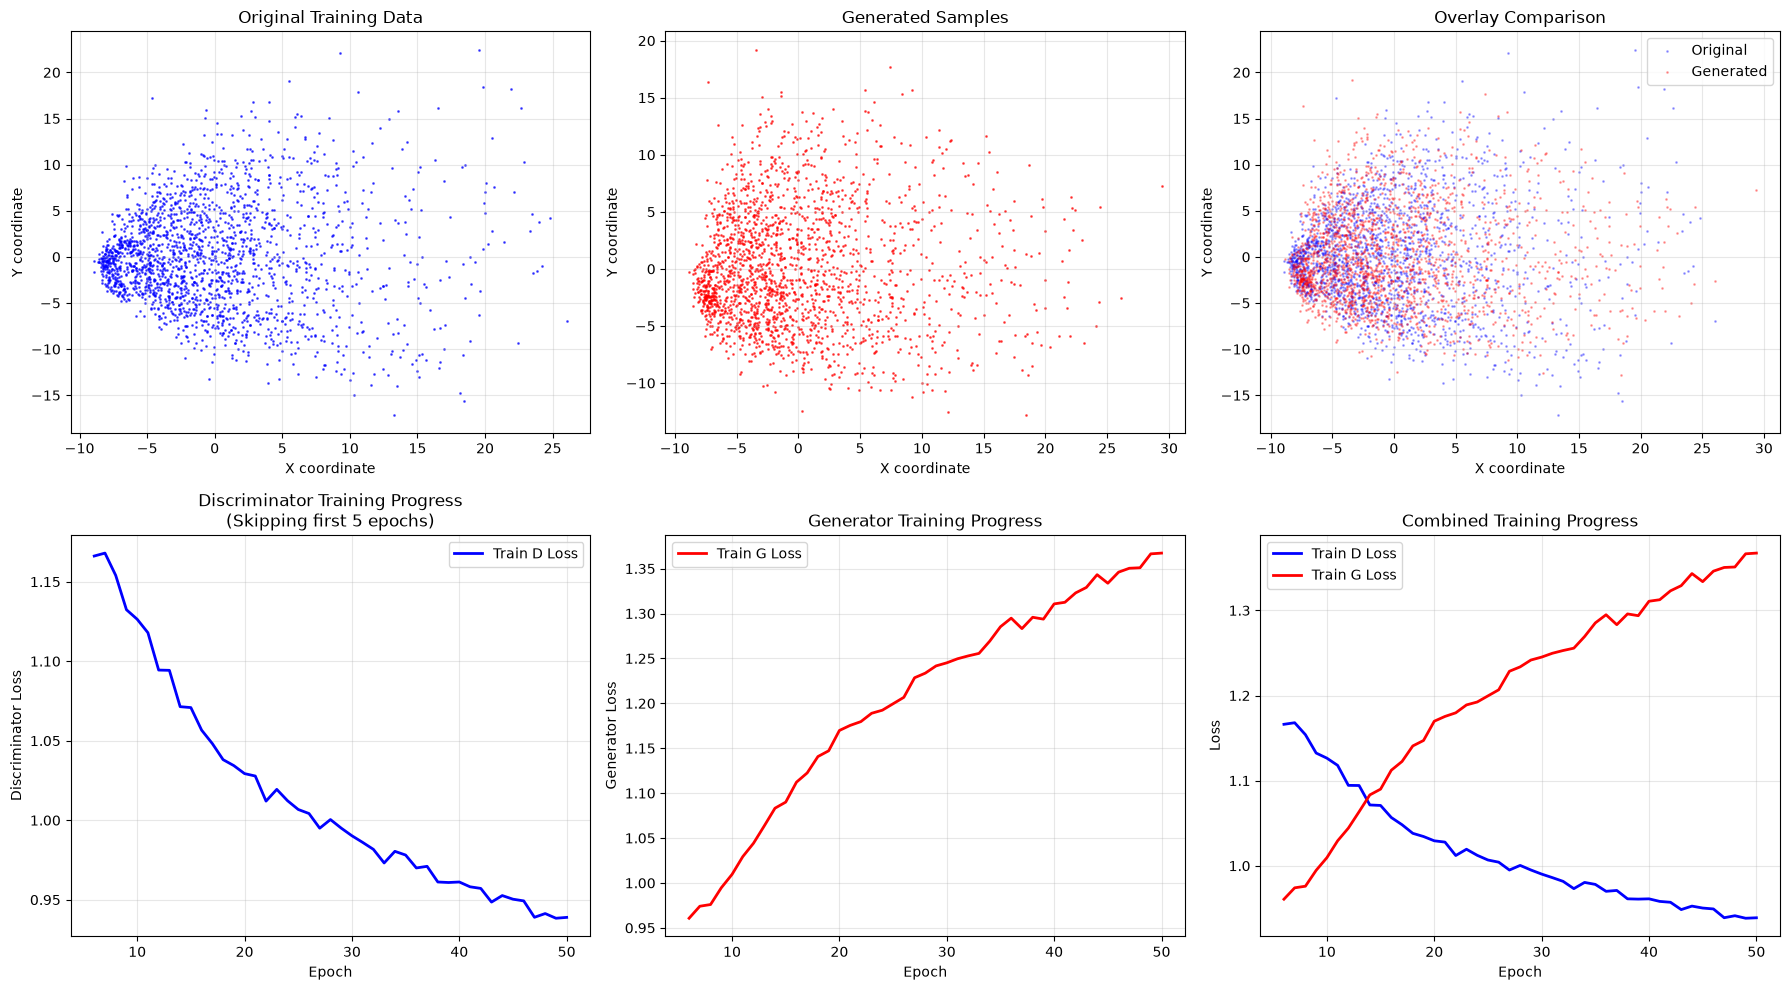

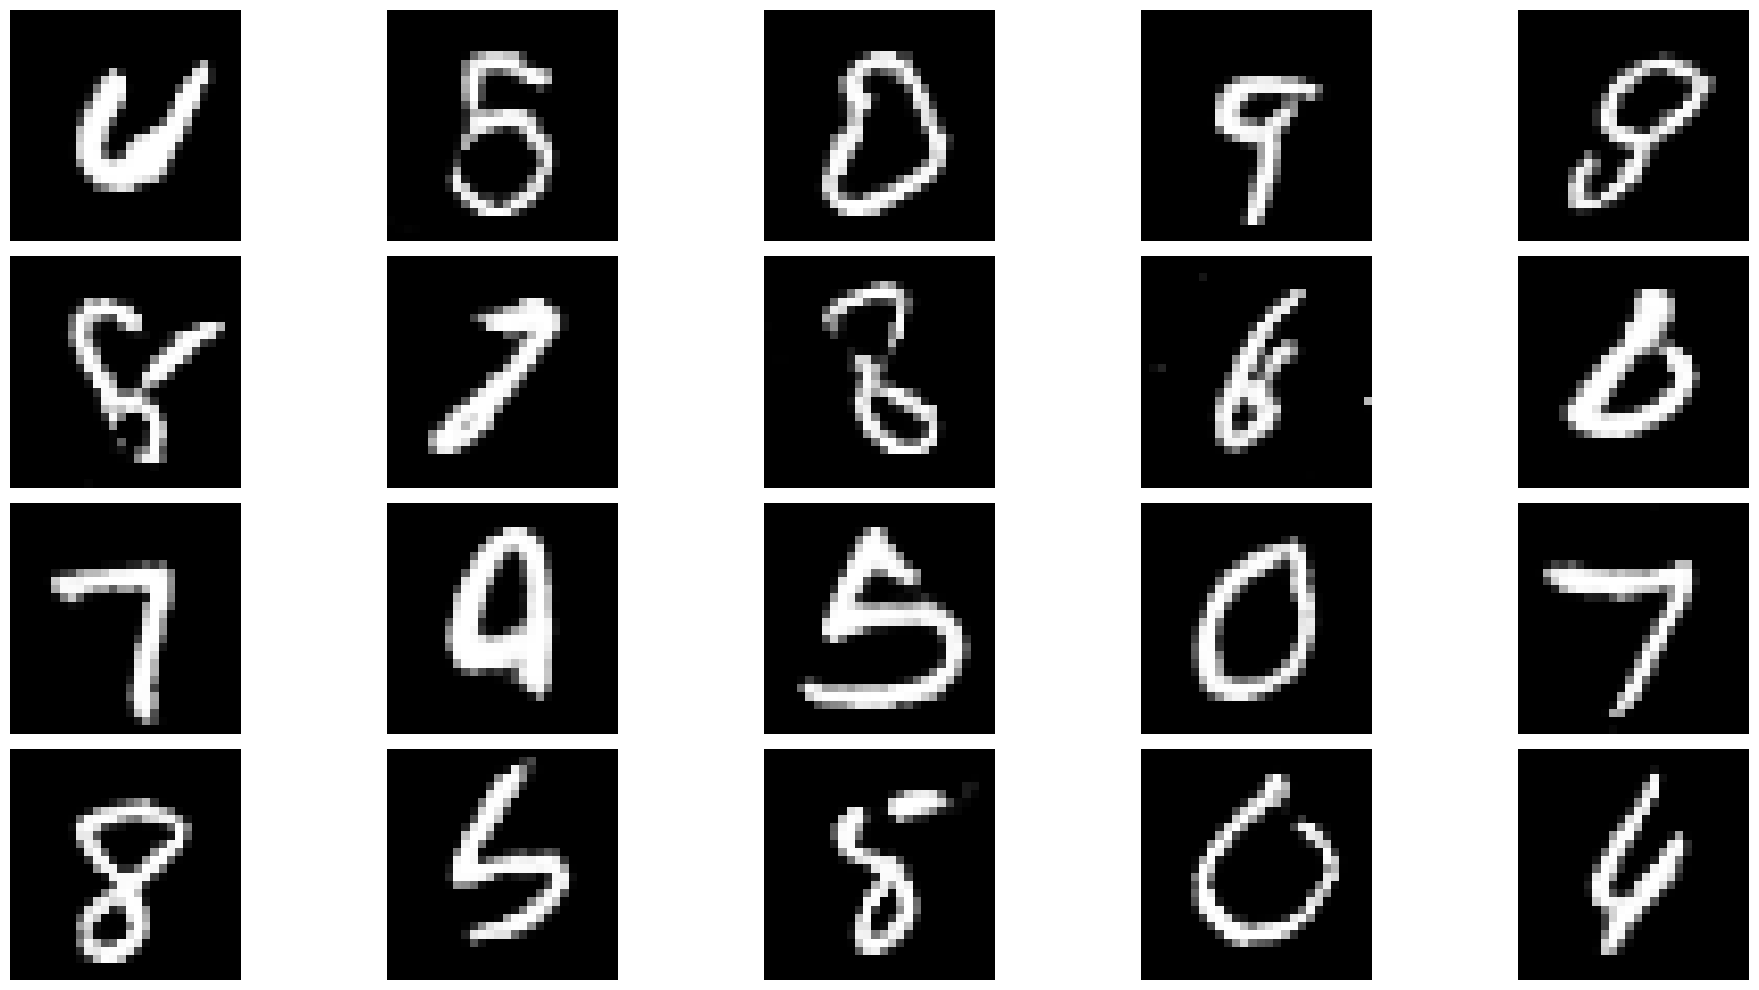

📈 Epoch 50 Summary:
   Train D Loss: 0.9389, Val D Loss: 1.1406
   Train G Loss: 1.3673, Val G Loss: 0.9750

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.814822	G_loss: 1.481665
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.989825	G_loss: 1.572598
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.903433	G_loss: 1.076386
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.995968	G_loss: 1.060044
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.964455	G_loss: 2.270327
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.828866	G_loss: 1.168042
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.070823	G_loss: 1.944498
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.876580	G_loss: 1.341494
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.975342	G_loss: 1.024715
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.861749	G_loss: 0.865759
====> Epoch: 51 Train D_loss: 0.9362, Train G_loss: 1.3728
====> Epoch: 51 Val D_loss: 1.1338, Val G_loss: 1.0980
📈 Epoch 51 Summary:
   Train D Loss: 0.9362, Val D Loss: 1.1338
   Train G Loss: 1.3728

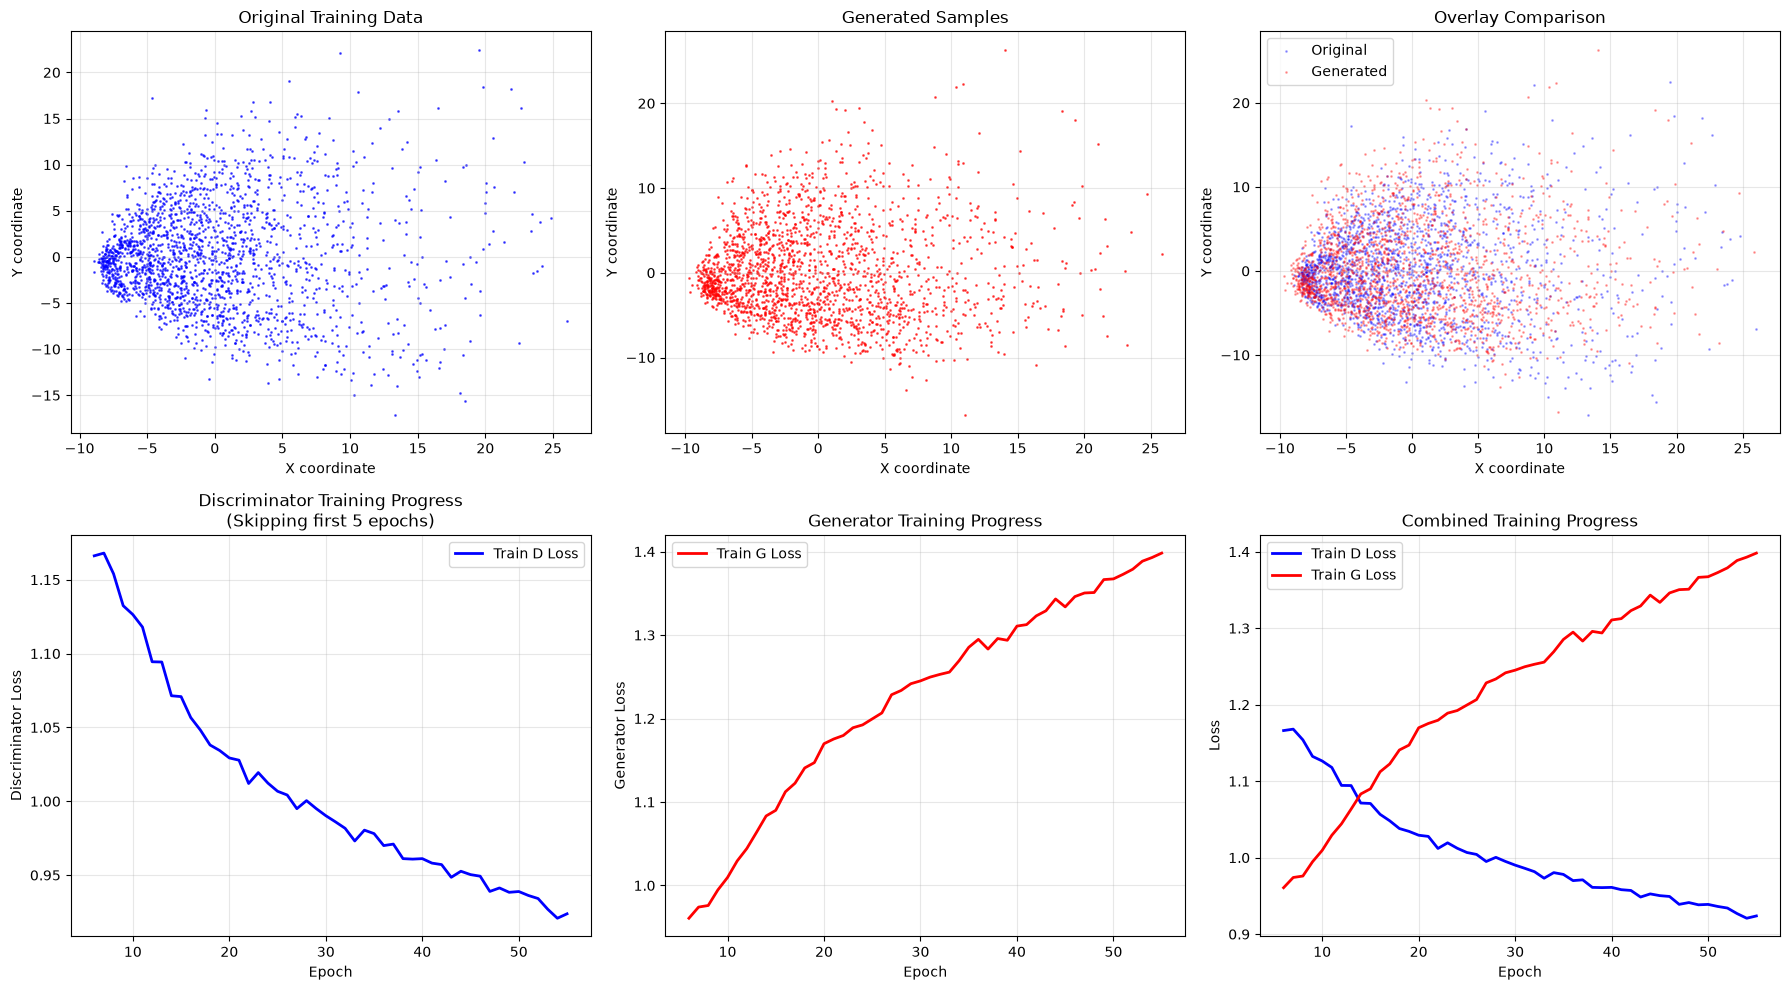

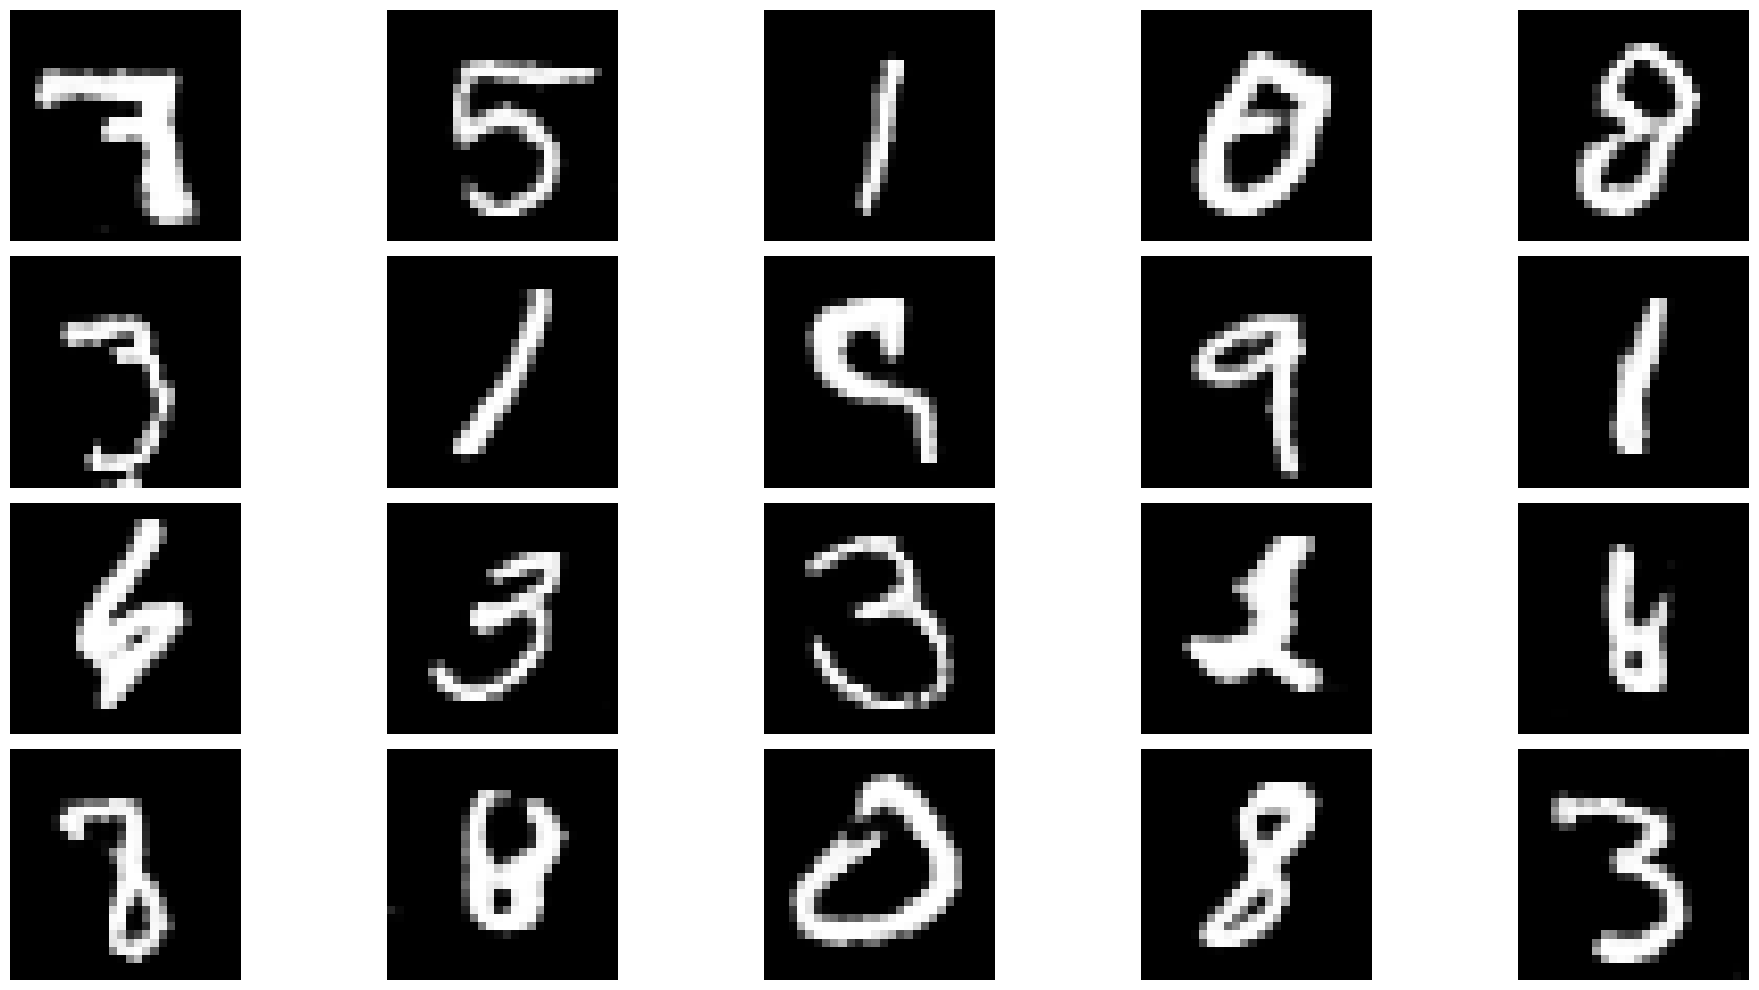

📈 Epoch 55 Summary:
   Train D Loss: 0.9238, Val D Loss: 1.3495
   Train G Loss: 1.3982, Val G Loss: 1.8819

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.968982	G_loss: 1.143667
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.962225	G_loss: 1.710008
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.940338	G_loss: 1.025482
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.983420	G_loss: 1.999035
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.878386	G_loss: 1.188239
Epoch: 56 [32000/60000 (53%)]	D_loss: 1.076564	G_loss: 1.534099
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.965967	G_loss: 1.887285
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.918927	G_loss: 0.925456
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.819918	G_loss: 1.260113
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.867356	G_loss: 1.377318
====> Epoch: 56 Train D_loss: 0.9278, Train G_loss: 1.3997
====> Epoch: 56 Val D_loss: 1.2498, Val G_loss: 0.6819
📈 Epoch 56 Summary:
   Train D Loss: 0.9278, Val D Loss: 1.2498
   Train G Loss: 1.3997

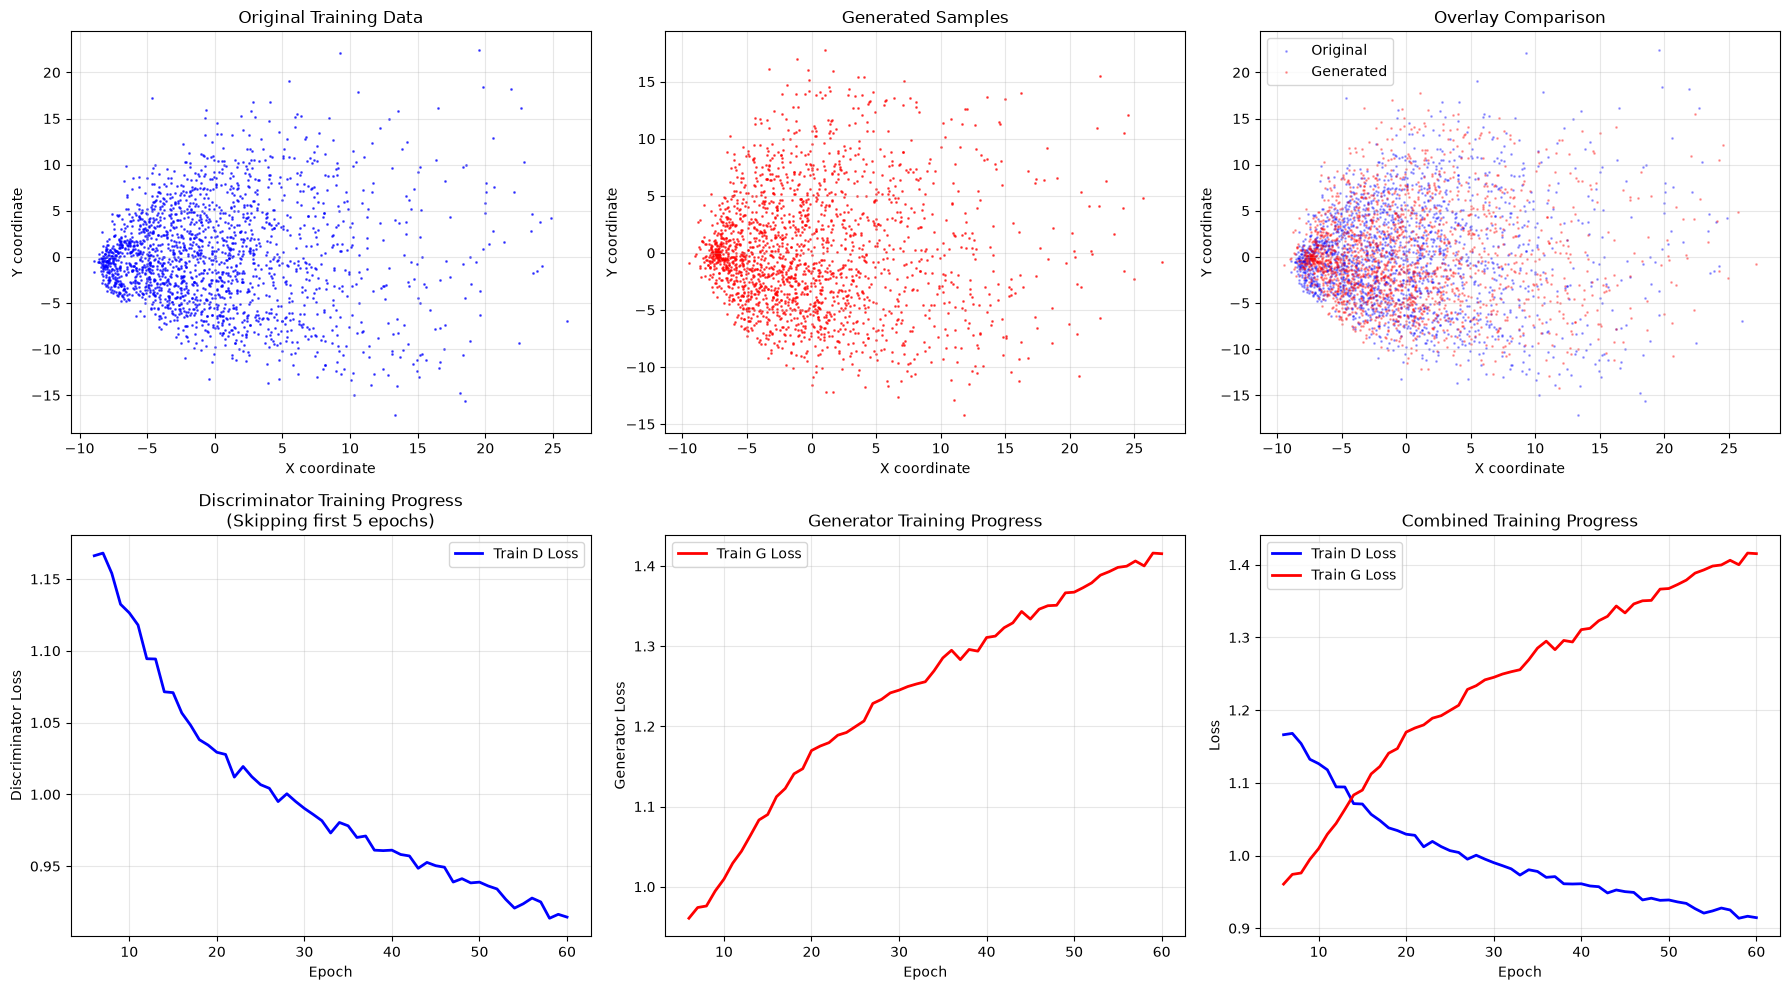

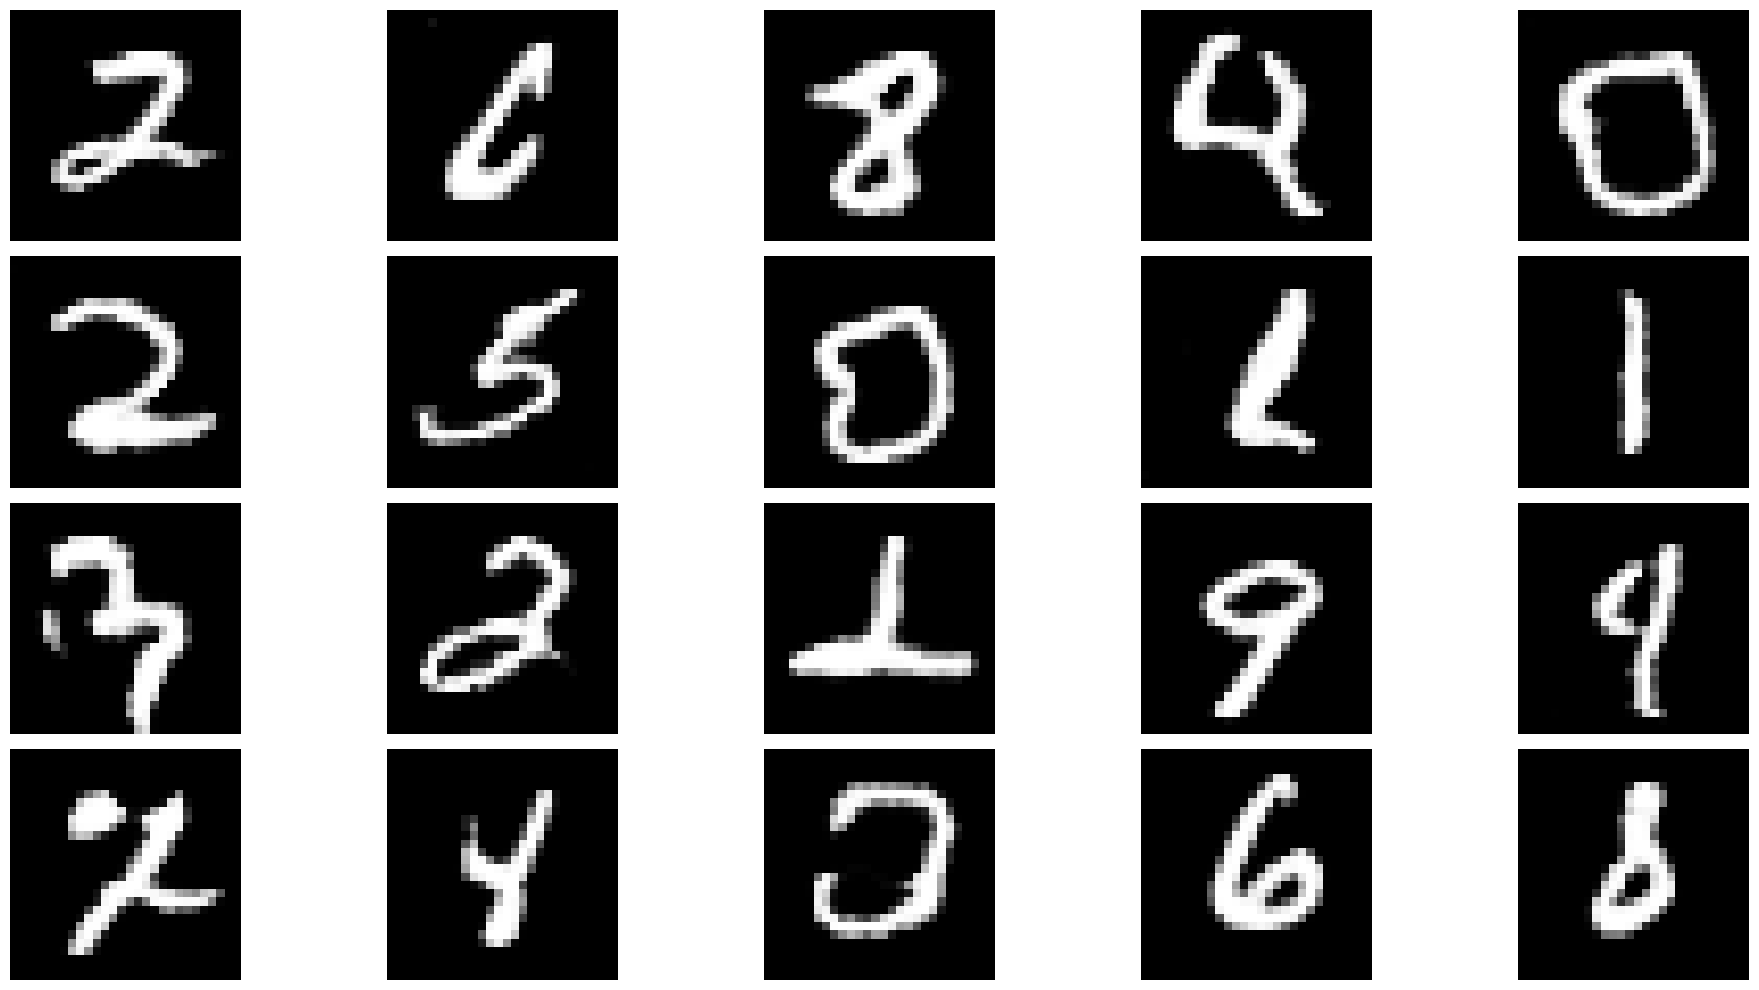

📈 Epoch 60 Summary:
   Train D Loss: 0.9146, Val D Loss: 1.1359
   Train G Loss: 1.4153, Val G Loss: 0.9214

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.902440	G_loss: 1.661445
Epoch: 61 [6400/60000 (11%)]	D_loss: 1.053407	G_loss: 1.761773
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.908320	G_loss: 1.825853
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.094603	G_loss: 2.085865
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.828819	G_loss: 0.972615
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.905851	G_loss: 1.113985
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.884106	G_loss: 1.351864
Epoch: 61 [44800/60000 (75%)]	D_loss: 1.139377	G_loss: 1.102287
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.896576	G_loss: 1.171364
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.826644	G_loss: 1.440069
====> Epoch: 61 Train D_loss: 0.9101, Train G_loss: 1.4289
====> Epoch: 61 Val D_loss: 1.8549, Val G_loss: 2.7303
📈 Epoch 61 Summary:
   Train D Loss: 0.9101, Val D Loss: 1.8549
   Train G Loss: 1.4289

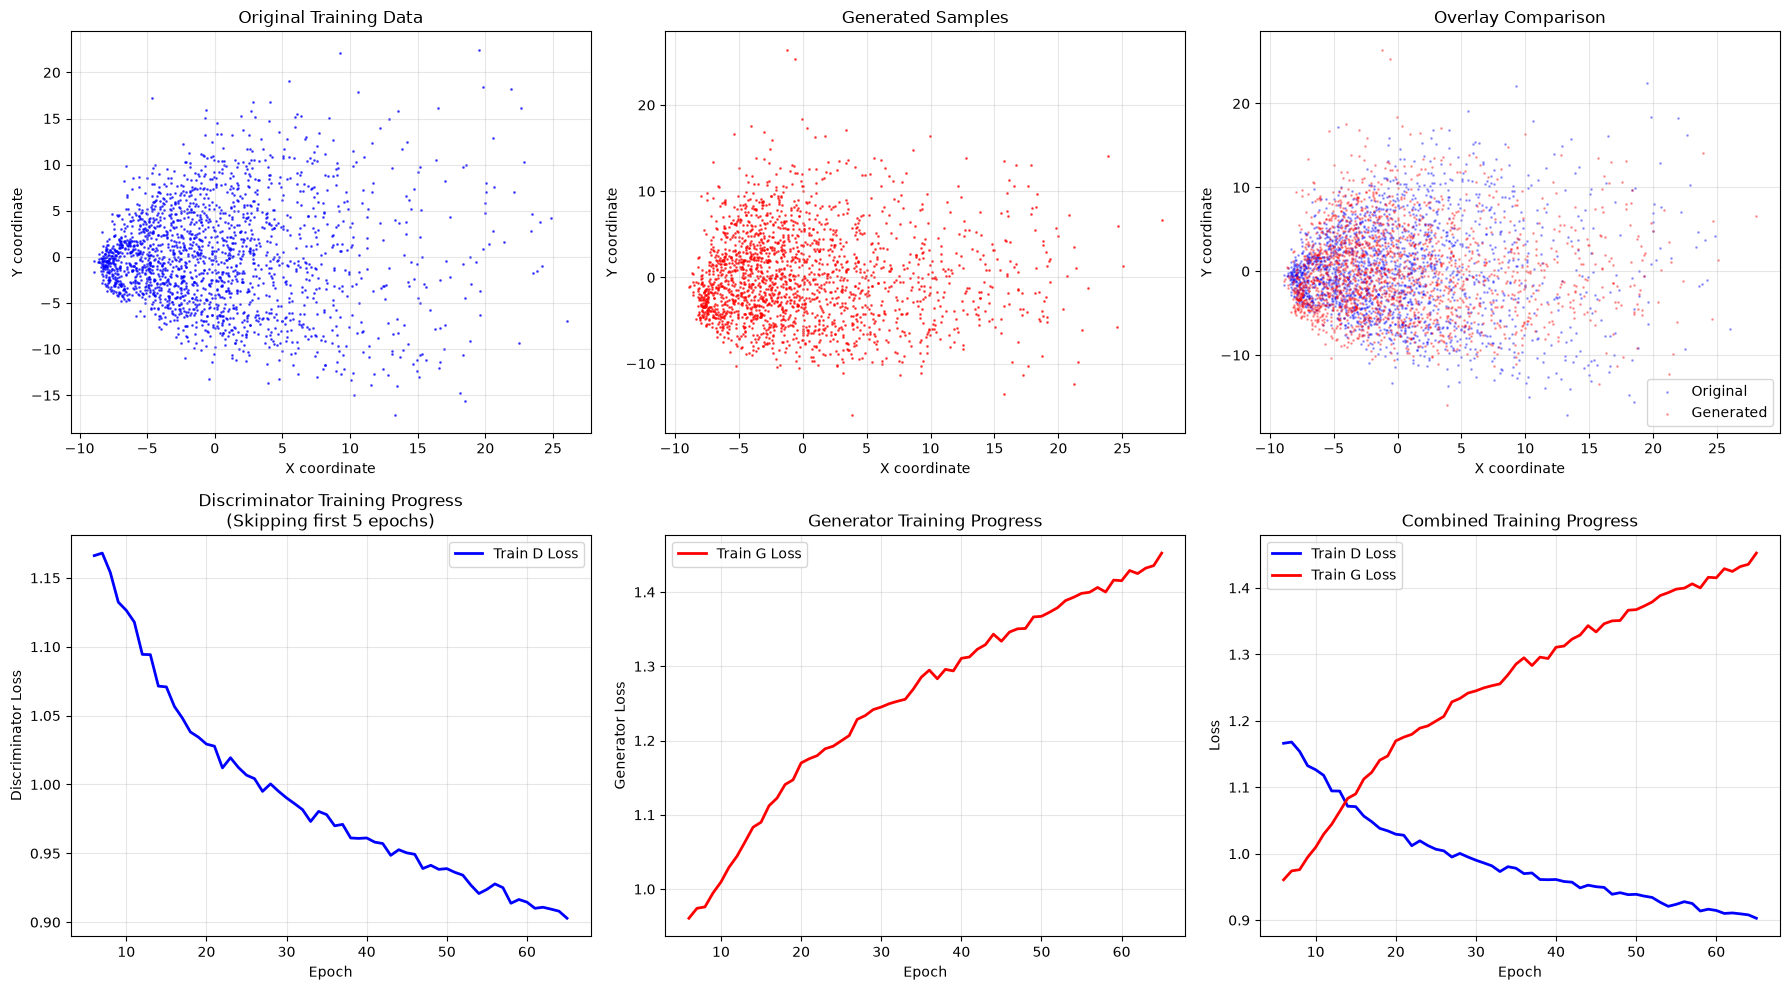

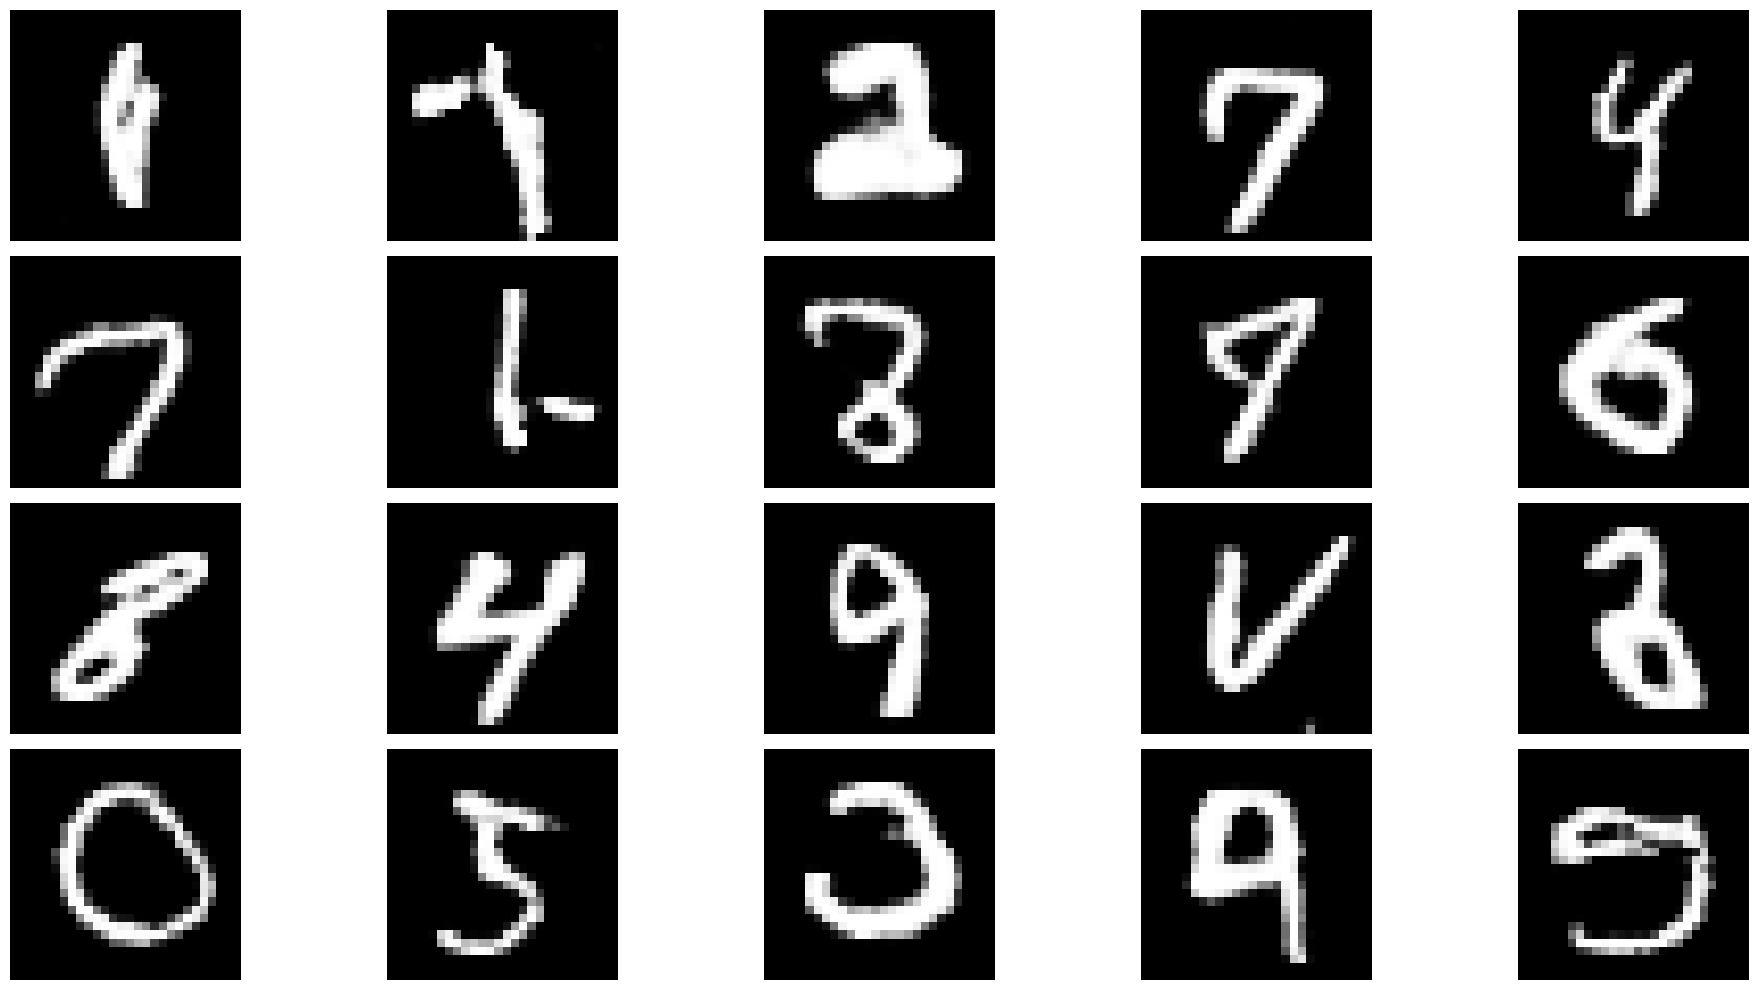

📈 Epoch 65 Summary:
   Train D Loss: 0.9029, Val D Loss: 1.3503
   Train G Loss: 1.4524, Val G Loss: 1.8904

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.009166	G_loss: 0.853050
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.840508	G_loss: 1.218193
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.845259	G_loss: 1.582561
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.779687	G_loss: 1.097656
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.872907	G_loss: 1.385622
Epoch: 66 [32000/60000 (53%)]	D_loss: 1.282663	G_loss: 0.560258
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.805197	G_loss: 1.477403
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.895135	G_loss: 1.186745
Epoch: 66 [51200/60000 (85%)]	D_loss: 1.016402	G_loss: 0.969085
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.758377	G_loss: 1.261488
====> Epoch: 66 Train D_loss: 0.9050, Train G_loss: 1.4446
====> Epoch: 66 Val D_loss: 1.8388, Val G_loss: 0.3086
📈 Epoch 66 Summary:
   Train D Loss: 0.9050, Val D Loss: 1.8388
   Train G Loss: 1.4446

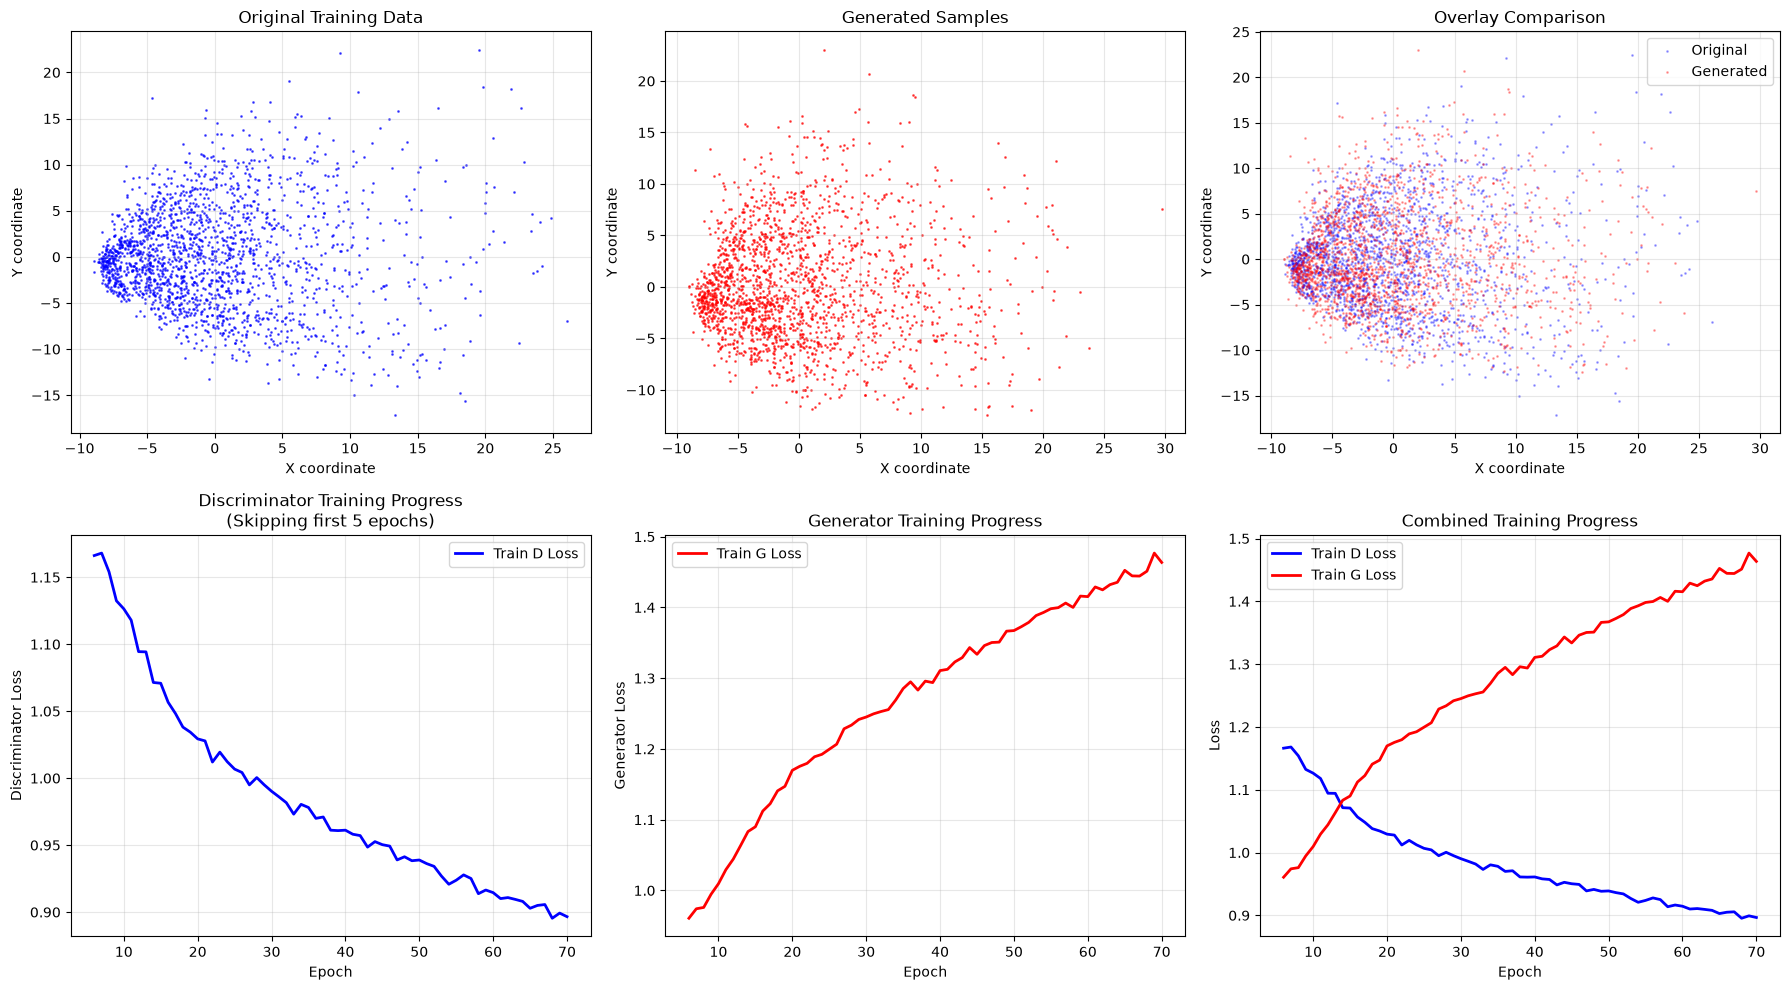

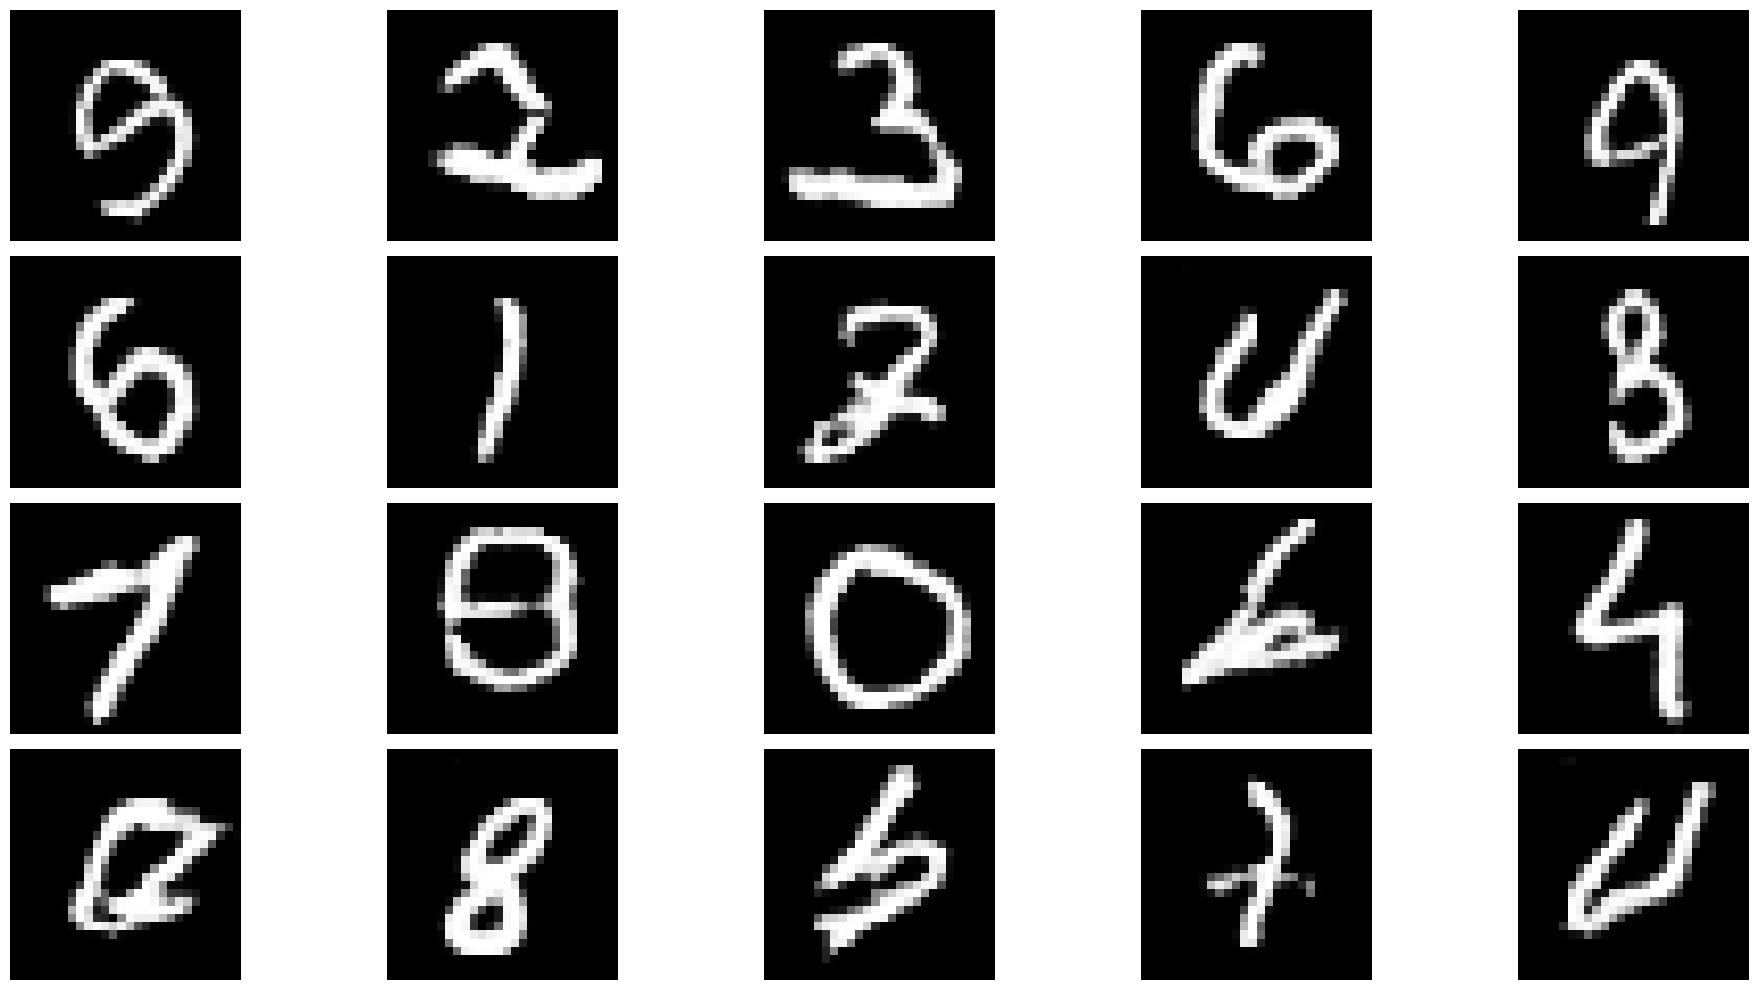

📈 Epoch 70 Summary:
   Train D Loss: 0.8966, Val D Loss: 1.2051
   Train G Loss: 1.4636, Val G Loss: 1.4887

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.678589	G_loss: 1.420172
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.872877	G_loss: 1.674787
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.818869	G_loss: 1.184740
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.702194	G_loss: 1.611043
Epoch: 71 [25600/60000 (43%)]	D_loss: 1.175868	G_loss: 0.713790
Epoch: 71 [32000/60000 (53%)]	D_loss: 1.067404	G_loss: 0.954284
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.962040	G_loss: 1.320563
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.834860	G_loss: 1.391227
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.881159	G_loss: 1.014264
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.121165	G_loss: 2.339007
====> Epoch: 71 Train D_loss: 0.8942, Train G_loss: 1.4755
====> Epoch: 71 Val D_loss: 1.1353, Val G_loss: 1.2646
📈 Epoch 71 Summary:
   Train D Loss: 0.8942, Val D Loss: 1.1353
   Train G Loss: 1.4755

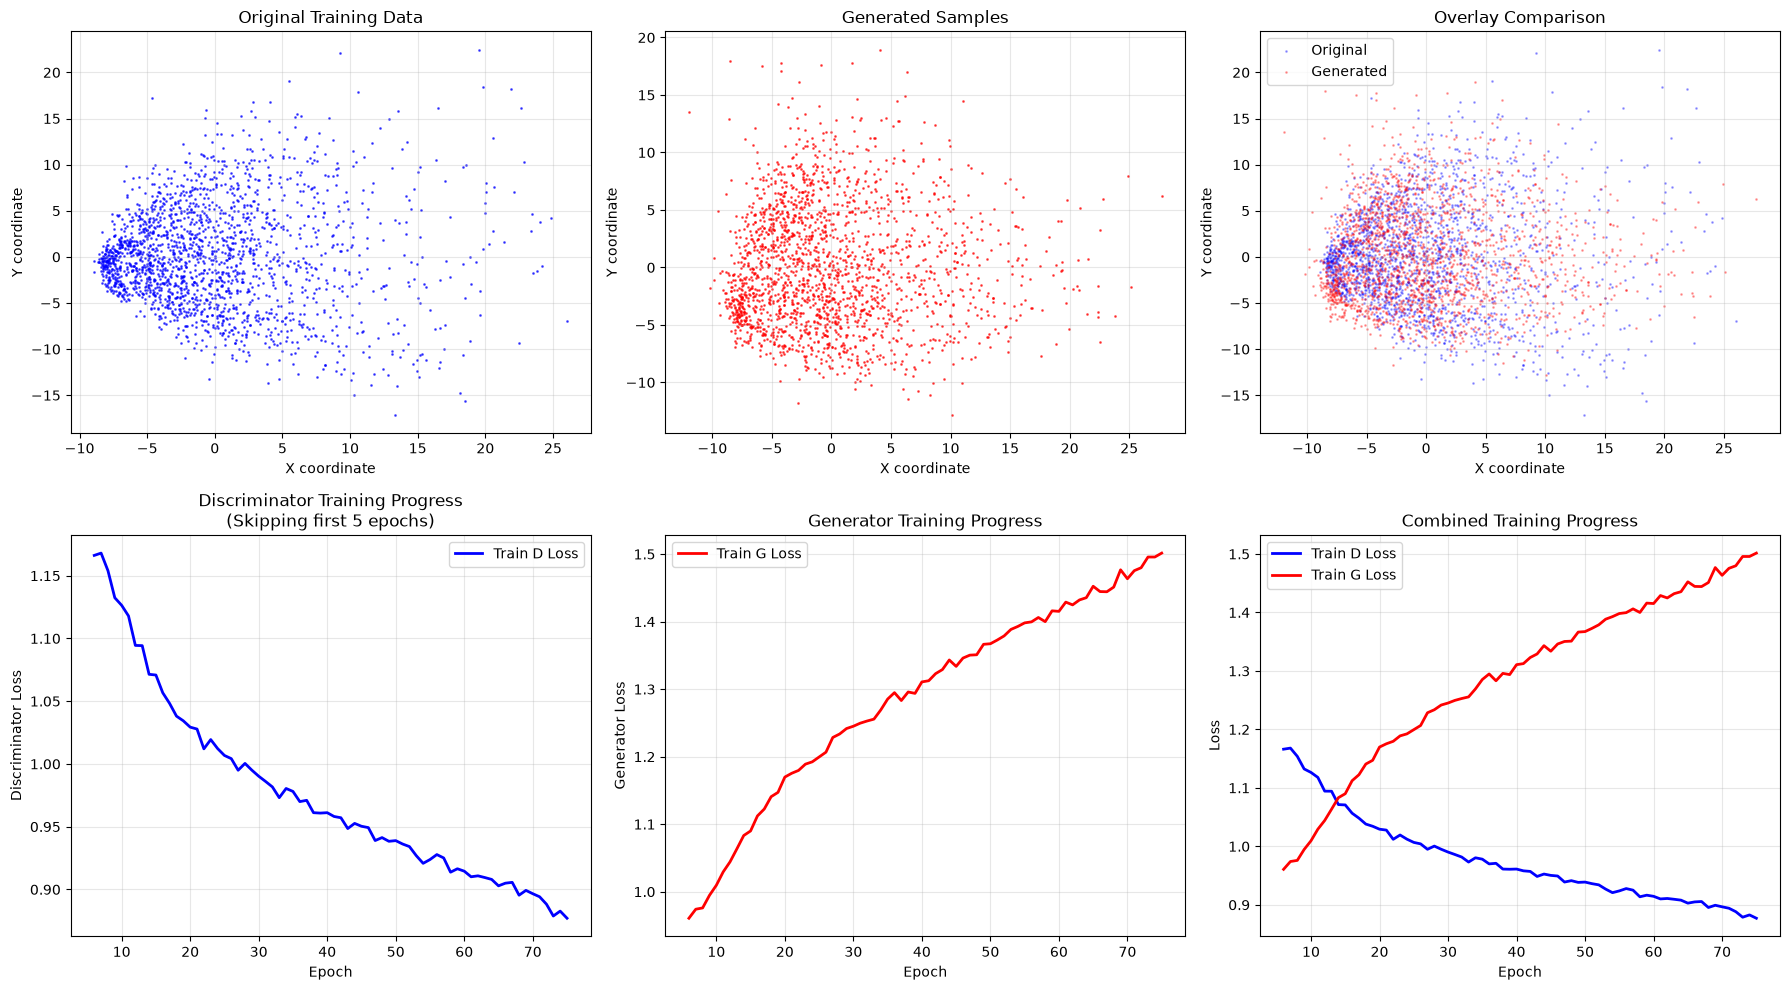

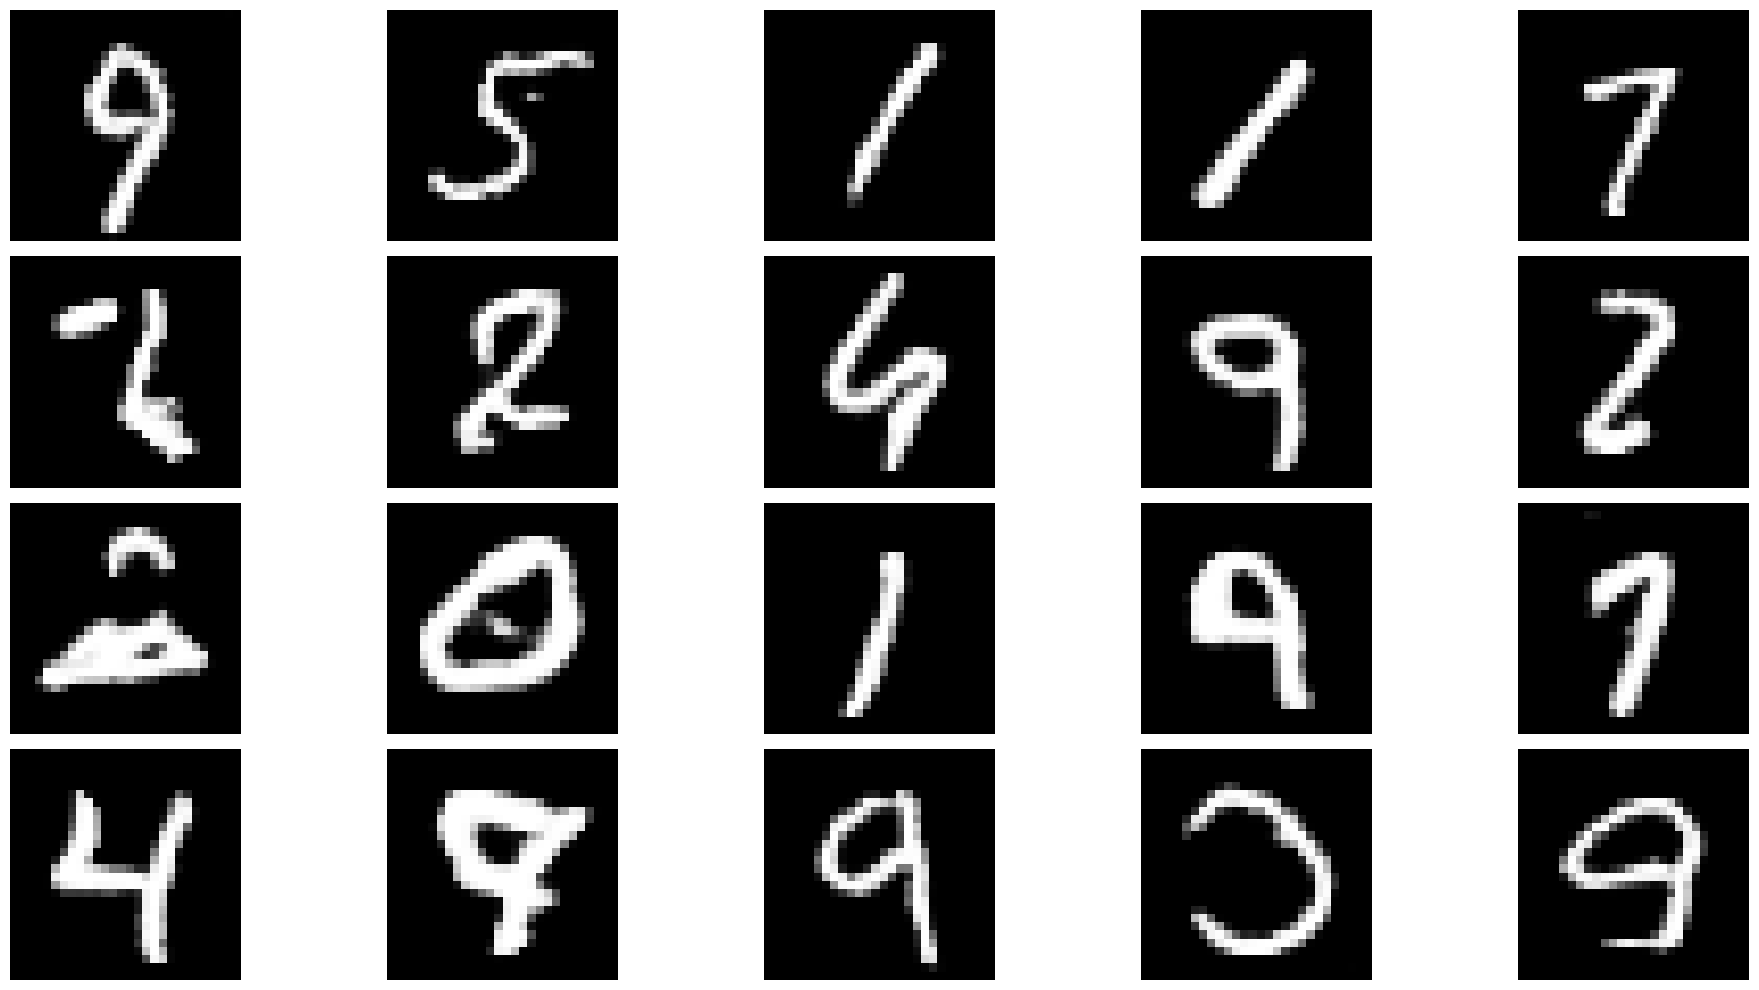

📈 Epoch 75 Summary:
   Train D Loss: 0.8771, Val D Loss: 1.2363
   Train G Loss: 1.5015, Val G Loss: 0.7301

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.032119	G_loss: 2.520162
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.846075	G_loss: 1.501607
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.998498	G_loss: 2.310455
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.777864	G_loss: 1.601926
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.933406	G_loss: 1.571350
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.802354	G_loss: 1.464857
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.048536	G_loss: 2.472833
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.836948	G_loss: 1.561116
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.805100	G_loss: 1.096830
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.849243	G_loss: 1.163414
====> Epoch: 76 Train D_loss: 0.8806, Train G_loss: 1.5137
====> Epoch: 76 Val D_loss: 1.1129, Val G_loss: 1.3062
📈 Epoch 76 Summary:
   Train D Loss: 0.8806, Val D Loss: 1.1129
   Train G Loss: 1.5137

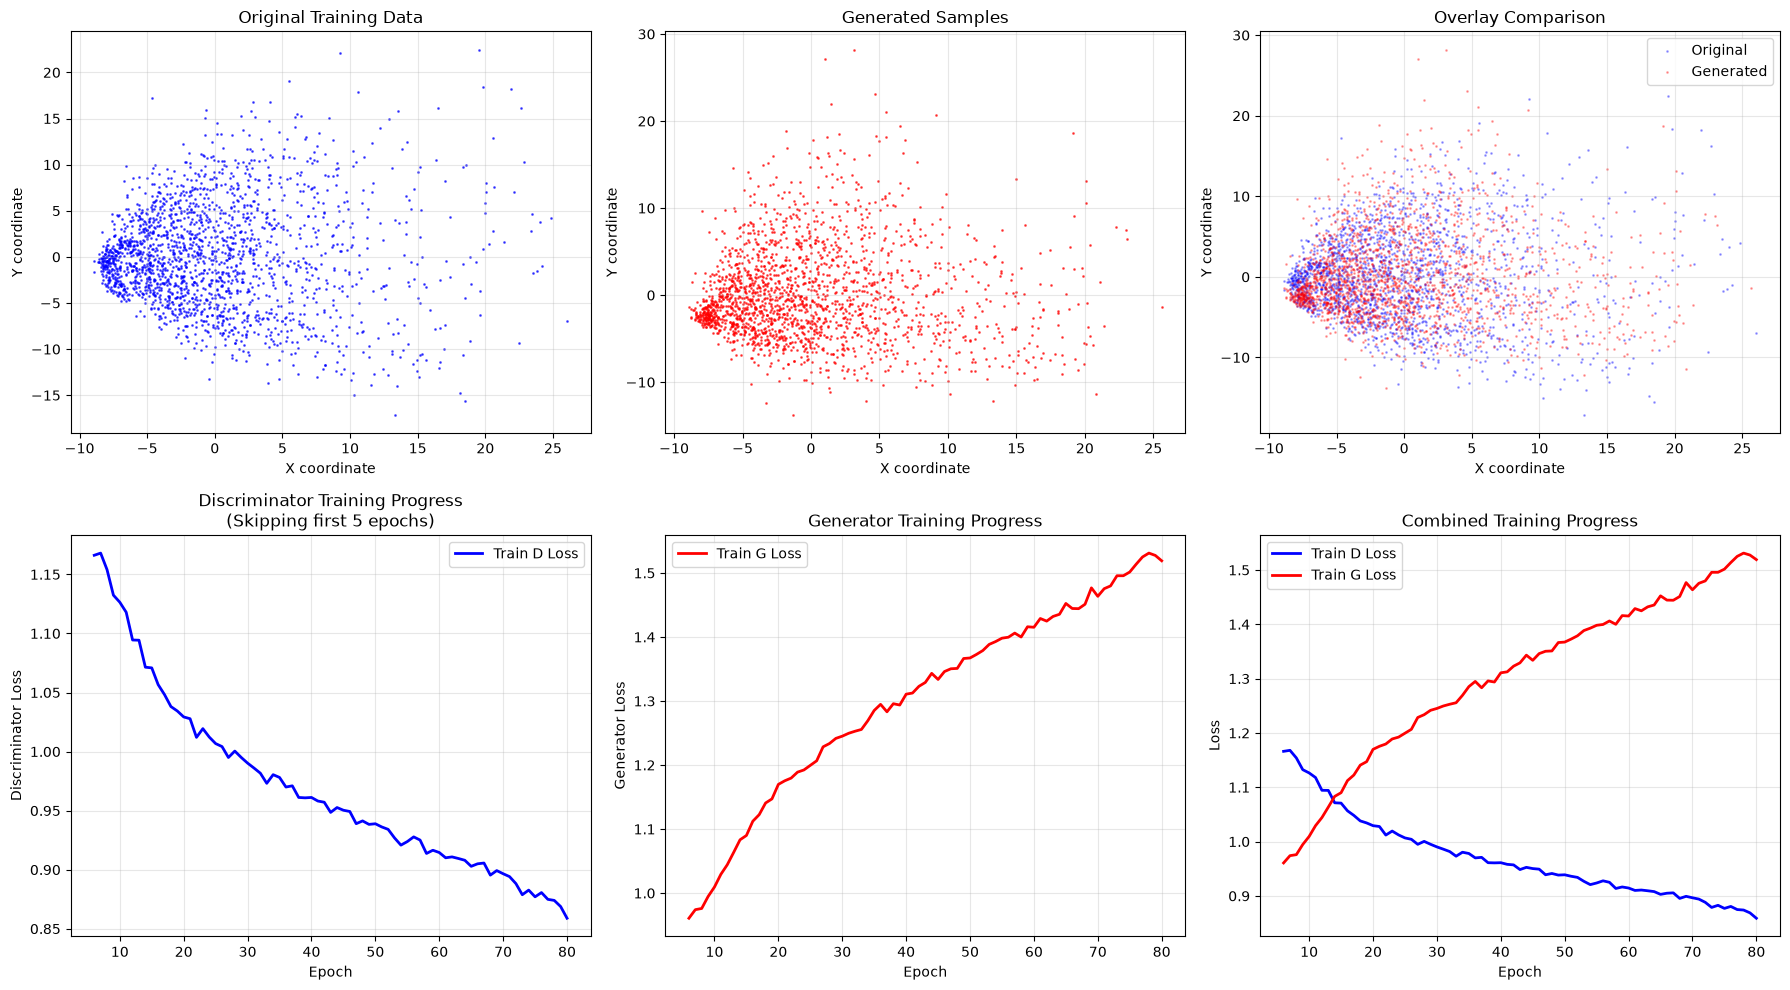

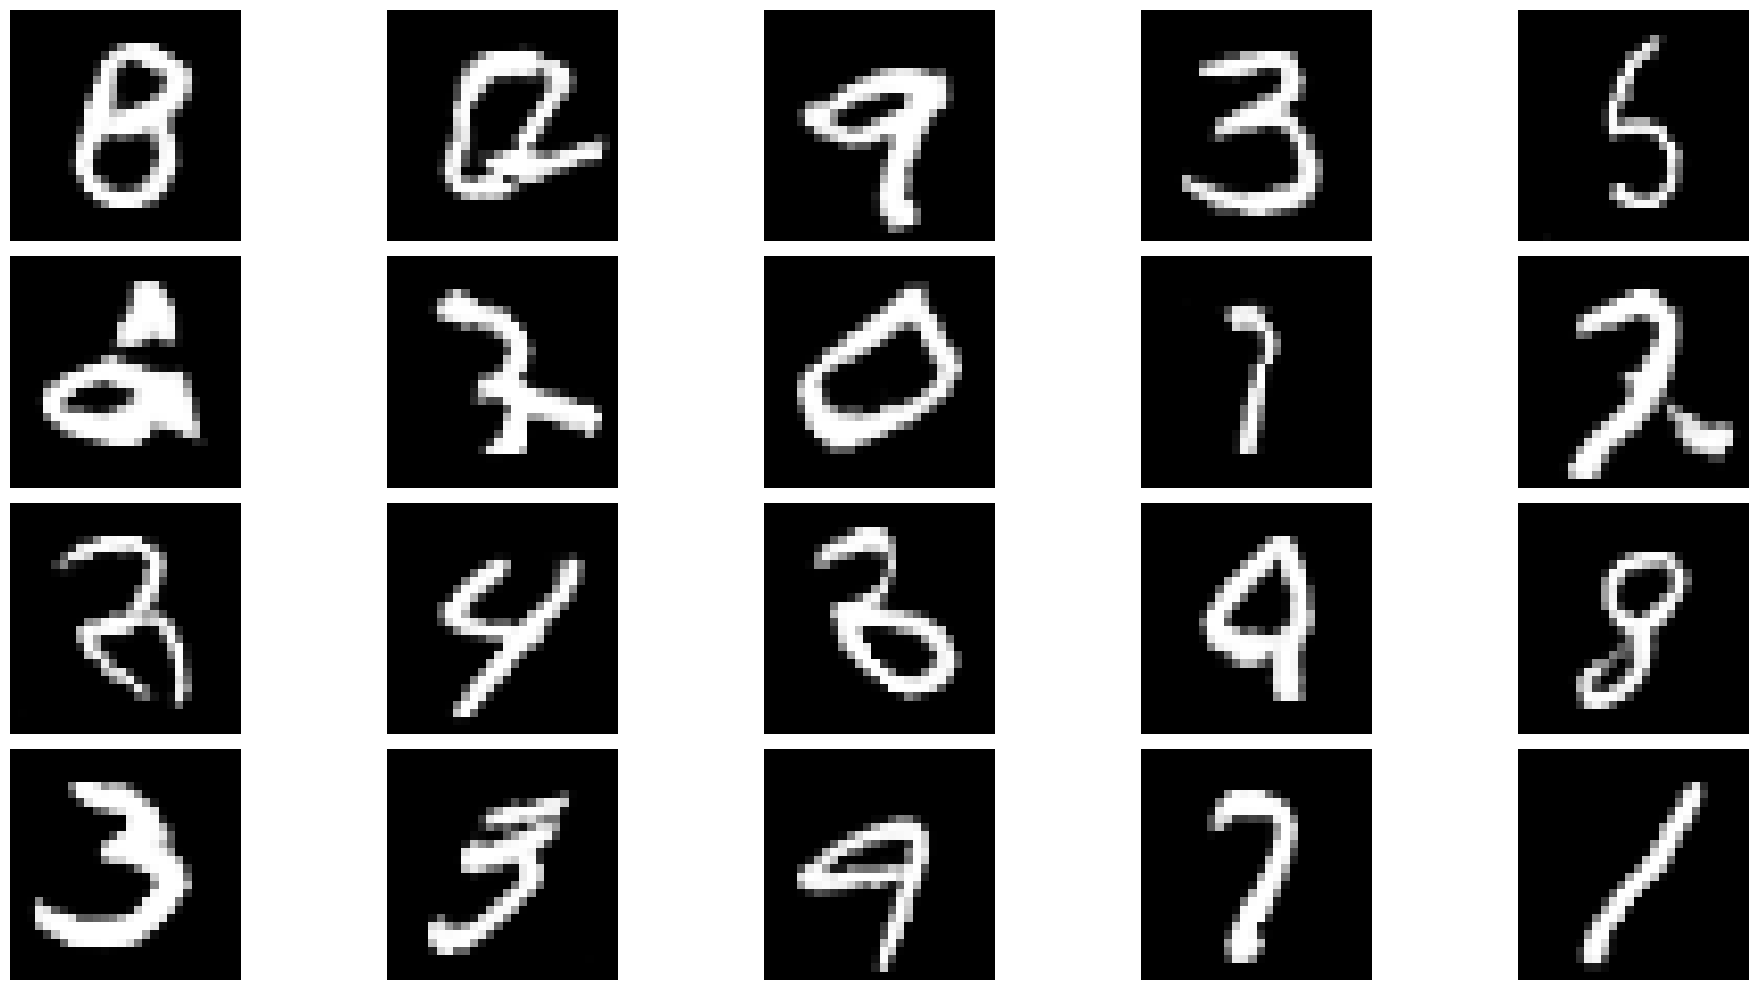

📈 Epoch 80 Summary:
   Train D Loss: 0.8589, Val D Loss: 1.1663
   Train G Loss: 1.5191, Val G Loss: 1.5394

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.945159	G_loss: 1.707191
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.929836	G_loss: 1.226309
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.773453	G_loss: 1.728050
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.930301	G_loss: 1.121305
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.757244	G_loss: 1.469820
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.813157	G_loss: 1.571882
Epoch: 81 [38400/60000 (64%)]	D_loss: 1.008568	G_loss: 2.083694
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.011797	G_loss: 1.306108
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.876976	G_loss: 1.709344
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.920826	G_loss: 1.760889
====> Epoch: 81 Train D_loss: 0.8634, Train G_loss: 1.5344
====> Epoch: 81 Val D_loss: 1.8046, Val G_loss: 2.7201
📈 Epoch 81 Summary:
   Train D Loss: 0.8634, Val D Loss: 1.8046
   Train G Loss: 1.5344

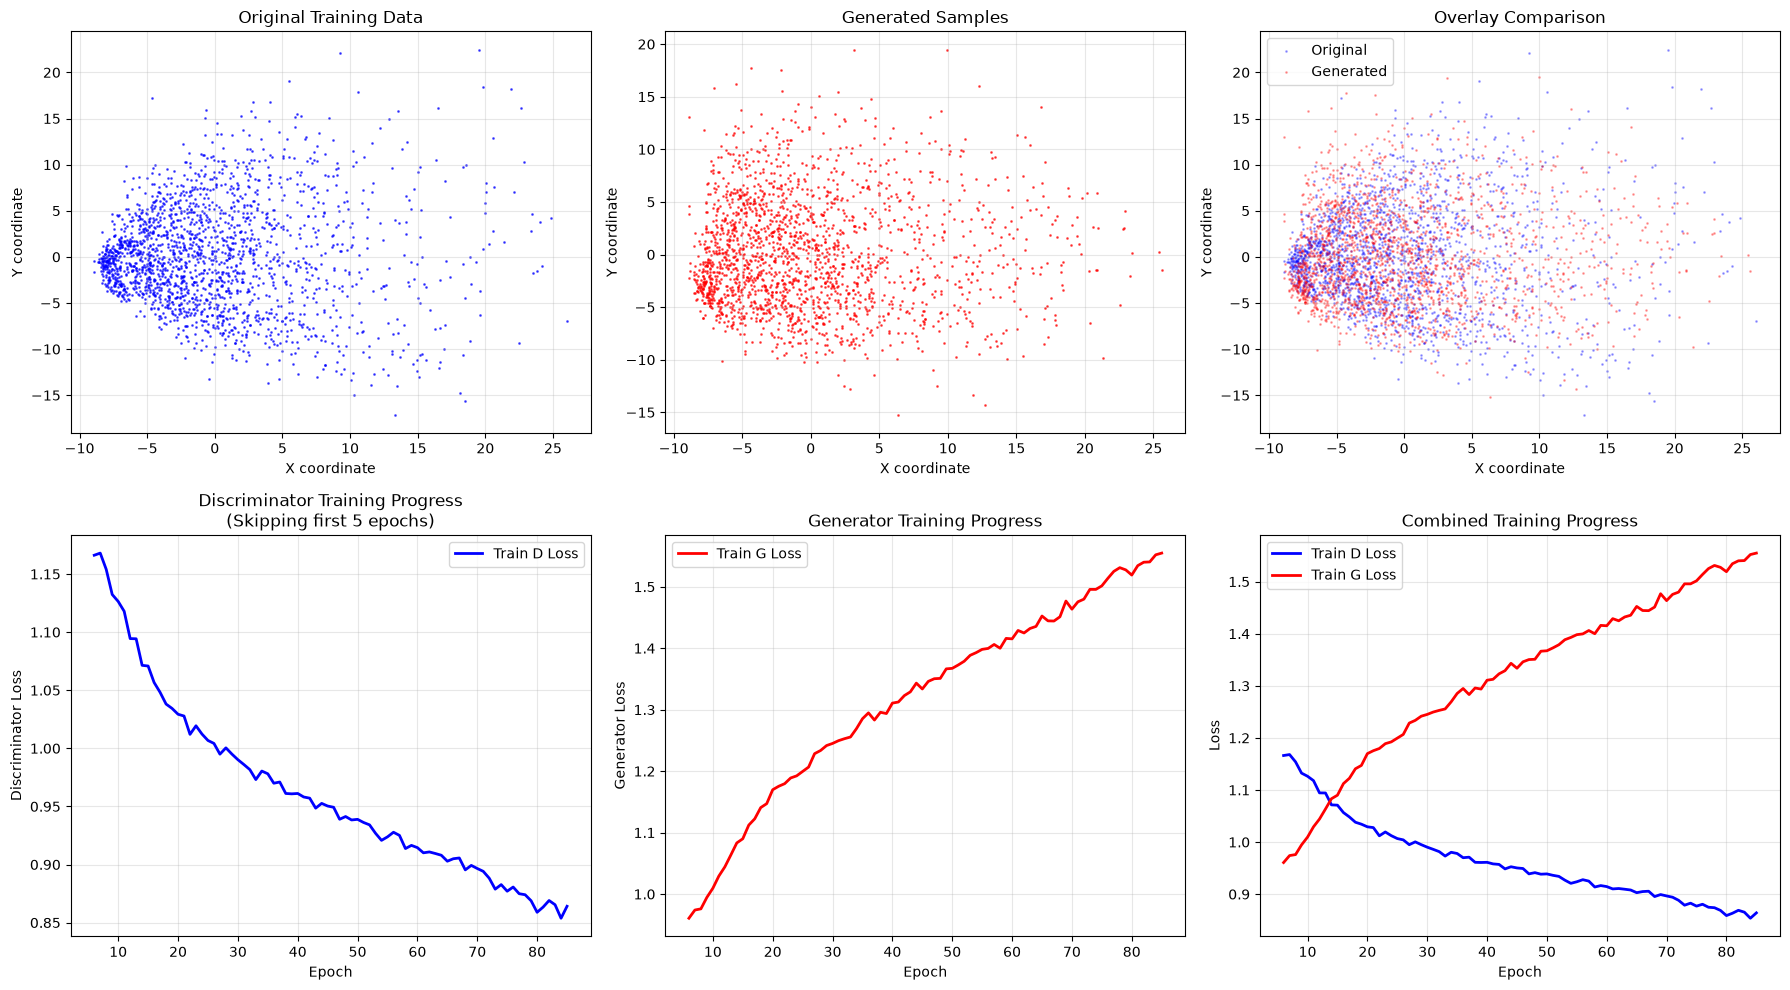

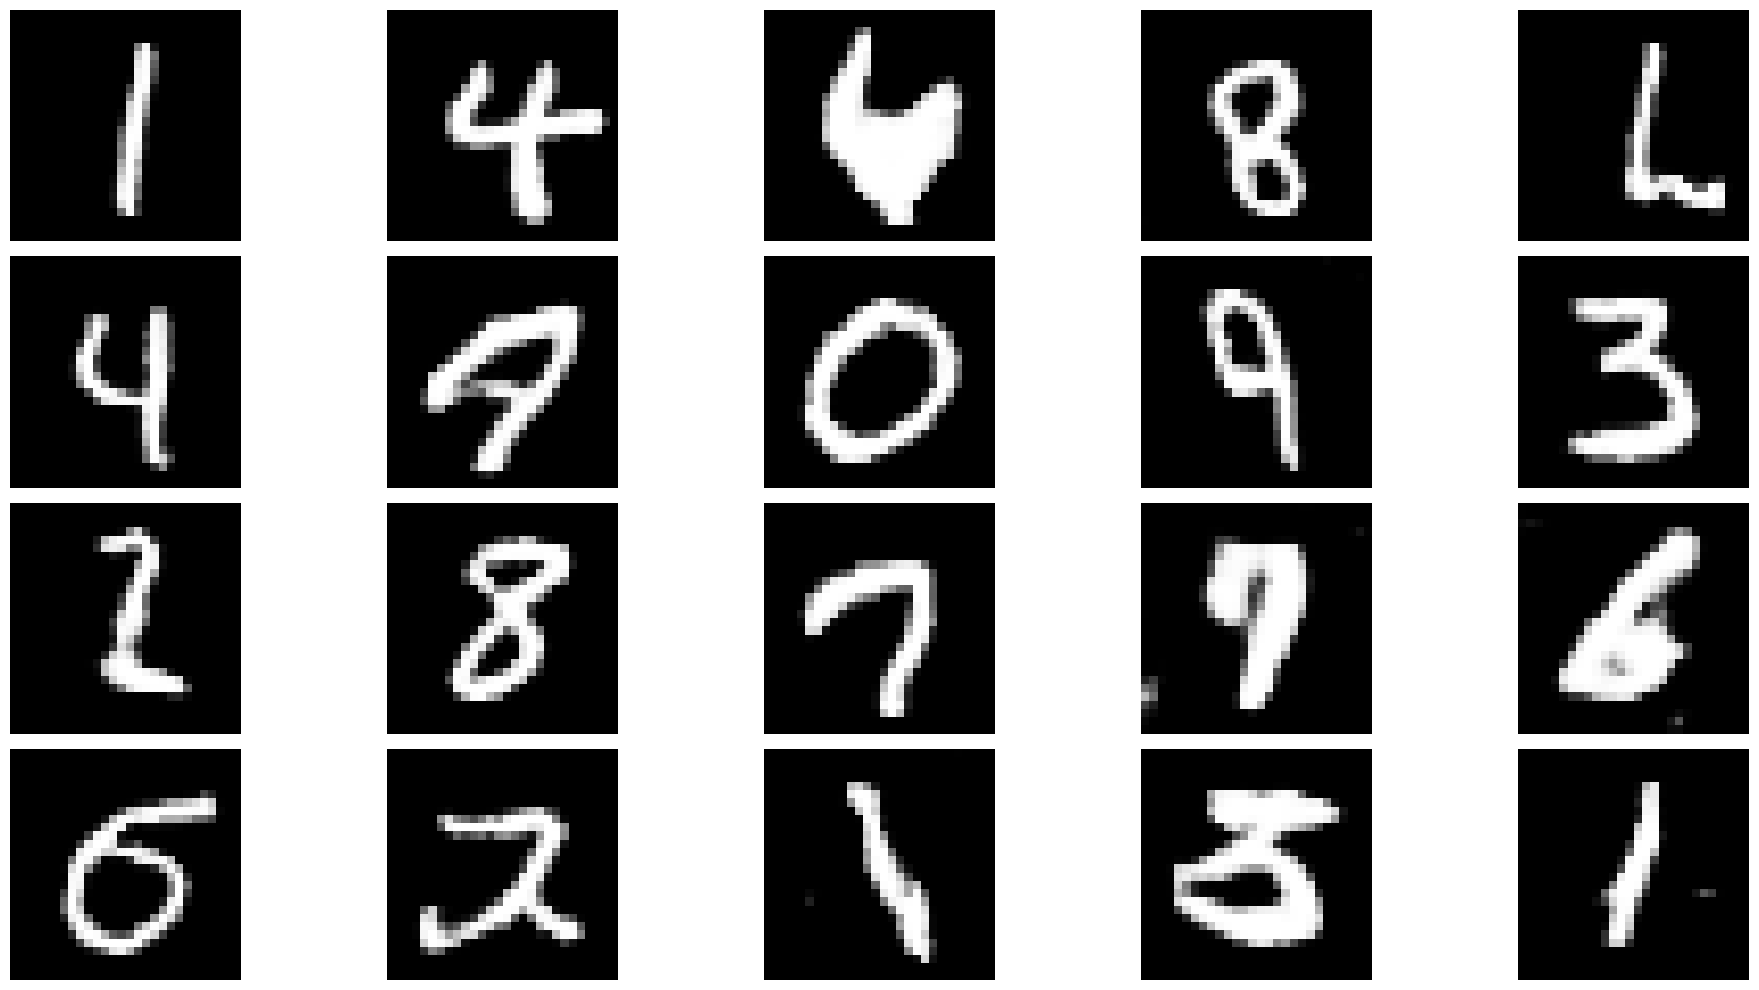

📈 Epoch 85 Summary:
   Train D Loss: 0.8641, Val D Loss: 1.1923
   Train G Loss: 1.5548, Val G Loss: 1.6427

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.792238	G_loss: 1.598199
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.766079	G_loss: 1.103848
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.877010	G_loss: 1.327252
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.839084	G_loss: 1.920198
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.890552	G_loss: 2.013627
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.843473	G_loss: 1.497808
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.727700	G_loss: 2.203749
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.802382	G_loss: 1.309900
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.866884	G_loss: 1.765974
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.953911	G_loss: 1.964388
====> Epoch: 86 Train D_loss: 0.8555, Train G_loss: 1.5557
====> Epoch: 86 Val D_loss: 1.3871, Val G_loss: 2.0981
📈 Epoch 86 Summary:
   Train D Loss: 0.8555, Val D Loss: 1.3871
   Train G Loss: 1.5557

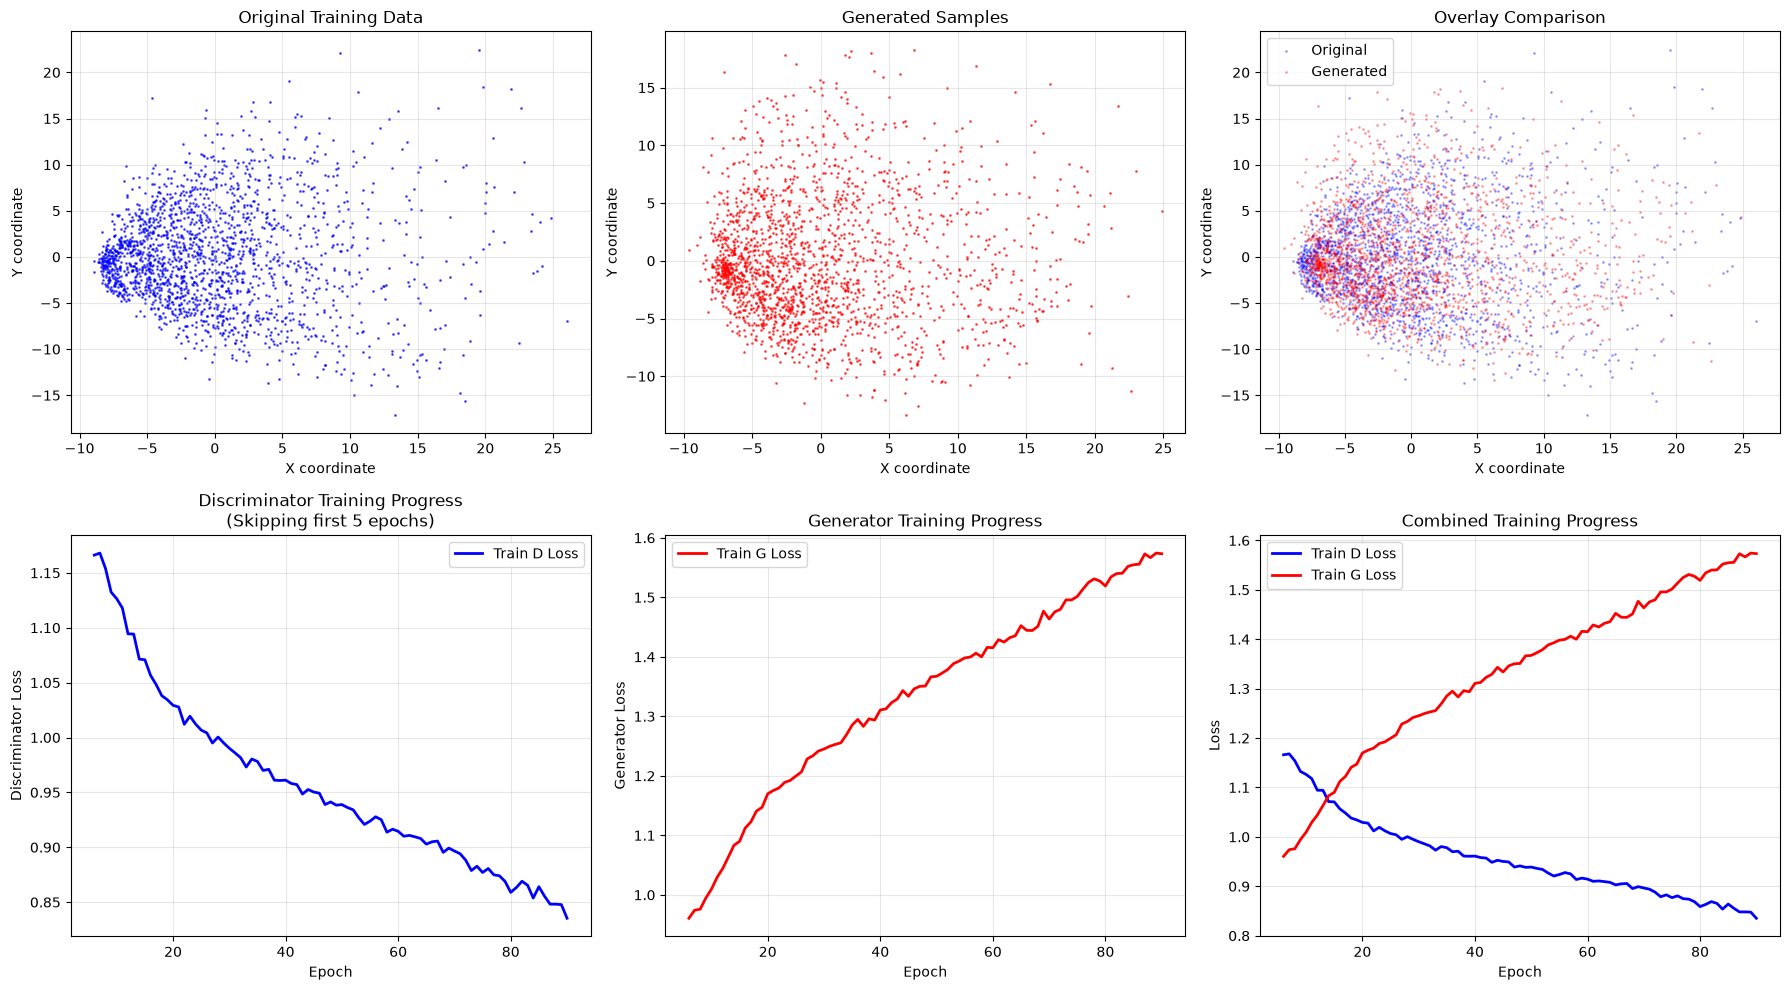

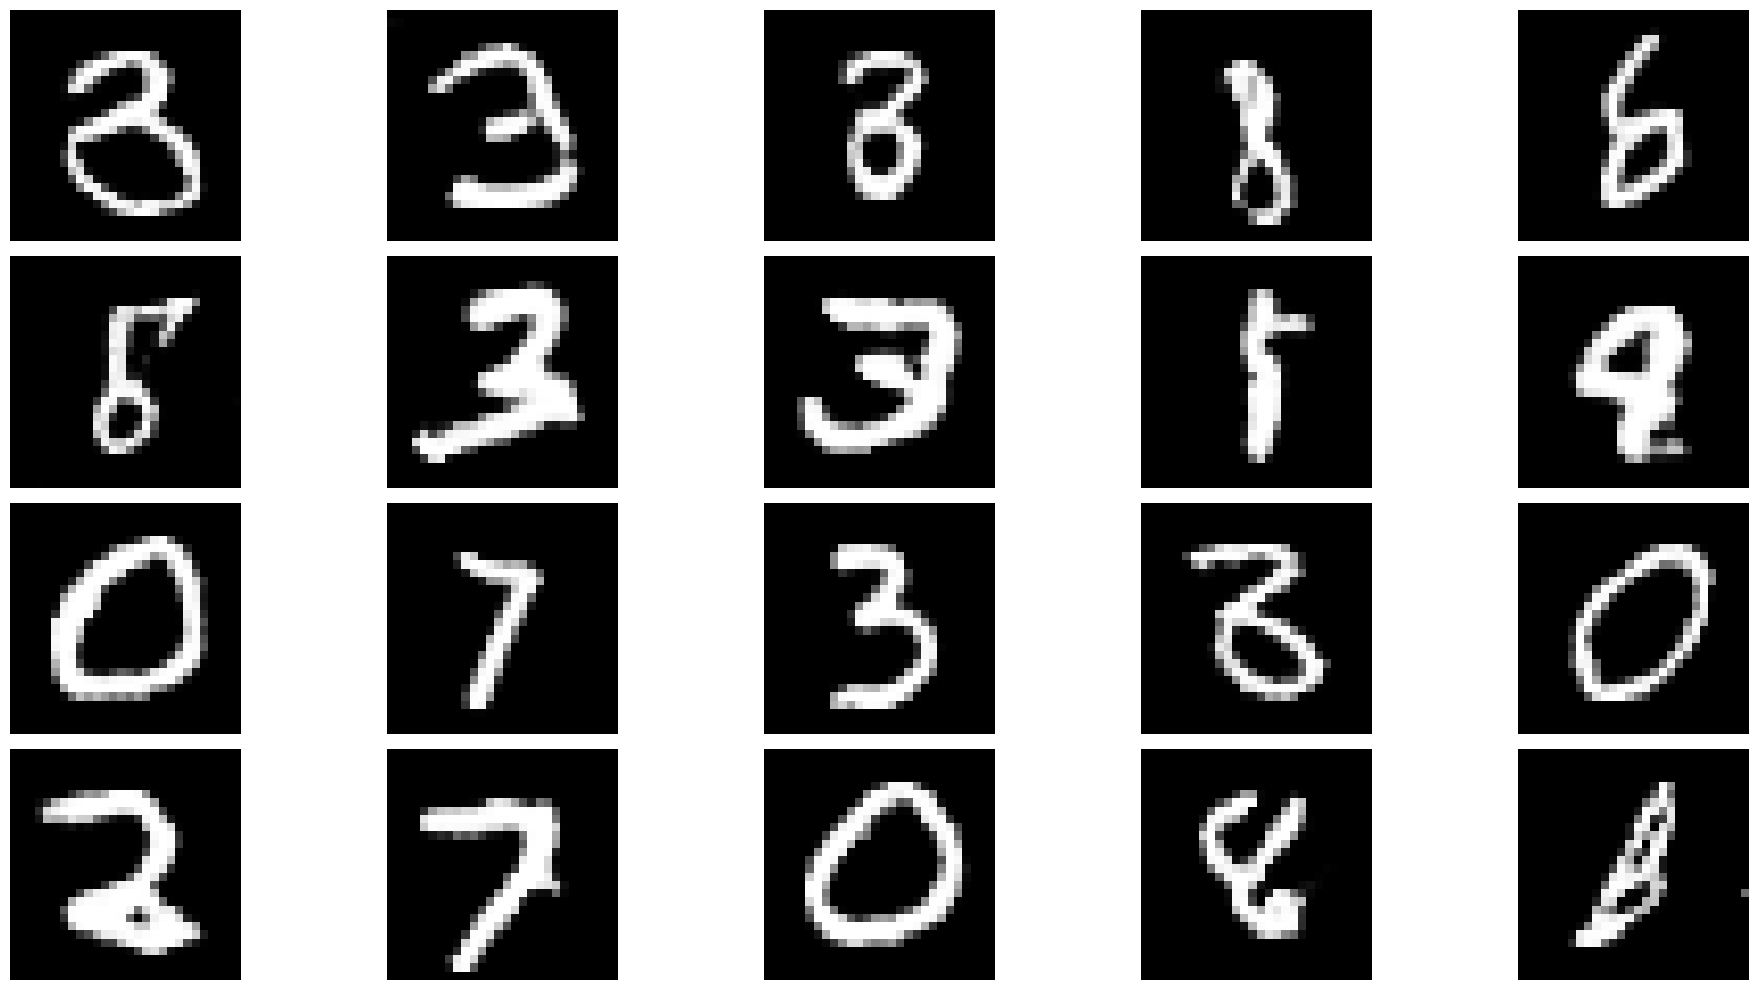

📈 Epoch 90 Summary:
   Train D Loss: 0.8354, Val D Loss: 1.4963
   Train G Loss: 1.5733, Val G Loss: 2.3535

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.815302	G_loss: 1.459476
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.753483	G_loss: 1.806352
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.918015	G_loss: 0.927998
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.791870	G_loss: 1.386803
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.997856	G_loss: 0.752015
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.799352	G_loss: 1.506365
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.861544	G_loss: 2.234541
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.812708	G_loss: 0.694517
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.781673	G_loss: 1.199773
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.926007	G_loss: 1.593432
====> Epoch: 91 Train D_loss: 0.8397, Train G_loss: 1.5980
====> Epoch: 91 Val D_loss: 1.1646, Val G_loss: 1.3627
📈 Epoch 91 Summary:
   Train D Loss: 0.8397, Val D Loss: 1.1646
   Train G Loss: 1.5980

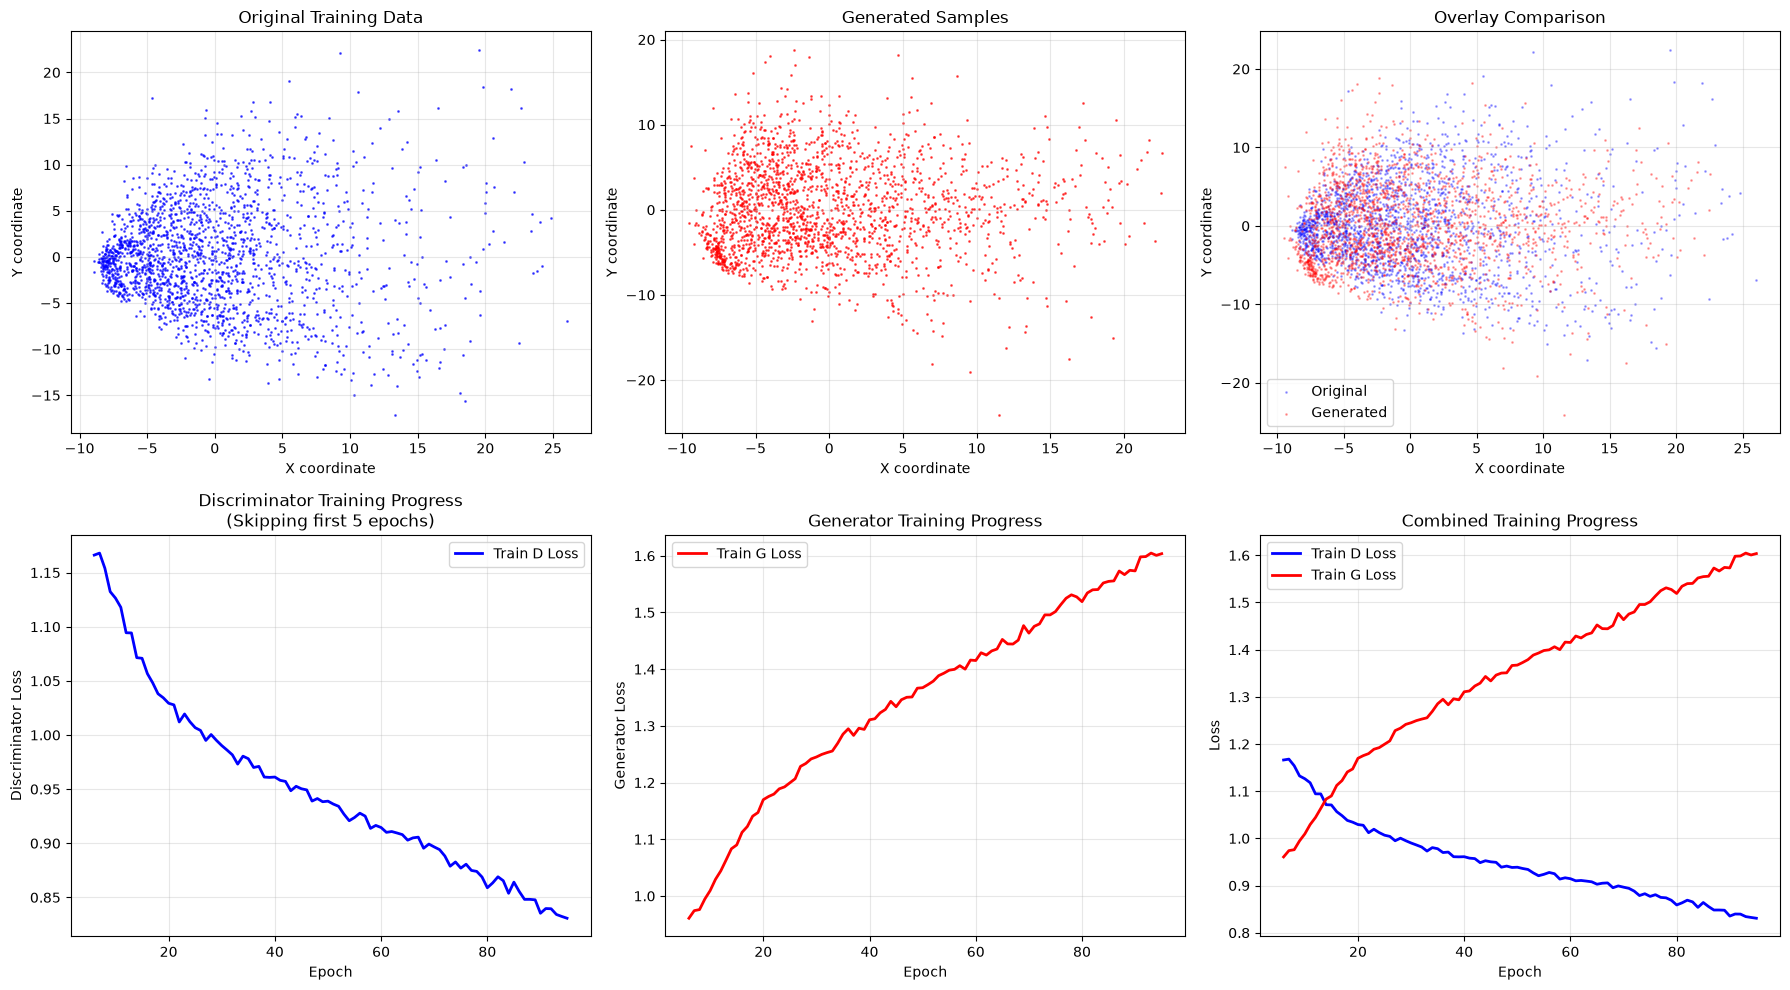

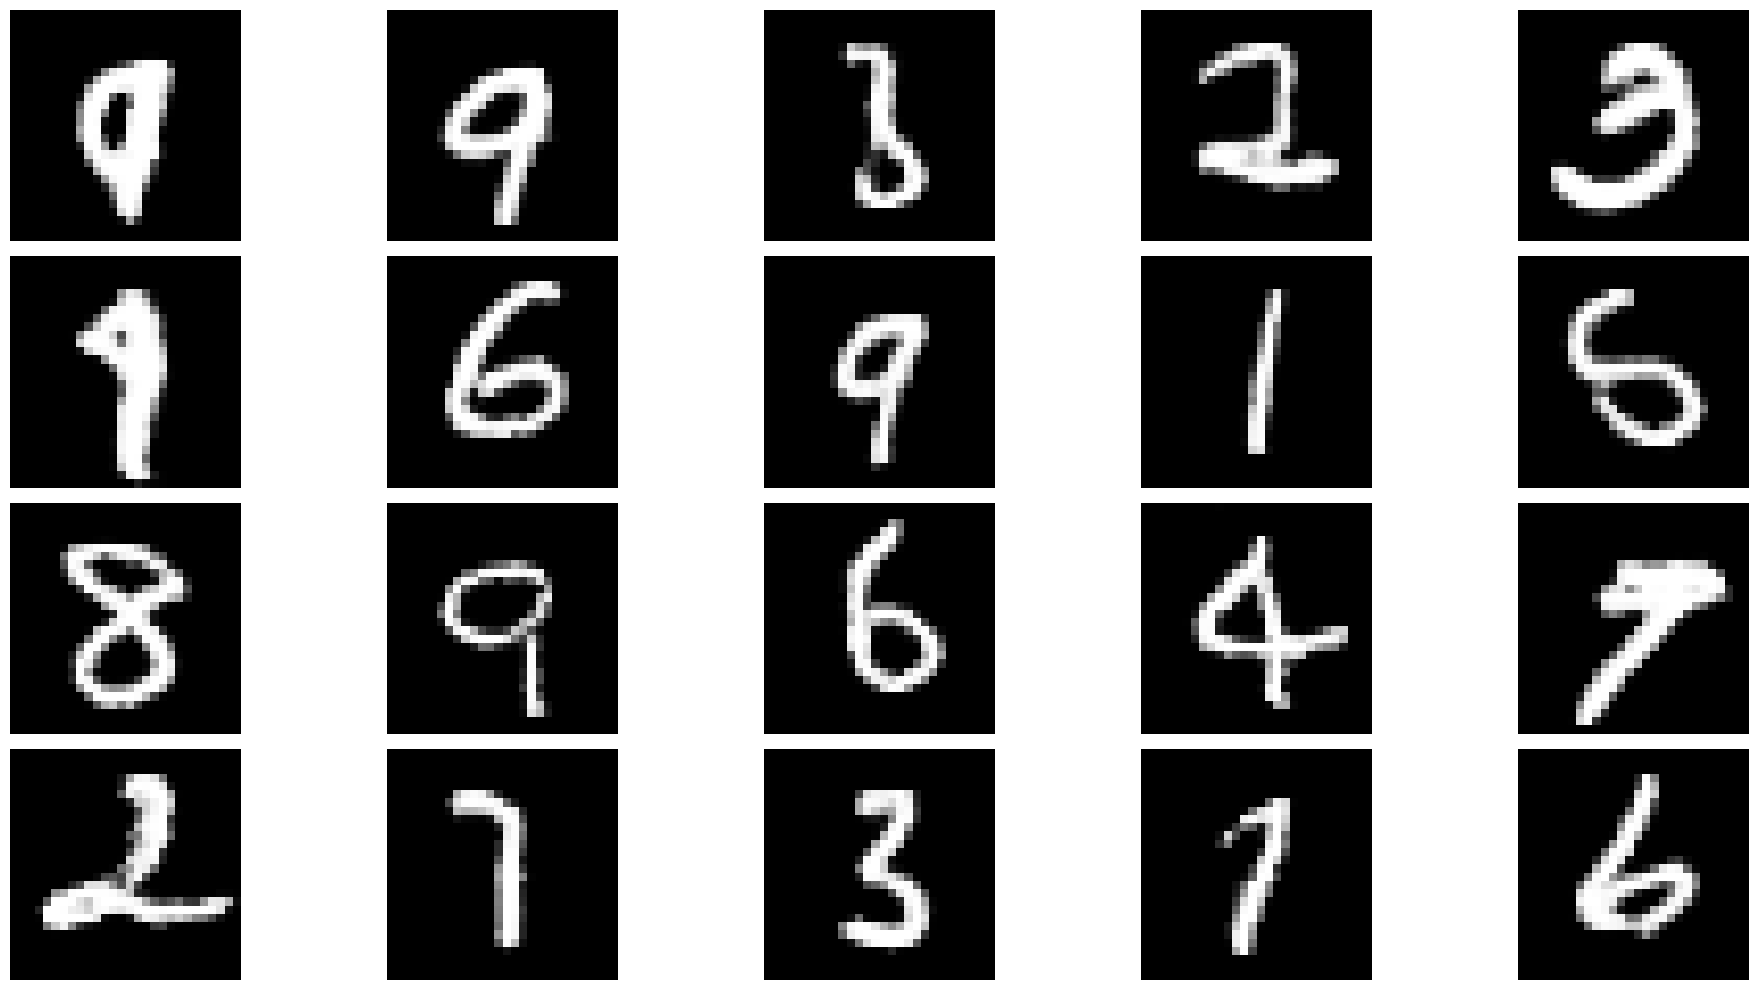

📈 Epoch 95 Summary:
   Train D Loss: 0.8307, Val D Loss: 1.1481
   Train G Loss: 1.6037, Val G Loss: 1.4504

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.753451	G_loss: 1.357056
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.926205	G_loss: 0.972094
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.788425	G_loss: 1.591789
Epoch: 96 [19200/60000 (32%)]	D_loss: 1.056400	G_loss: 0.965439
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.717169	G_loss: 1.379214
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.732986	G_loss: 2.073884
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.810938	G_loss: 1.292096
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.825116	G_loss: 1.461442
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.886628	G_loss: 1.219217
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.906256	G_loss: 1.263204
====> Epoch: 96 Train D_loss: 0.8381, Train G_loss: 1.6251
====> Epoch: 96 Val D_loss: 1.5295, Val G_loss: 0.4738
📈 Epoch 96 Summary:
   Train D Loss: 0.8381, Val D Loss: 1.5295
   Train G Loss: 1.6251

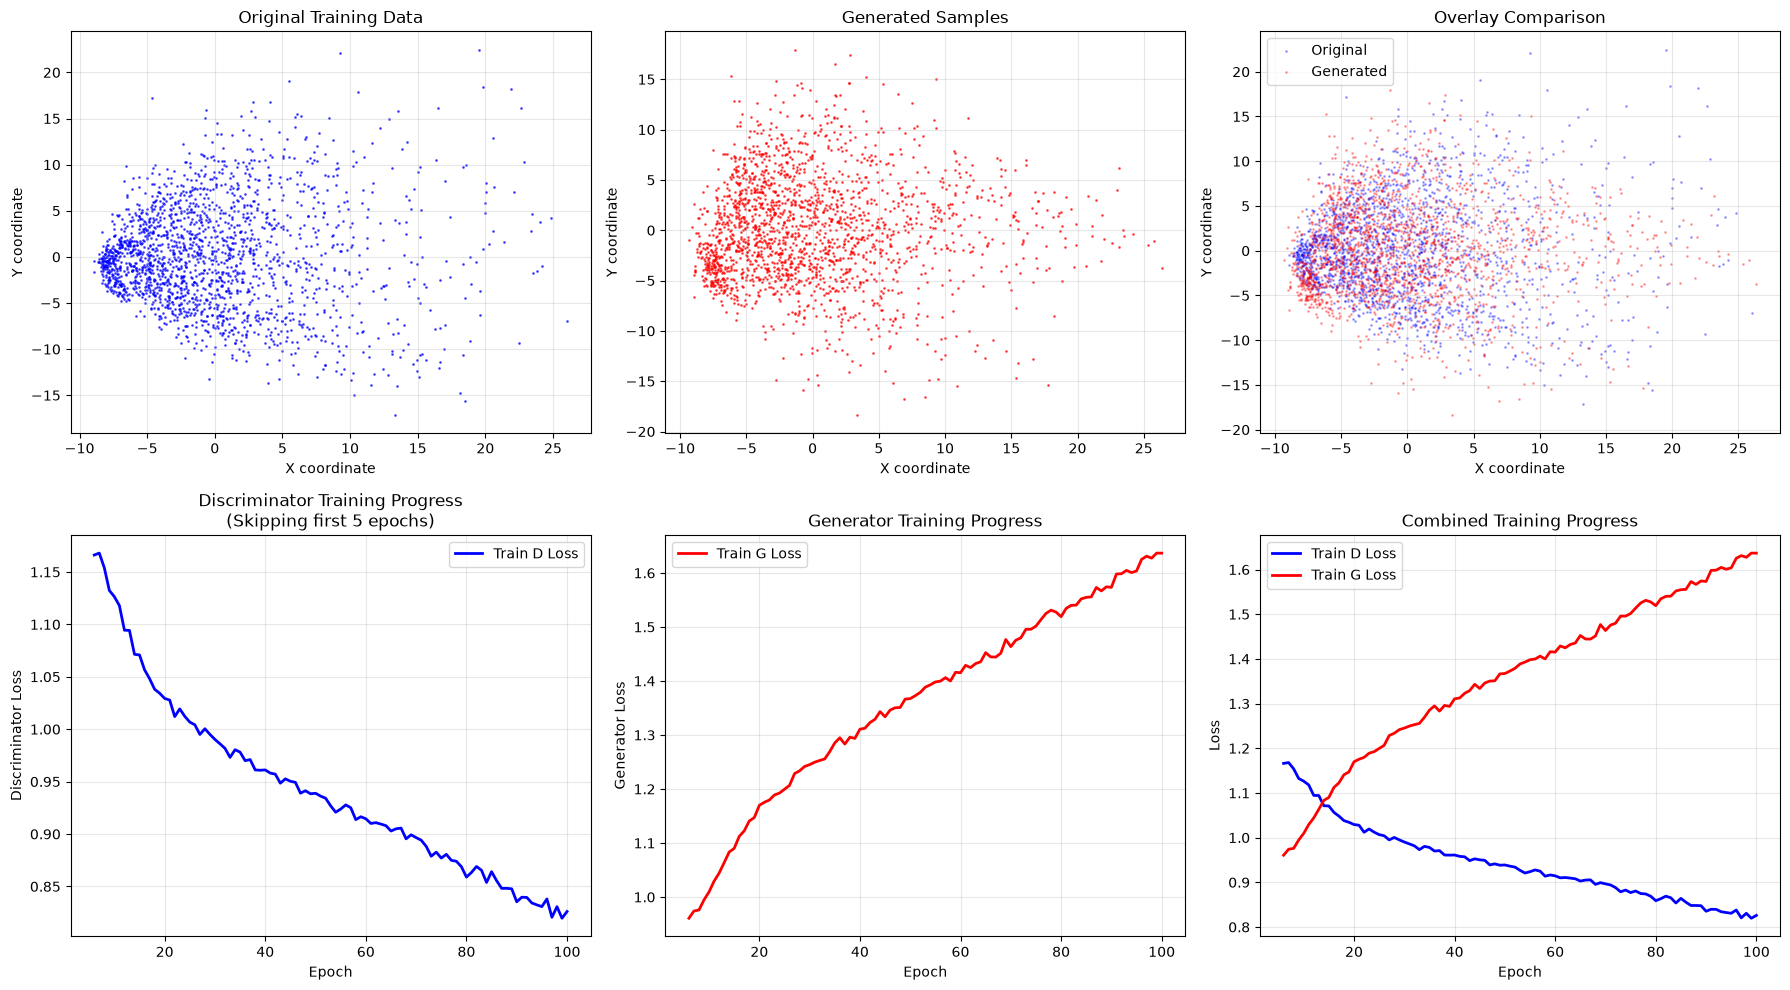

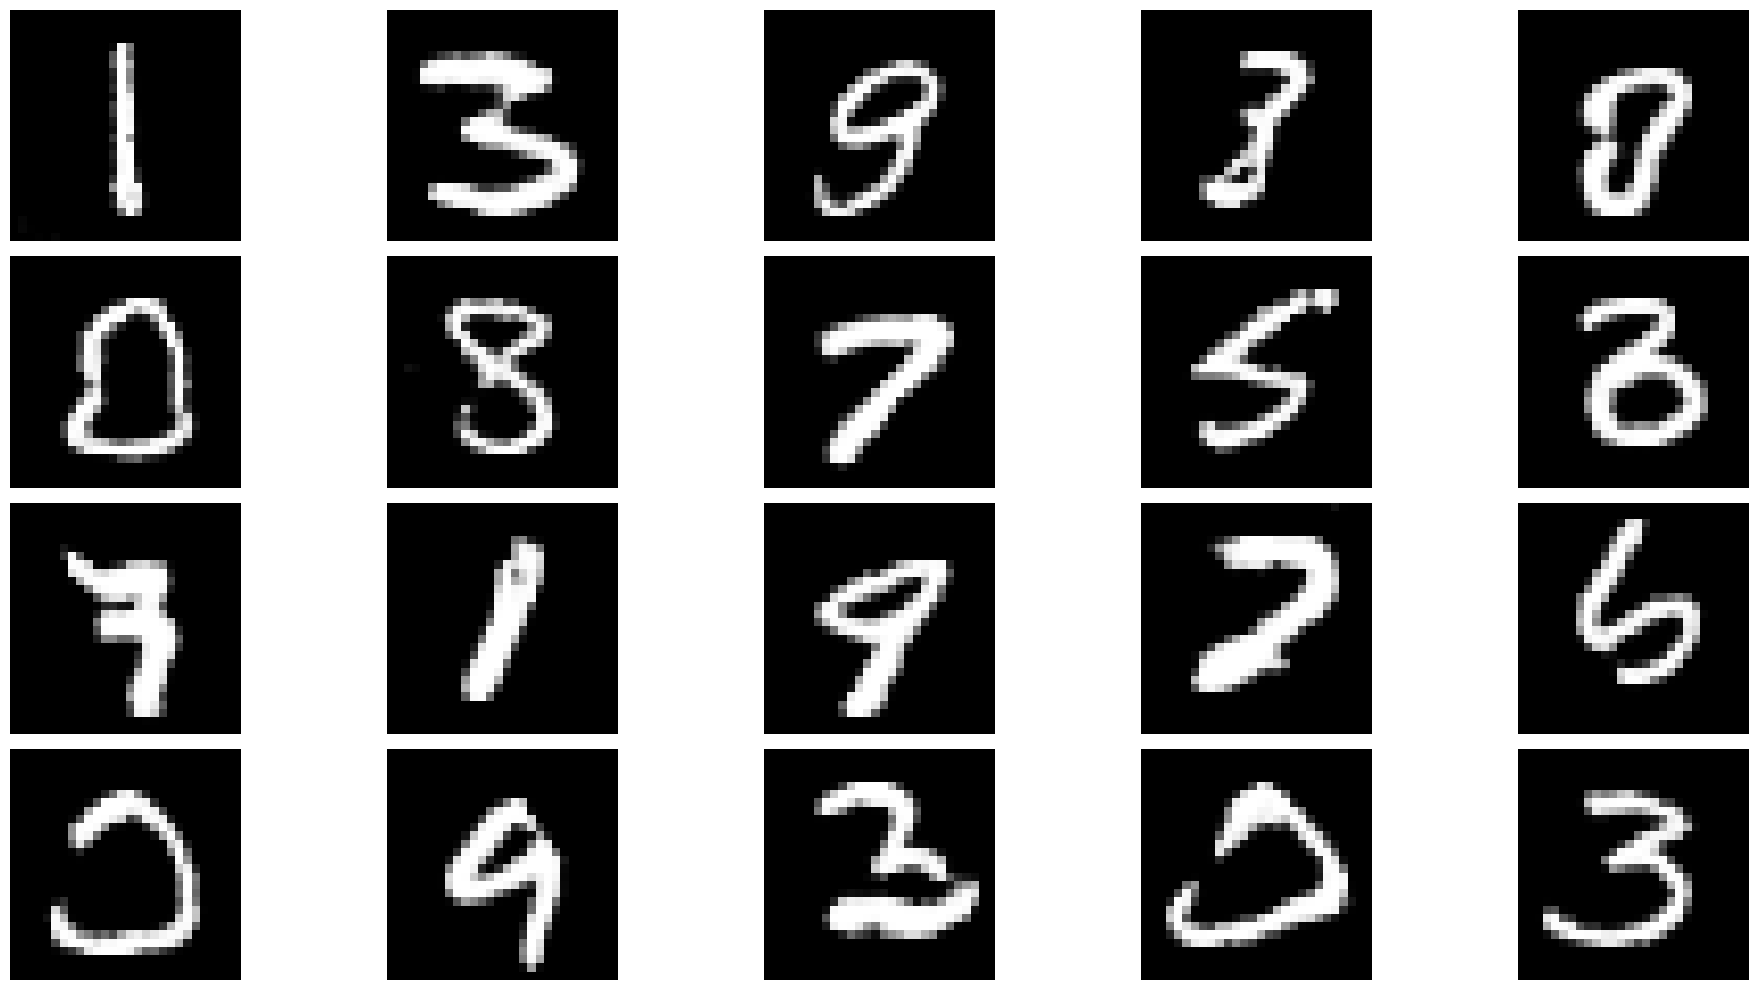

📈 Epoch 100 Summary:
   Train D Loss: 0.8261, Val D Loss: 1.3924
   Train G Loss: 1.6367, Val G Loss: 0.5839

🎉 Training completed!

🎨 Final comprehensive visualization:


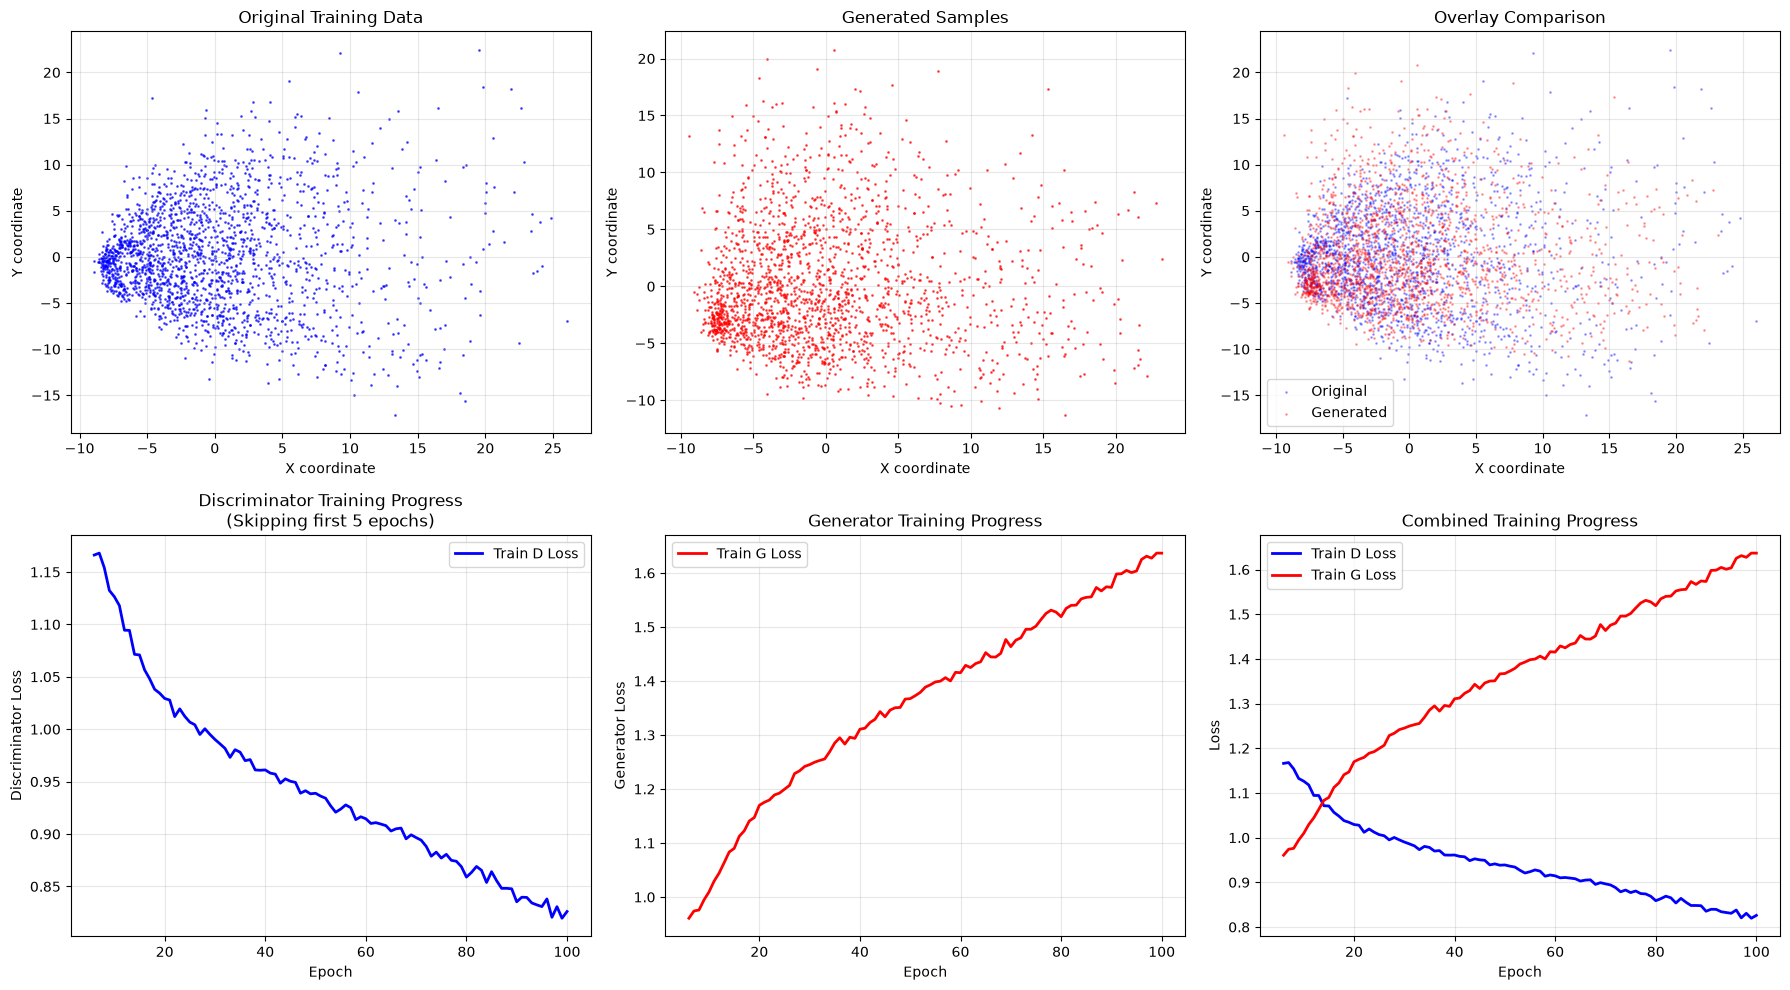

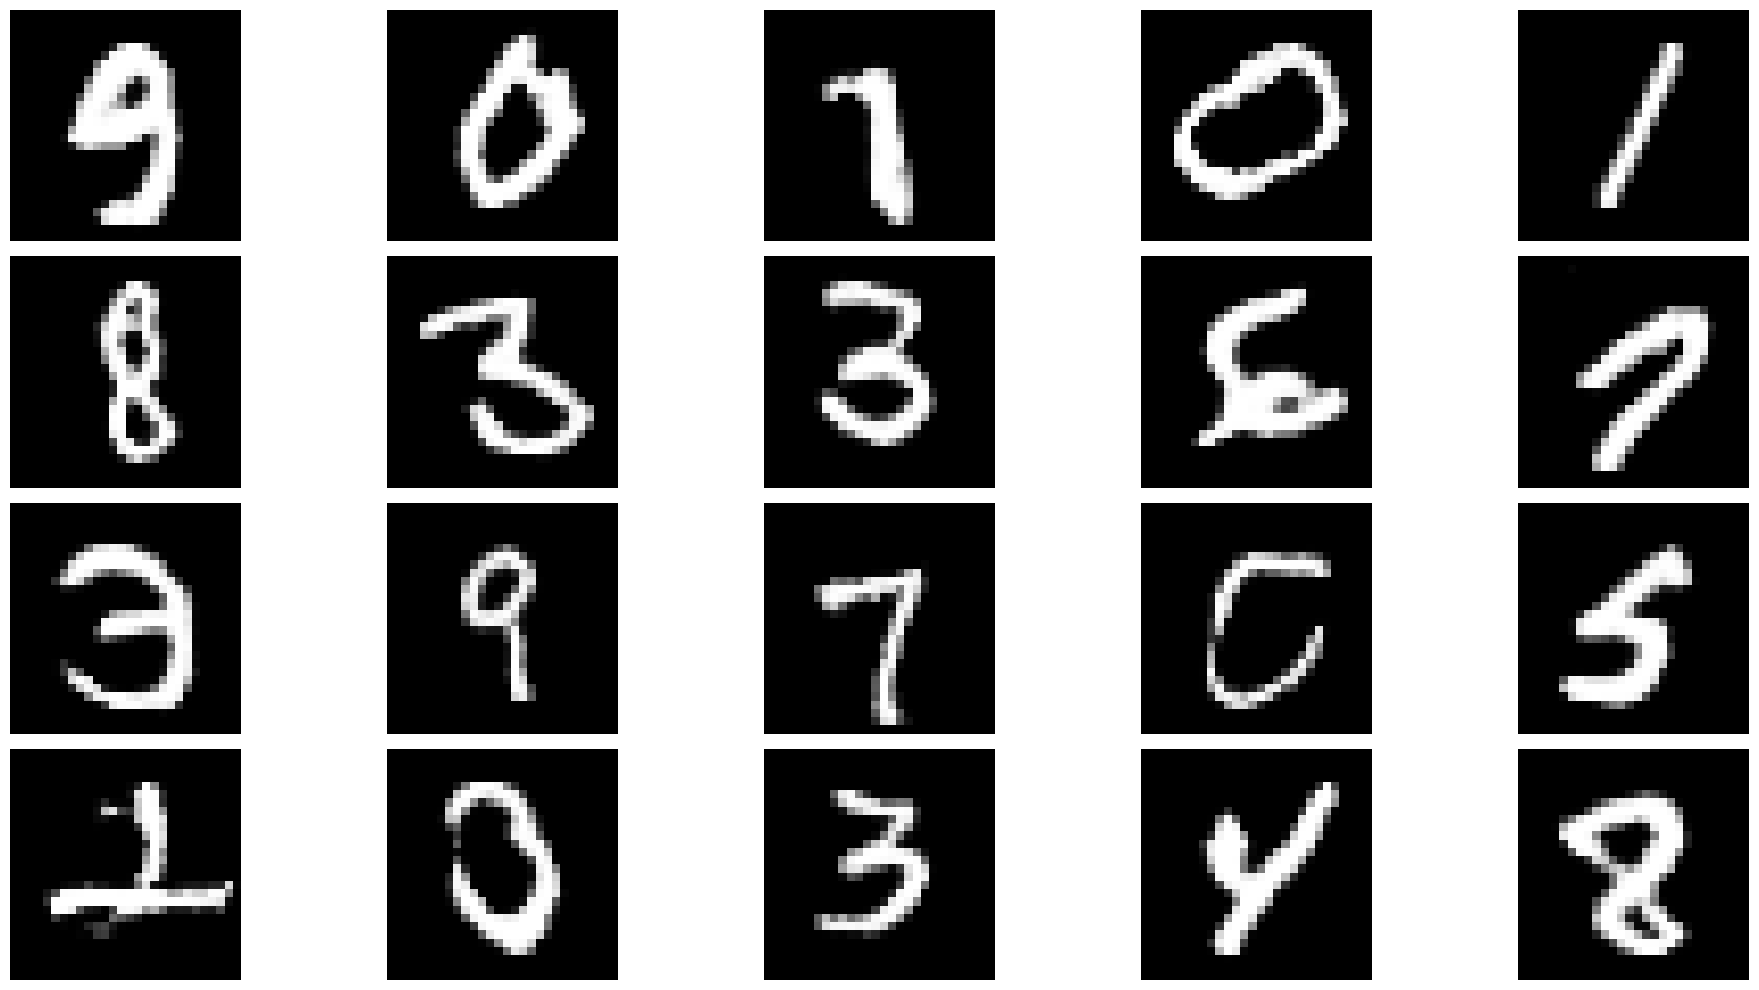

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


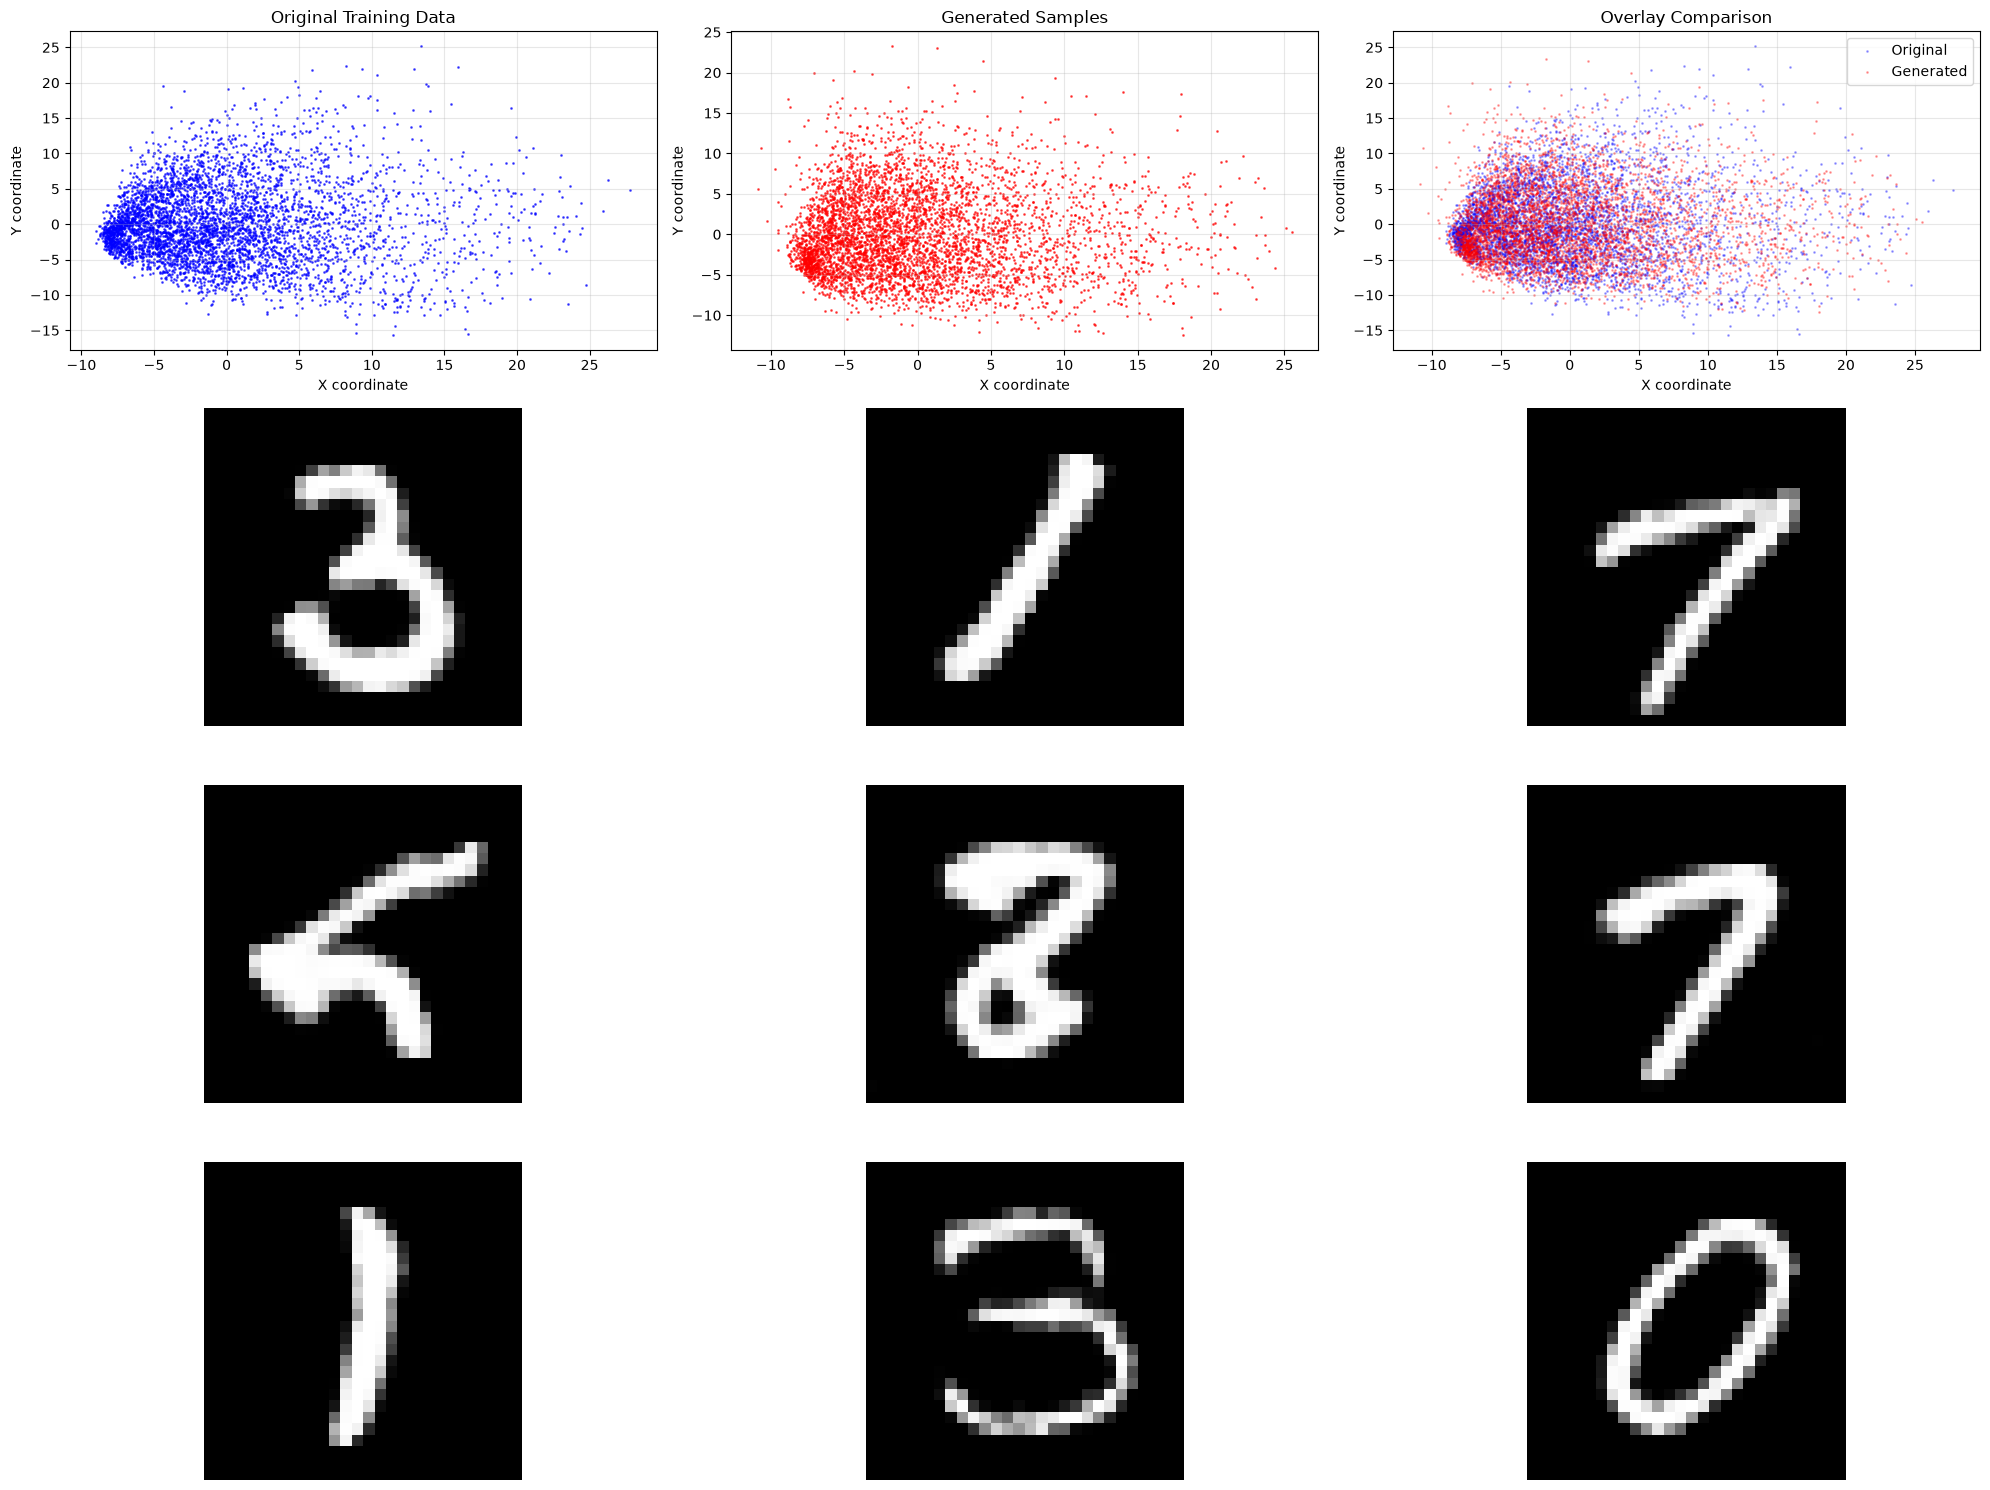

Real data confidence: 0.862
Fake data confidence: 0.600


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
